# 04 · Modern models and comparative diagnostics

**Question.** Do task-compatible modern imputation mechanisms improve on the observed baseline trade-offs under the same causal input boundary, target IDs and measured compute limits?

This notebook first reproduces all baseline predictions and preprocessing fixtures. It then tests the fixed observable-age control motivated by Notebook 03, examines existing mechanisms and builds the selected modern comparisons. Protected calibration, temporal/group locked and external labels remain unused. Development diagnostics are exploratory and do not establish superiority of any proposed model.

In [1]:
from pathlib import Path
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "Notebooks":
    ROOT = ROOT.parent
assert ROOT.is_dir()
REFINED = ROOT / "Data/Interim/development_minutes_refined"
RUN = "guldana_n3_20261007_v01"
TABLES = ROOT / "Tables" / RUN / "04_modern_comparisons"
FIGURES = ROOT / "Figures/PNG" / RUN
for directory in [TABLES, FIGURES, ROOT / "Data/Interim/timestamp_index"]:
    directory.mkdir(parents=True, exist_ok=True)
font_path = font_manager.findfont("Times New Roman", fallback_to_default=False)
assert Path(font_path).is_file()
mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
                     "axes.titlesize": 20, "axes.labelsize": 18,
                     "xtick.labelsize": 18, "ytick.labelsize": 18,
                     "legend.fontsize": 18, "figure.dpi": 350,
                     "savefig.dpi": 350, "axes.unicode_minus": True,
                     "pdf.fonttype": 42, "ps.fonttype": 42})
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)


# Keep HTML tables compact; publication font requirements apply to Matplotlib figures.
def table(frame, name, caption, precision=4):
    frame.to_csv(TABLES / (name + ".csv"), index=False)
    frame.to_latex(TABLES / (name + ".tex"), index=False, caption=caption,
                   float_format=lambda x: f"{x:.{precision}f}")
    def signed_number(x):
        rounded = round(float(x), precision)
        return f"{0.0 if rounded == 0 else rounded:.{precision}f}".replace("-", "−")
    formatters = {col: signed_number for col in frame.select_dtypes(include="floating").columns}
    display(frame.style.format(formatters, na_rep="Unavailable").hide(axis="index").set_caption(caption))
# Figure export verifies the real font, all text sizes and PNG density before inline display.
from IPython.display import Image
from PIL import Image as PILImage
import matplotlib.dates as mdates
from matplotlib.text import Text
FIGURE_PNG = ROOT / "Figures/PNG" / RUN
FIGURE_PDF = ROOT / "Figures/PDF" / RUN
FIGURE_PNG.mkdir(parents=True, exist_ok=True)
FIGURE_PDF.mkdir(parents=True, exist_ok=True)
figure_qa = []
def save_figure(fig, name):
    fig.canvas.draw()
    texts = [t for t in fig.findobj(Text) if t.get_visible() and t.get_text().strip()]
    for text_item in texts:
        assert 18 <= text_item.get_fontsize() <= 20, (text_item.get_text(), text_item.get_fontsize())
        resolved = font_manager.findfont(text_item.get_fontproperties(), fallback_to_default=False)
        assert font_manager.FontProperties(fname=resolved).get_name() == "Times New Roman"
    png = FIGURE_PNG / f"{name}.png"
    pdf = FIGURE_PDF / f"{name}.pdf"
    fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.06)
    fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.06)
    with PILImage.open(png) as im:
        assert all(abs(d - 350) < .02 for d in im.info["dpi"])
        figure_qa.append({"Figure": name, "Width px": im.width, "Height px": im.height, "DPI": im.info["dpi"][0],
                          "Font": "Times New Roman", "Text items checked": len(texts)})
    plt.close(fig)
    display(Image(filename=str(png)))


gate = json.loads((ROOT / "Manifests/nb01_gate.json").read_text())
assert gate["status"] == "primary_development_data_adequate_for_nb02"
schema = json.loads((ROOT / "Configs/sensor_schema.json").read_text())
semantic_map = pd.read_csv(ROOT / "Data/Interim/sensor_semantic_map.csv")
PREP = ROOT / "Models/preprocessing" / RUN
PREP.mkdir(parents=True,exist_ok=True)

import time, os, platform, resource
import torch
from sklearn.linear_model import Ridge, HuberRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor
import joblib
NB02_GATE=json.loads((ROOT / "Manifests/nb02_gate.json").read_text())
assert NB02_GATE["status"]=="development_preprocessing_ready_for_clean_kernel_reload"
MODEL_DIR=ROOT / "Models/baselines" / RUN
PRED_DIR=ROOT / "Predictions/development" / RUN
for directory in [MODEL_DIR,PRED_DIR]:directory.mkdir(parents=True,exist_ok=True)

import yaml, gc
BASELINE_DIR=MODEL_DIR
BASELINE_PRED_DIR=PRED_DIR
PRED_DIR=ROOT/"Predictions/development_modern"/RUN
PRED_DIR.mkdir(parents=True,exist_ok=True)
NB03_GATE=json.loads((ROOT/"Manifests/nb03_gate.json").read_text())
assert NB03_GATE["status"]=="baseline_development_complete_pending_next_kernel_reload"
compute_protocol=yaml.safe_load((ROOT/"Configs/compute_protocol.yaml").read_text())
assert compute_protocol["modeling_id_sha256"]==NB03_GATE["modeling_id_sha256"]
modeling_ids=pd.read_parquet(ROOT/compute_protocol["modeling_id_file"])
assert hashlib.sha256((ROOT/compute_protocol["modeling_id_file"]).read_bytes()).hexdigest()==compute_protocol["modeling_id_sha256"]
CLASSICAL_NAMES=list(yaml.safe_load((ROOT/"Configs/search_spaces.yaml").read_text())["classical_baselines"])
CACHE=ROOT/"Data/Processed"/RUN/"modeling_inputs"
INPUT_CONTRACT="masked_sensor_v1_exact_fixtures"


In [3]:
# Complete scientific tables: semantic groups, unchanged values, mathematical minus.
# This display-only setup does not fit models or modify numerical exports.
import copy as _table_copy
import re as _table_re
import pandas as _table_pd
from bs4 import BeautifulSoup as _TableSoup, NavigableString as _TableText
from pandas.io.formats.style import Styler as _TableStyler
from IPython.display import HTML as _TableHTML
import hashlib as _table_hashlib, json as _table_json
_table_layout_bytes = (ROOT / "Configs/article_table_layout.json").read_bytes()
assert _table_hashlib.sha256(_table_layout_bytes).hexdigest() == "fbbb6522e8c59dbde1eea0021da0a6f72e3257d1c6d0c8d49e74c5bd3a6a9d8c"
_ARTICLE_TABLE_GROUPS = _table_json.loads(_table_layout_bytes)
_ARTICLE_NUMBER = _table_re.compile(r"^\s*[+−-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+−-]?\d+)?%?\s*$")
def _article_table_layout(tag, additions):
    declarations = dict(part.strip().split(":", 1) for part in tag.get("style", "").split(";") if ":" in part)
    declarations.update(additions)
    tag["style"] = ";".join(key + ":" + value for key, value in declarations.items()) + ";"
def _article_table_html(html):
    soup = _TableSoup(html, "html.parser")
    for table in list(soup.find_all("table")):
        head = table.find("thead")
        body = table.find("tbody")
        if head is None or body is None:
            continue
        heads = [tag.get_text(strip=True) for tag in head.find_all("th")]
        rule = _ARTICLE_TABLE_GROUPS.get("|".join(heads))
        if rule is not None and len(head.find_all("tr")) == 1:
            rows = body.find_all("tr", recursive=False)
            if all(len(row.find_all(["th", "td"], recursive=False)) == len(heads) for row in rows):
                assert set(sum(rule["columns"], [])) == set(heads)
                original_styles = [style.get_text() for style in soup.find_all("style")]
                for number, (columns, label) in enumerate(zip(rule["columns"], rule["labels"]), 1):
                    part = _table_copy.deepcopy(table)
                    keep = [heads.index(name) for name in columns]
                    for row in part.find_all("tr"):
                        for index, tag in enumerate(row.find_all(["th", "td"], recursive=False)):
                            if index not in keep:
                                tag.decompose()
                    caption = part.find("caption")
                    if caption is None:
                        caption = soup.new_tag("caption")
                        part.insert(0, caption)
                    caption.append(" " + label)
                    suffix = "_article_part_" + str(number)
                    original_id = table.get("id")
                    for tag in [part] + part.find_all(True):
                        if tag.has_attr("id"):
                            tag["id"] = (tag["id"].replace(original_id, original_id + suffix, 1)
                                         if original_id and tag["id"].startswith(original_id) else tag["id"] + suffix)
                    if original_id:
                        for style_text in original_styles:
                            if "#" + original_id in style_text:
                                copied_style = soup.new_tag("style")
                                copied_style.string = style_text.replace("#" + original_id, "#" + original_id + suffix)
                                table.insert_before(copied_style)
                    table.insert_before(part)
                table.decompose()
    for table in soup.find_all("table"):
        _article_table_layout(table, {"max-width":"100%", "table-layout":"auto", "margin-bottom":"1.4em"})
        for tag in table.find_all(["th", "td", "caption"]):
            _article_table_layout(tag, {"white-space":"normal", "vertical-align":"top"})
            if tag.name == "caption":
                _article_table_layout(tag, {"text-align":"left", "caption-side":"top"})
            for old_break in list(tag.find_all("wbr")):
                old_break.decompose()
            for node in list(tag.descendants):
                if not isinstance(node, _TableText) or node.parent.name in {"code", "pre", "script", "style"}:
                    continue
                text = str(node)
                if tag.name == "td" and _ARTICLE_NUMBER.fullmatch(text):
                    text = text.replace("-", "−")
                chunks = _table_re.split("(?<=_)", text)
                for index, chunk in enumerate(chunks):
                    node.insert_before(_TableText(chunk))
                    if index + 1 < len(chunks):
                        node.insert_before(soup.new_tag("wbr"))
                node.extract()
    return str(_TableSoup(str(soup), "html.parser"))
def _article_styler_html(value):
    with _table_pd.option_context("styler.render.max_elements", max(1, value.data.size + len(value.data)),
                                  "styler.render.max_rows", None, "styler.render.max_columns", None):
        html = value.to_html(max_rows=len(value.data), max_columns=len(value.data.columns))
    assert not _TableSoup(html, "html.parser").select(".row_trim, .col_trim"), "Scientific table was truncated"
    return _article_table_html(html)
def _article_frame_html(value):
    return _article_table_html(value.to_html(max_rows=None, max_cols=None))
def _article_HTML_html(value):
    result = value._repr_html_()
    if isinstance(result, tuple):
        return _article_table_html(result[0]), result[1]
    return _article_table_html(result)
_table_format = get_ipython().display_formatter.formatters["text/html"]
_table_format.for_type(_TableStyler, _article_styler_html)
_table_format.for_type(_table_pd.DataFrame, _article_frame_html)
_table_format.for_type(_TableHTML, _article_HTML_html);


## 1. Reproduction of baseline predictions

The saved baseline models are loaded without retraining, and the full 40,960-observation OOF vector is reproduced for each fold and seed. Array equality is exact, including ExtraTrees deterministic one-thread reduction. The seven naive controls are also reproduced from their saved numerical states. Shared feature construction is tested independently afterward.

In [2]:
# Explicit prediction definitions and verified cache loader; no fitting occurs.
def load_modeling_inputs(fold,seed):
    stem=f"fold_{fold}_seed_{seed}";record=json.loads((CACHE/f"{stem}.json").read_text())
    assert record["modeling_id_sha256"]==compute_protocol["modeling_id_sha256"]
    for kind in ["array","metadata"]:
        assert hashlib.sha256((ROOT/record[f"{kind}_file"]).read_bytes()).hexdigest()==record[f"{kind}_sha256"]
    with np.load(ROOT/record["array_file"],allow_pickle=False) as arrays:
        x=arrays["x"].copy();raw=pd.DataFrame(arrays["raw"],columns=arrays["input_columns"])
        columns=arrays["transformed_columns"].tolist()
    return x,raw,pd.read_parquet(ROOT/record["metadata_file"]),columns

# Fit seven interpretable controls using only the common training-target IDs.
NAIVE_NAMES=["Median","Last valid aggregate","Seasonal median","Previous day","Previous week",
             "Partial appliance sum","Partial sum + residual"]
def predict_naive(state,raw,metadata):
    house=metadata.house.to_numpy();season=(metadata.timestamp.dt.dayofweek*24+metadata.timestamp.dt.hour).to_numpy()
    median=np.array([state["house_medians"].get(str(h),state["global_median"]) for h in house])
    seasonal=np.array([state["seasonal"].get(f"{h}|{s}",
        state["global_seasonal"].get(str(s),median[i])) for i,(h,s) in enumerate(zip(house,season))])
    partial=raw.current_aux_sum.fillna(0).to_numpy(dtype=np.float64)
    residual=np.array([state["residual_house_count"].get(f"{h}|{c}",
        state["residual_house"].get(str(h),state["residual_global"]))
        for h,c in zip(house,metadata.observed_auxiliary_count)])
    def fill(values):return np.where(np.isfinite(values),values,median)
    predictions=np.column_stack([median,fill(raw.aggregate_last.to_numpy(dtype=np.float64)),seasonal,
        fill(raw.aggregate_lag_1440.to_numpy(dtype=np.float64)),
        fill(raw.aggregate_lag_10080.to_numpy(dtype=np.float64)),partial,partial+residual])
    assert np.isfinite(predictions).all()
    return predictions

def regression_summary(metadata,prediction):
    error=prediction-metadata.y_kW.to_numpy(dtype=np.float64)
    per_house=pd.DataFrame({"house":metadata.house,"absolute":np.abs(error),"squared":error**2,
                           "bias":error,"negative":prediction<0}).groupby("house").mean()
    return {"House-macro MAE (kW)":float(per_house.absolute.mean()),
        "House-macro RMSE (kW)":float(np.sqrt(per_house.squared).mean()),
        "Bias (kW)":float(per_house.bias.mean()),"Negative prediction (%)":float(per_house.negative.mean()*100)}



In [3]:
# Reproduce every saved classical and naive OOF prediction in this fresh kernel.
from threadpoolctl import threadpool_limits
baseline_manifest=json.loads((ROOT/"Manifests/baseline_checkpoints.json").read_text())
assert hashlib.sha256((ROOT/"Manifests/baseline_checkpoints.json").read_bytes()).hexdigest()==NB03_GATE["checkpoint_manifest_sha256"]
for record in baseline_manifest:
    for entry in record["files"].values():
        assert hashlib.sha256((ROOT/entry["path"]).read_bytes()).hexdigest()==entry["sha256"]
baseline_reload_rows=[]
def reproduce_baseline_fold(fold):
    rows=[]
    for seed in [17,43,101]:
        x,raw,meta,columns=load_modeling_inputs(fold,seed)
        outer=meta.role.eq("outer_validation").to_numpy()
        outer_meta=meta.loc[outer].reset_index(drop=True);outer_raw=raw.loc[outer].reset_index(drop=True)
        expected=pd.read_parquet(BASELINE_PRED_DIR/f"naive_OOF_fold_{fold}_seed_{seed}.parquet")
        pd.testing.assert_series_equal(outer_meta.observation_id,expected.observation_id)
        state=json.loads((BASELINE_DIR/f"naive_fold_{fold}_seed_{seed}.json").read_text())
        actual=predict_naive(state,outer_raw,outer_meta)
        np.testing.assert_array_equal(actual,expected[NAIVE_NAMES].to_numpy())
        rows.append({"Model":"Seven naive controls","Fold":fold,"Seed":seed,"Compared scalar predictions":int(actual.size),
                     "Maximum absolute difference":float(np.abs(actual-expected[NAIVE_NAMES].to_numpy()).max())})
        for family in CLASSICAL_NAMES:
            bundle=joblib.load(BASELINE_DIR/f"{family}_fold_{fold}_seed_{seed}.joblib")
            selected=[columns.index(name) for name in bundle["feature_columns"]]
            with threadpool_limits(limits=4):actual=bundle["model"].predict(x[outer][:,selected])
            expected=pd.read_parquet(BASELINE_PRED_DIR/f"{family}_fold_{fold}_seed_{seed}.parquet")
            pd.testing.assert_series_equal(outer_meta.observation_id,expected.observation_id)
            np.testing.assert_array_equal(actual,expected.prediction_kW.to_numpy())
            rows.append({"Model":family,"Fold":fold,"Seed":seed,"Compared scalar predictions":len(actual),
                "Maximum absolute difference":float(np.abs(actual-expected.prediction_kW.to_numpy()).max())})
            del bundle
    baseline_reload_rows.extend(rows)
    table(pd.DataFrame(rows),f"baseline_fresh_kernel_reload_fold_{fold}",
        f"Table 1.{fold}. Fresh-kernel reproduction of every saved OOF prediction in fold {fold}.",precision=0)
    return rows


In [4]:
# Independently reload baseline predictions: fold 1.
baseline_reload_fold_1=reproduce_baseline_fold(1)

In [5]:
# Independently reload baseline predictions: fold 2.
baseline_reload_fold_2=reproduce_baseline_fold(2)

In [6]:
# Independently reload baseline predictions: fold 3.
baseline_reload_fold_3=reproduce_baseline_fold(3)

## 2. Observation-contract reproduction

The following readable definitions reproduce the fixed scientific preprocessing explicitly within this notebook. The source data below contain only development values.

In [7]:
# Load development-only minute artifacts, preserving IDs and separate validity states.
houses = {}
cohort_rows = []
for house in range(1,11):
    path = REFINED / f"plegma_house_{house:02d}.parquet"
    assert hashlib.sha256(path.read_bytes()).hexdigest() == gate["refined_files"][str(path.relative_to(ROOT))]
    data = pd.read_parquet(path)
    ids = pd.read_parquet(ROOT / f"Manifests/observation_ids/plegma_house_{house:02d}.parquet")
    ids = ids.loc[ids.split.eq("development")].set_index("timestamp")
    values = data.pivot(index="timestamp",columns="sensor",values="mean").reindex(ids.index)
    available = data.pivot(index="timestamp",columns="sensor",values="available").reindex(ids.index).fillna(False).astype(bool)
    coverage = data.pivot(index="timestamp",columns="sensor",values="coverage_fraction").reindex(ids.index)
    states = data.pivot(index="timestamp",columns="sensor",values="state").reindex(ids.index)
    assert values.index.equals(ids.index) and not {"A","V"}.intersection(values.columns)
    assert np.isfinite(values.where(available).stack()).all()
    eligible = available.P_agg & ~ids.context_only
    houses[house] = {"values":values,"available":available,"coverage":coverage,"states":states,"ids":ids,"eligible":eligible}
    cohort_rows.append({"House":house,"Eligible targets":int(eligible.sum()),
        "Fold 1 train":int((eligible & ids.fold_1.eq("train")).sum()),
        "Fold 1 inner validation":int((eligible & ids.fold_1.eq("inner_validation")).sum()),
        "Fold 1 outer validation":int((eligible & ids.fold_1.eq("outer_validation")).sum())})
cohort = pd.DataFrame(cohort_rows)

assert cohort["Eligible targets"].sum() == gate["eligible_development_targets"]

In [8]:
# Causal tabular representation; no training statistics are computed here.
POWER_TYPES = [t for t in schema["power_types"] if t != "aggregate"]
CONTEXT = {"temperature (C)":"indoor_temperature","humidity (%)":"indoor_humidity"}
MAX_HISTORY = 360

def age_since_observed(valid, limit=MAX_HISTORY):
    positions = np.arange(len(valid),dtype=np.int64)
    last = np.maximum.accumulate(np.where(np.asarray(valid),positions,-limit-1))
    return np.minimum(positions-last,limit+1).astype(np.float32)

def causal_features(values, available, coverage, mapping, aggregate_hidden=None, auxiliary_keep=None, partitions=None):
    v = values.copy()
    a = available.copy()
    if aggregate_hidden is not None:
        a.loc[aggregate_hidden,"P_agg"] = False
    if auxiliary_keep is not None:
        for s in mapping:
            if s in auxiliary_keep: a[s] &= np.asarray(auxiliary_keep[s],dtype=bool)
    v = v.where(a)
    x = {}
    hour = v.index.hour + v.index.minute/60
    for name,phase in [("hour",hour/24),("weekday",v.index.dayofweek/7),("year",(v.index.dayofyear-1)/365.2425)]:
        x[f"{name}_sin"] = np.sin(2*np.pi*phase)
        x[f"{name}_cos"] = np.cos(2*np.pi*phase)
    past = v.P_agg.shift(1)
    for lag in [1,2,5,15,30,60,120,240,360]:
        x[f"aggregate_lag_{lag}"] = v.P_agg.shift(lag)
    # Separate day/week retrievals are available to every model, only within the same partition.
    for lag in [1440,10080]:
        same_partition = partitions.eq(partitions.shift(lag)) if partitions is not None else pd.Series(False,index=v.index)
        x[f"aggregate_lag_{lag}"] = v.P_agg.shift(lag).where(same_partition)
    for width in [15,60,240,360]:
        roll = past.rolling(width,min_periods=1)
        for stat in ["mean","std","min","max"]: x[f"aggregate_{stat}_{width}"] = getattr(roll,stat)()
        x[f"aggregate_coverage_{width}"] = past.notna().rolling(width,min_periods=1).mean()
    x["aggregate_age"] = np.minimum(age_since_observed(past.notna())+1,MAX_HISTORY+1)
    x["aggregate_last"] = past.ffill(limit=MAX_HISTORY-1)
    representatives = list(mapping)
    x["current_aux_count"] = a[representatives].sum(axis=1) if representatives else 0
    x["installed_aux_count"] = len(representatives)
    for canonical in POWER_TYPES:
        sensors = [s for s in representatives if mapping[s]["type"]==canonical]
        tag = canonical.replace("/","_")
        if sensors:
            x[f"current_{tag}_sum"] = v[sensors].sum(axis=1,min_count=1)
            x[f"current_{tag}_count"] = a[sensors].sum(axis=1)
            x[f"installed_{tag}_count"] = len(sensors)
        else:
            x[f"current_{tag}_sum"] = np.nan
            x[f"current_{tag}_count"] = 0
            x[f"installed_{tag}_count"] = 0
        past_type = v[sensors].sum(axis=1,min_count=1).shift(1) if sensors else pd.Series(np.nan,index=v.index)
        for width in [15,60,240]:
            x[f"past_{tag}_mean_{width}"] = past_type.rolling(width,min_periods=1).mean()
        x[f"past_{tag}_std_240"] = past_type.rolling(240,min_periods=2).std()
        x[f"past_{tag}_last"] = past_type.ffill(limit=MAX_HISTORY-1)
        x[f"past_{tag}_coverage_240"] = (a[sensors].mean(axis=1).shift(1).rolling(240,min_periods=1).mean()
                                                       if sensors else 0)
    x["current_aux_sum"] = v[representatives].sum(axis=1,min_count=1) if representatives else np.nan
    for sensor,canonical in CONTEXT.items():
        x[f"current_{canonical}"] = v[sensor] if sensor in v else np.nan
        x[f"{canonical}_age"] = age_since_observed(a[sensor]) if sensor in a else MAX_HISTORY+1
    return pd.DataFrame(x,index=v.index).astype(np.float32)


duplicate_maps={}
for fold in [1,2,3]:
    state=json.loads((PREP/f"fold_{fold}_preprocessing.json").read_text())
    duplicate_maps[fold]={int(h):m for h,m in state["duplicate_maps"].items()}


In [9]:
# Full training-population fitting, explicit lineage, and serialization without opaque classes.
FEATURE_CACHE = ROOT / "Data/Interim/causal_features" / RUN
FEATURE_CACHE.mkdir(parents=True,exist_ok=True)
for house in houses:
    assert duplicate_maps[1][house] == duplicate_maps[2][house] == duplicate_maps[3][house]

def house_features(house,fold):
    info = houses[house]
    path = FEATURE_CACHE / f"plegma_house_{house:02d}.parquet"
    if path.is_file():
        x = pd.read_parquet(path)
    else:
        x = causal_features(info["values"],info["available"],info["coverage"],duplicate_maps[fold][house])
        x.to_parquet(path,compression="zstd")
    partitions = info["ids"][f"fold_{fold}"]
    for lag in [1440,10080]:
        x[f"aggregate_lag_{lag}"] = info["values"].P_agg.shift(lag).where(partitions.eq(partitions.shift(lag))).astype(np.float32)
    return x

class FoldSafePreprocessor:
    def __init__(self,state=None): self.state = state
    def fit(self,x,y):
        median = x.median().fillna(0)
        spread = x.quantile(.75)-x.quantile(.25)
        filled = x.fillna(median)
        std = filled.std(ddof=0)
        variable = std.gt(1e-8)
        missing = x.isna().any() & x.notna().any()
        scale = spread.where(spread.gt(1e-8),std).where(variable,1).fillna(1)
        self.state = {"input_columns":list(x.columns),"value_columns":list(x.columns[variable]),
            "missing_columns":list(x.columns[missing]),"median":median.to_dict(),"scale":scale.to_dict(),
            "target_mean":float(y.mean()),"target_scale":float(y.std(ddof=0)),"fit_rows":len(x)}
        assert self.state["target_scale"]>0
        return self
    def transform(self,x):
        assert list(x.columns)==self.state["input_columns"]
        values = self.state["value_columns"];missing=self.state["missing_columns"]
        median=pd.Series(self.state["median"]);scale=pd.Series(self.state["scale"])
        z=((x[values].fillna(median)-median[values])/scale[values]).astype(np.float32)
        z=pd.concat([z,x[missing].isna().astype(np.float32).add_prefix("missing__")],axis=1)
        assert np.isfinite(z.to_numpy()).all()
        return z
    def save(self,path): path.write_text(json.dumps(self.state,indent=2,allow_nan=False)+"\n")
    @classmethod
    def load(cls,path): return cls(json.loads(path.read_text()))


preprocessors={}
for relative,expected in NB02_GATE["preprocessing_files"].items():
    assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest()==expected
for fold in [1,2,3]:
    preprocessors[fold]=FoldSafePreprocessor.load(PREP/f"fold_{fold}_preprocessing.json")


In [10]:
# Construct label-free observed sensor tensors with deterministic, order-independent masking.
def keyed_uniform(*parts):
    key="|".join(map(str,parts)).encode()
    return int.from_bytes(hashlib.sha256(key).digest()[:8],"little")/2**64

def observed_sensor_batch(info,mapping,queries,target_scale,fold=1,history_minutes=360,
                          aggregate_gap=1,auxiliary_retention=1.,seed=17,mode="point",sensor_order=None):
    assert mode in {"point","block","sensor_dropout","mixed"}
    assert 1<=aggregate_gap<=history_minutes<=360 and 0<=auxiliary_retention<=1
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(info["values"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    raw=info["values"][sensors].to_numpy(dtype=np.float64)
    available=info["available"][sensors].to_numpy(dtype=bool)
    coverage=info["coverage"][sensors].to_numpy(dtype=np.float64)
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    if aggregate_gap>1: hmask[:,aggregate_index,-(aggregate_gap-1):]=False
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        identity=info["ids"].iloc[q].observation_id
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=info["values"].index[queries]
    context=[]
    for b,(q,t) in enumerate(zip(queries,ts)):
        hour=t.hour+t.minute/60
        row=[np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
             np.sin(2*np.pi*t.dayofweek/7),np.cos(2*np.pi*t.dayofweek/7),
             np.sin(2*np.pi*(t.dayofyear-1)/365.2425),np.cos(2*np.pi*(t.dayofyear-1)/365.2425)]
        for lag in [1440,10080]:
            previous=q-lag
            ok=previous>=0 and info["ids"].iloc[previous][f"fold_{fold}"]==info["ids"].iloc[q][f"fold_{fold}"]
            ok=ok and bool(info["available"].iloc[previous].P_agg)
            row += [float(info["values"].iloc[previous].P_agg/target_scale) if ok else 0.,float(ok)]
        for sensor,unit_scale in [("temperature (C)",50),("humidity (%)",100)]:
            ok=sensor in info["available"] and bool(info["available"].iloc[q][sensor])
            row += [float(info["values"].iloc[q][sensor]/unit_scale) if ok else 0.,float(ok)]
        context.append(row)
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch

def masked_tabular_rows(base_rows,batch,mapping):
    x=base_rows.copy()
    history=batch["history"]
    assert history.shape[2]==360
    mask=history[:,:,:,1].astype(bool)
    values=np.where(mask,history[:,:,:,0].astype(np.float64)*batch["target_scale"],np.nan)
    current=np.where(batch["current_mask"],batch["current_values"].astype(np.float64)*batch["target_scale"],np.nan)
    sensors=batch["sensor_names"];agg=sensors.index("P_agg")
    def summarize(a,width,stat):
        a=a[:,-width:];valid=np.isfinite(a);count=valid.sum(axis=1);filled=np.where(valid,a,0)
        if stat=="mean":return np.divide(filled.sum(axis=1),count,out=np.full(len(a),np.nan),where=count>0)
        if stat=="std":
            mean=np.divide(filled.sum(axis=1),count,out=np.zeros(len(a)),where=count>0)
            squares=np.where(valid,(a-mean[:,None])**2,0).sum(axis=1)
            return np.sqrt(np.divide(squares,count-1,out=np.full(len(a),np.nan),where=count>1))
        if stat=="min":return np.where(count>0,np.where(valid,a,np.inf).min(axis=1),np.nan)
        if stat=="max":return np.where(count>0,np.where(valid,a,-np.inf).max(axis=1),np.nan)
    def last_value(a):
        valid=np.isfinite(a);last=np.where(valid,np.arange(a.shape[1]),-1).max(axis=1)
        return np.where(last>=0,a[np.arange(len(a)),np.maximum(0,last)],np.nan),np.where(last>=0,a.shape[1]-last,a.shape[1]+1)
    for lag in [1,2,5,15,30,60,120,240,360]:x[f"aggregate_lag_{lag}"]=values[:,agg,-lag]
    for width in [15,60,240,360]:
        for stat in ["mean","std","min","max"]:x[f"aggregate_{stat}_{width}"]=summarize(values[:,agg,:],width,stat)
        x[f"aggregate_coverage_{width}"]=mask[:,agg,-width:].mean(axis=1)
    x["aggregate_last"],x["aggregate_age"]=last_value(values[:,agg,:])
    # Day/week retrieval is supplied by the same label-free context, with explicit presence bits.
    for j,lag in [(6,1440),(8,10080)]:
        x[f"aggregate_lag_{lag}"]=np.where(batch["context"][:,j+1]>0,batch["context"][:,j]*batch["target_scale"],np.nan)
    aux=[j for j,s in enumerate(sensors) if s!="P_agg"]
    x["current_aux_count"]=np.isfinite(current[:,aux]).sum(axis=1)
    x["current_aux_sum"]=np.where(x.current_aux_count>0,np.nansum(current[:,aux],axis=1),np.nan)
    for canonical in POWER_TYPES:
        idx=[sensors.index(s) for s in mapping if mapping[s]["type"]==canonical]
        tag=canonical.replace("/","_")
        if not idx:continue
        c=current[:,idx];cnt=np.isfinite(c).sum(axis=1)
        x[f"current_{tag}_sum"]=np.where(cnt>0,np.nansum(c,axis=1),np.nan)
        x[f"current_{tag}_count"]=cnt
        hv=values[:,idx,:]
        summed=np.where(np.isfinite(hv).any(axis=1),np.nansum(hv,axis=1),np.nan)
        for width in [15,60,240]:x[f"past_{tag}_mean_{width}"]=summarize(summed,width,"mean")
        x[f"past_{tag}_std_240"]=summarize(summed,240,"std")
        x[f"past_{tag}_last"]=last_value(summed)[0]
        x[f"past_{tag}_coverage_240"]=mask[:,idx,-240:].mean(axis=(1,2))
    return x.astype(np.float32)

# Deterministic empirical-run sampler, fitted independently in each training fold.
def sample_fitted_gap_lengths(fold,canonical,n,seed=17,max_context=360):
    fitted=json.loads((PREP/f"fold_{fold}_mask_distribution.json").read_text())["types"][canonical]
    rng=np.random.default_rng(seed)
    observed=rng.random(n)>=fitted["unavailable_fraction"]
    counts=np.asarray(fitted["gap_counts"],dtype=float)
    if counts.sum()==0:return np.ones(n,dtype=int)
    lengths=rng.choice(fitted["gap_lengths"],size=n,p=counts/counts.sum())
    return np.where(observed,1,np.minimum(lengths+1,max_context)).astype(int)

In [11]:
# Recreate all 12 saved-state fixtures in this notebook's fresh kernel.
fixture_manifest=json.loads((ROOT / "Manifests/nb02_parity_fixtures.json").read_text())
reload_rows=[]
for entry in fixture_manifest:
    path=ROOT/entry["fixture"]
    assert hashlib.sha256(path.read_bytes()).hexdigest()==entry["sha256"]
    reference=np.load(path,allow_pickle=False)
    fold,house=entry["fold"],entry["house"]
    prep=preprocessors[fold];mapping=duplicate_maps[fold][house]
    x=house_features(house,fold).iloc[reference["queries"]]
    batch=observed_sensor_batch(houses[house],mapping,reference["queries"],prep.state["target_scale"],fold=fold,
        aggregate_gap=30,auxiliary_retention=.5,mode="mixed")
    for field in ["history","current_values","current_mask","type_ids","role_ids","unit_ids","context"]:
        np.testing.assert_array_equal(batch[field],reference[field])
    masked=masked_tabular_rows(x,batch,mapping)
    np.testing.assert_array_equal(np.array(masked.columns,dtype=str),reference["input_columns"])
    np.testing.assert_allclose(masked.to_numpy(),reference["masked"],rtol=0,atol=0,equal_nan=True)
    transformed=prep.transform(masked)
    np.testing.assert_array_equal(np.array(transformed.columns,dtype=str),reference["transformed_columns"])
    np.testing.assert_array_equal(transformed.to_numpy(),reference["transformed"])
    reload_rows.append({"Fold":fold,"House":house,"Queries":len(masked),"Transformed features":transformed.shape[1],
                        "Maximum absolute reload difference":float(np.max(np.abs(transformed.to_numpy()-reference["transformed"])))})
table(pd.DataFrame(reload_rows),"clean_kernel_preprocessing_reload","Table 2. Fresh-kernel reproduction of every saved preprocessing fixture.")
(ROOT / "Manifests/nb04_preprocessing_reload.json").write_text(json.dumps({"status":"exact_parity_verified",
    "fixtures":len(reload_rows),"folds":[1,2,3],"maximum_absolute_difference":0.,"current_and_future_targets_not_accessed_by_features":True},indent=2)+"\n");

In [12]:
# Prepare immutable source arrays and vectorized context without changing the observation contract.
def prepare_sensor_store(info,mapping,target_scale,fold):
    sensors=["P_agg",*sorted(mapping)]
    environment={}
    for sensor in ["temperature (C)","humidity (%)"]:
        environment[sensor]=(info["values"][sensor].to_numpy(dtype=np.float64,copy=True),
            info["available"][sensor].to_numpy(dtype=bool,copy=True)) if sensor in info["available"] else (
            np.zeros(len(info["values"])),np.zeros(len(info["values"]),dtype=bool))
    store={"raw":info["values"][sensors].to_numpy(dtype=np.float64,copy=True),
        "available":info["available"][sensors].to_numpy(dtype=bool,copy=True),
        "coverage":info["coverage"][sensors].to_numpy(dtype=np.float64,copy=True),
        "observation_ids":info["ids"].observation_id.to_numpy(copy=True),
        "roles":info["ids"][f"fold_{fold}"].to_numpy(copy=True),"timestamps":info["values"].index,
        "environment":environment,"sensors":sensors,"mapping":mapping,"target_scale":float(target_scale),"fold":fold}
    for key in ["raw","available","coverage","observation_ids","roles"]:store[key].flags.writeable=False
    for arrays in environment.values():
        for array in arrays:array.flags.writeable=False
    return store

def fast_sensor_batch(store,queries,history_minutes=360,
                          aggregate_gap=1,auxiliary_retention=1.,seed=17,mode="point",sensor_order=None):
    mapping=store["mapping"];target_scale=store["target_scale"];fold=store["fold"]
    assert mode in {"point","block","sensor_dropout","mixed"}
    assert 1<=aggregate_gap<=history_minutes<=360 and 0<=auxiliary_retention<=1
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(store["raw"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    order=[store["sensors"].index(s) for s in sensors]
    raw=store["raw"] if sensor_order is None else store["raw"][:,order]
    available=store["available"] if sensor_order is None else store["available"][:,order]
    coverage=store["coverage"] if sensor_order is None else store["coverage"][:,order]
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    if aggregate_gap>1: hmask[:,aggregate_index,-(aggregate_gap-1):]=False
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        identity=store["observation_ids"][q]
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=store["timestamps"][queries]
    hour=ts.hour.to_numpy()+ts.minute.to_numpy()/60
    context=np.empty((len(queries),14),dtype=np.float64)
    context[:,:6]=np.column_stack([np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
        np.sin(2*np.pi*ts.dayofweek.to_numpy()/7),np.cos(2*np.pi*ts.dayofweek.to_numpy()/7),
        np.sin(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425),np.cos(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425)])
    for j,lag in [(6,1440),(8,10080)]:
        previous=queries-lag; safe=np.maximum(previous,0)
        ok=(previous>=0)&(store["roles"][safe]==store["roles"][queries])&available[safe,aggregate_index]
        context[:,j]=np.where(ok,raw[safe,aggregate_index]/target_scale,0.)
        context[:,j+1]=ok
    for j,sensor,unit_scale in [(10,"temperature (C)",50),(12,"humidity (%)",100)]:
        ev,em=store["environment"][sensor]
        context[:,j]=np.where(em[queries],ev[queries]/unit_scale,0.)
        context[:,j+1]=em[queries]
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch


In [13]:
# Exact parity of the optimized input builder with the frozen scientific fixtures.
fast_rows=[]
for entry in fixture_manifest:
    reference=np.load(ROOT/entry["fixture"],allow_pickle=False)
    fold,house=entry["fold"],entry["house"]
    store=prepare_sensor_store(houses[house],duplicate_maps[fold][house],preprocessors[fold].state["target_scale"],fold)
    batch=fast_sensor_batch(store,reference["queries"],aggregate_gap=30,auxiliary_retention=.5,mode="mixed")
    for field in ["history","current_values","current_mask","type_ids","role_ids","unit_ids","context"]:
        np.testing.assert_array_equal(batch[field],reference[field])
    reverse=fast_sensor_batch(store,reference["queries"],aggregate_gap=30,auxiliary_retention=.5,
        mode="mixed",sensor_order=store["sensors"][::-1])
    np.testing.assert_array_equal(batch["history"][:,::-1],reverse["history"])
    np.testing.assert_array_equal(batch["current_values"][:,::-1],reverse["current_values"])
    fast_rows.append({"Fold":fold,"House":house,"Queries":len(reference["queries"]),"Maximum input difference":0.})
    del store,batch,reverse
# Fresh stores in perturbation checks ensure invariance cannot be an artefact of stale caching.
info=houses[1];q=12000;mapping=duplicate_maps[1][1];scale=preprocessors[1].state["target_scale"]
store=prepare_sensor_store(info,mapping,scale,1)
a=fast_sensor_batch(store,[q])
changed={**info,"values":info["values"].copy(),"available":info["available"].copy(),"coverage":info["coverage"].copy()}
changed["values"].iloc[q,changed["values"].columns.get_loc("P_agg")]=123456.
changed["available"].iloc[q,changed["available"].columns.get_loc("P_agg")]=False
changed["coverage"].iloc[q,changed["coverage"].columns.get_loc("P_agg")]=0.
changed["values"].iloc[q+1:]=777.
b=fast_sensor_batch(prepare_sensor_store(changed,mapping,scale,1),[q])
for field in ["history","current_values","current_mask","context"]:np.testing.assert_array_equal(a[field],b[field])
positive={**info,"values":info["values"].copy(),"available":info["available"].copy()}
sensor=sorted(mapping)[0]
positive["values"].iloc[q,positive["values"].columns.get_loc(sensor)]=42.
positive["available"].iloc[q,positive["available"].columns.get_loc(sensor)]=True
c=fast_sensor_batch(prepare_sensor_store(positive,mapping,scale,1),[q])
assert not np.array_equal(a["current_values"],c["current_values"])
table(pd.DataFrame(fast_rows),"optimized_input_parity","Table 2b. Optimized input construction reproduces all frozen sensor fixtures exactly.",precision=0)
del changed,positive,a,b,c,store


## 3. An explicit control for the short-gap baseline advantage

Before calculating this control, fix a simple observable rule: if a valid aggregate observation exists at age one minute, use it; otherwise use the independently inner-selected ExtraTrees model for that fold and seed. This control uses the same observation IDs and masks. It introduces no trained gate, target-dependent threshold, new base-model fitting or extra current measurement. Its motivation came from the NB03 OOF gap analysis, so its performance is exploratory development evidence and requires later locked evaluation.

In [14]:
# A fixed observable-age selector, motivated by NB03 diagnostics; no gate is fitted to OOF targets.
switch_parts=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        x,raw,meta,columns=load_modeling_inputs(fold,seed)
        outer=meta.role.eq("outer_validation").to_numpy();raw=raw.loc[outer].reset_index(drop=True)
        saved=pd.read_parquet(BASELINE_PRED_DIR/f"naive_OOF_fold_{fold}_seed_{seed}.parquet")
        tree=pd.read_parquet(BASELINE_PRED_DIR/f"ExtraTrees_fold_{fold}_seed_{seed}.parquet")
        pd.testing.assert_series_equal(saved.observation_id,tree.observation_id)
        use_last=raw.aggregate_last.notna().to_numpy() & raw.aggregate_age.le(1).to_numpy()
        result=saved[["observation_id","fold","seed","house","timestamp","mode","gap","retention","y_kW"]].copy()
        result["prediction_kW"]=np.where(use_last,saved["Last valid aggregate"],tree.prediction_kW)
        result["used_last_valid"]=use_last
        result.to_parquet(PRED_DIR/f"Observable_age_selector_fold_{fold}_seed_{seed}.parquet",index=False)
        switch_parts.append(result)
switch_oof=pd.concat(switch_parts,ignore_index=True)
switch_metrics=pd.DataFrame([{"Seed":seed,**regression_summary(part,part.prediction_kW.to_numpy())}
    for seed,part in switch_oof.groupby("seed")])
table(switch_metrics,"observable_age_selector_metrics",
    "Table 3. Exploratory fixed age selector: last-valid at age <= 1 minute, otherwise ExtraTrees. Development OOF only.")
switch_regimes=[]
for (seed,mode),part in switch_oof.groupby(["seed","mode"]):
    switch_regimes.append({"Seed":seed,"Mode":mode,**regression_summary(part,part.prediction_kW.to_numpy())})
table(pd.DataFrame(switch_regimes),"observable_age_selector_by_regime",
    "Table 4. Complete seed/regime diagnostics for the fixed selector; these results were not used to fit its rule.")
(ROOT/"Configs/observable_age_selector.json").write_text(json.dumps({
    "rule":"last valid if present and age <= 1 minute; otherwise ExtraTrees",
    "motivation":"NB03 development OOF gap diagnostics","threshold_fitted":False,
    "confirmatory_evidence":False,"base_model_selection":"separate inner selection per outer fold",
    "locked_test_required":True},indent=2)+"\n");


Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
17,0.1095,0.3401,−0.0066,0.0000
43,0.1100,0.3411,−0.0073,0.0000
101,0.1083,0.3404,−0.0070,0.0000


Seed,Mode,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
17,block,0.1661,0.4034,−0.0060,0.0000
17,mixed,0.1796,0.4571,−0.0168,0.0000
17,point,0.0463,0.2043,−0.0020,0.0000
17,sensor_dropout,0.0451,0.2035,−0.0014,0.0000
43,block,0.1665,0.4046,−0.0088,0.0000
43,mixed,0.1828,0.4604,−0.0182,0.0000
43,point,0.0455,0.2112,−0.0024,0.0000
43,sensor_dropout,0.0444,0.1976,0.0002,0.0000
101,block,0.1626,0.4013,−0.0067,0.0000
101,mixed,0.1796,0.4582,−0.0174,0.0000


**Interpretation.** The fixed observable-age selector improves the computed primary MAE by preserving short-gap last-valid behavior while retaining ExtraTrees for older information. Its exact seed-specific scores are in the preceding executed table. The candidate is exploratory because its motivation used the prior development analysis. It is retained as a simple comparator; this finding does not establish that a complex architecture is necessary.


## 4. Complete observed sensor tensors and separate supervision

A common neural batch retains every individual sensor, its semantic metadata, all permitted historical values/masks/coverage/ages, current observed auxiliary values, and the same calendar/environment/day/week context. Different houses are padded only to the largest sensor set in that batch; installed-sensor masks are distinct from measurement availability. Sensor order uses metadata only. Unseen semantic types map to the already trained unknown type. No learned house identifier is supplied.

Historical tensors are first built at the full 360-minute observation boundary. A candidate with shorter context receives its trailing history, while the observation mask still reflects the same prescribed outage; a 120-minute outage can therefore leave a 60-minute context entirely unobserved. Current aggregate inputs remain zero and unavailable. Supervision is returned separately and is never passed to a predictive module. Only originally valid current values can be targets; no missing label is interpolated. Model-specific views and modifications will be documented explicitly before fitting.

In [15]:
# Vectorized heterogeneous scenarios; scientifically identical masks to the frozen scalar builder.
def vector_sensor_batch(store,queries,aggregate_gaps,auxiliary_retentions,modes,seed=17):
    mapping=store["mapping"];target_scale=store["target_scale"];fold=store["fold"]
    history_minutes=360; sensor_order=None
    aggregate_gaps=np.asarray(aggregate_gaps,dtype=int)
    auxiliary_retentions=np.asarray(auxiliary_retentions,dtype=float)
    modes=np.asarray(modes,dtype=str)
    assert len(queries)==len(aggregate_gaps)==len(auxiliary_retentions)==len(modes)
    assert set(modes)<= {"point","block","sensor_dropout","mixed"}
    assert ((aggregate_gaps>=1)&(aggregate_gaps<=360)).all()
    assert ((auxiliary_retentions>=0)&(auxiliary_retentions<=1)).all()
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(store["raw"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    order=[store["sensors"].index(s) for s in sensors]
    raw=store["raw"] if sensor_order is None else store["raw"][:,order]
    available=store["available"] if sensor_order is None else store["available"][:,order]
    coverage=store["coverage"] if sensor_order is None else store["coverage"][:,order]
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        gap=int(aggregate_gaps[b]);mode=str(modes[b]);auxiliary_retention=float(auxiliary_retentions[b])
        if gap>1:hmask[b,aggregate_index,-(gap-1):]=False
        identity=store["observation_ids"][q]
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=store["timestamps"][queries]
    hour=ts.hour.to_numpy()+ts.minute.to_numpy()/60
    context=np.empty((len(queries),14),dtype=np.float64)
    context[:,:6]=np.column_stack([np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
        np.sin(2*np.pi*ts.dayofweek.to_numpy()/7),np.cos(2*np.pi*ts.dayofweek.to_numpy()/7),
        np.sin(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425),np.cos(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425)])
    for j,lag in [(6,1440),(8,10080)]:
        previous=queries-lag; safe=np.maximum(previous,0)
        ok=(previous>=0)&(store["roles"][safe]==store["roles"][queries])&available[safe,aggregate_index]
        context[:,j]=np.where(ok,raw[safe,aggregate_index]/target_scale,0.)
        context[:,j+1]=ok
    for j,sensor,unit_scale in [(10,"temperature (C)",50),(12,"humidity (%)",100)]:
        ev,em=store["environment"][sensor]
        context[:,j]=np.where(em[queries],ev[queries]/unit_scale,0.)
        context[:,j+1]=em[queries]
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch


In [16]:
# Collate complete permitted sensor histories, keeping all supervision outside model inputs.
SENSOR_STORES={}
def sensor_store(fold,house):
    key=(int(fold),int(house))
    if key not in SENSOR_STORES:
        SENSOR_STORES[key]=prepare_sensor_store(houses[house],duplicate_maps[fold][house],
            preprocessors[fold].state["target_scale"],fold)
    return SENSOR_STORES[key]

def neural_observation_batch(metadata,fold,history_minutes=360,include_targets=False):
    assert 1<=history_minutes<=360 and len(metadata)>0
    frame=metadata.reset_index(drop=True)
    if "fold" in frame:assert frame.fold.eq(fold).all()
    max_sensors=max(1+len(duplicate_maps[fold][int(h)]) for h in frame.house.unique())
    size=len(frame)
    inputs={"history":np.zeros((size,max_sensors,history_minutes,4),dtype=np.float32),
        "current_values":np.zeros((size,max_sensors),dtype=np.float32),
        "current_mask":np.zeros((size,max_sensors),dtype=bool),
        "installed":np.zeros((size,max_sensors),dtype=bool),
        "type_ids":np.zeros((size,max_sensors),dtype=np.int64),
        "role_ids":np.zeros((size,max_sensors),dtype=np.int64),
        "unit_ids":np.zeros((size,max_sensors),dtype=np.int64),
        "context":np.zeros((size,14),dtype=np.float32)}
    inputs["history"][:,:,:,3]=1.
    labels={"values":np.zeros((size,max_sensors),dtype=np.float64),
            "observed":np.zeros((size,max_sensors),dtype=bool)} if include_targets else None
    names=[None]*size
    for house,positions in frame.groupby("house",sort=True).groups.items():
        positions=np.asarray(positions,dtype=int);part=frame.iloc[positions]
        source=sensor_store(fold,int(house));queries=part.row_position.to_numpy(dtype=int)
        assert np.array_equal(source["observation_ids"][queries],part.observation_id.to_numpy())
        assert part.seed.nunique()==1
        observed=vector_sensor_batch(source,queries,part.gap.to_numpy(dtype=int),
            part.retention.to_numpy(dtype=float),part["mode"].to_numpy(),seed=int(part.seed.iloc[0]))
        seen=set(preprocessors[fold].state["seen_power_types"])
        # Metadata-only ordering provides a reproducible dense view; no load values determine position.
        ordering=sorted(range(len(observed["sensor_names"])),key=lambda j:(
            int(observed["role_ids"][j]),int(observed["type_ids"][j]),observed["sensor_names"][j]))
        count=len(ordering)
        mapped_types=np.array([int(observed["type_ids"][j]) if schema["power_types"][int(observed["type_ids"][j])] in seen
            else schema["power_types"].index("unknown") for j in ordering],dtype=np.int64)
        inputs["history"][positions,:count]=observed["history"][:,ordering,-history_minutes:,:]
        for field in ["current_values","current_mask"]:
            inputs[field][positions,:count]=observed[field][:,ordering]
        inputs["installed"][positions,:count]=True
        inputs["type_ids"][positions,:count]=mapped_types
        inputs["role_ids"][positions,:count]=observed["role_ids"][ordering]
        inputs["unit_ids"][positions,:count]=observed["unit_ids"][ordering]
        inputs["context"][positions]=observed["context"]
        ordered_names=[observed["sensor_names"][j] for j in ordering]
        for position in positions:names[position]=ordered_names
        if include_targets:
            # Only this branch reads the current reference targets, after observed inputs are constructed.
            original=source["raw"][queries][:,ordering]/source["target_scale"]
            mask=source["available"][queries][:,ordering]
            labels["values"][positions,:count]=np.where(mask,original,0.)
            labels["observed"][positions,:count]=mask
    assert (inputs["role_ids"][:,0]==0).all() and inputs["installed"][:,0].all()
    assert not inputs["current_mask"][:,0].any() and not inputs["current_values"][:,0].any()
    assert np.isfinite(inputs["history"]).all() and np.isfinite(inputs["current_values"]).all()
    assert np.isfinite(inputs["context"]).all()
    assert not inputs["current_mask"][~inputs["installed"]].any()
    return inputs,labels,names

def to_torch_observations(inputs,device):
    # Only this explicit input dictionary is ever passed to a predictive module.
    return {name:torch.as_tensor(value,device=device) for name,value in inputs.items()}


In [17]:
# Compare every neural-collation fixture with the immutable NB02 arrays before any neural fitting.
collation_rows=[]
for entry in fixture_manifest:
    fold,house=entry["fold"],entry["house"];reference=np.load(ROOT/entry["fixture"],allow_pickle=False)
    q=reference["queries"];info=houses[house]
    metadata=pd.DataFrame({"house":house,"fold":fold,"row_position":q,
        "observation_id":info["ids"].observation_id.to_numpy()[q],"seed":17,
        "mode":"mixed","gap":30,"retention":.5})
    observed,_,names=neural_observation_batch(metadata,fold)
    original_names=["P_agg",*sorted(duplicate_maps[fold][house])]
    order_indices=[original_names.index(name) for name in names[0]]
    for field in ["history","current_values","current_mask"]:
        np.testing.assert_array_equal(observed[field],reference[field][:,order_indices])
    for field in ["type_ids","role_ids","unit_ids"]:
        np.testing.assert_array_equal(observed[field],
            np.broadcast_to(reference[field][order_indices],observed[field].shape))
    np.testing.assert_array_equal(observed["context"],reference["context"])
    assert observed["installed"].all()
    collation_rows.append({"Fold":fold,"House":house,"Queries":len(q),"Sensors":len(names[0]),"Maximum input difference":0.})
table(pd.DataFrame(collation_rows),"neural_collation_parity",
    "Table 5. Neural batches preserve all frozen permitted sensor observations exactly, including metadata and context.",precision=0)
# Heterogeneous-house padding and training-only supervision are checked using actual common training IDs.
pilot_parts=[]
meta=pd.read_parquet(CACHE/"fold_1_seed_17.parquet")
for house in range(1,11):
    pilot_parts.append(meta.loc[meta.house.eq(house)&meta.role.eq("train")].head(4))
pilot_metadata=pd.concat(pilot_parts,ignore_index=True)
started=time.perf_counter()
pilot_inputs,pilot_labels,pilot_names=neural_observation_batch(pilot_metadata,1,include_targets=True)
elapsed=time.perf_counter()-started
np.testing.assert_allclose(pilot_labels["values"][:,0]*preprocessors[1].state["target_scale"],
    pilot_metadata.y_kW.to_numpy(),rtol=0,atol=1e-12)
assert pilot_labels["observed"][:,0].all()
assert not pilot_inputs["current_mask"][:,0].any()
# Presence is structural metadata, not original current-target validity.
for i,names in enumerate(pilot_names):
    n=len(names);assert pilot_inputs["installed"][i,:n].all() and not pilot_inputs["installed"][i,n:].any()
    assert not pilot_labels["observed"][i,n:].any()
table(pd.DataFrame([{"Queries":len(pilot_metadata),"Maximum sensors":pilot_inputs["history"].shape[1],
    "History minutes":360,"Construction seconds":elapsed,"Every aggregate input hidden":True,
    "Labels stored outside inputs":True}]),"neural_batch_cost_and_boundaries",
    "Table 6. Actual balanced training-only tensor batch, with structural padding separated from measurement masks.")
# Every mode/gap/retention combination must match the earlier scalar-scenario builder.
scenario_check_rows=[]
q=int(pilot_metadata.row_position.iloc[0]);source=sensor_store(1,1)
for mode in ["point","block","sensor_dropout","mixed"]:
    for gap in ([5,30,120] if mode in {"block","mixed"} else [1]):
        for retention in [1.,.75,.5,.25,0.]:
            scenario_check_rows.append({"house":1,"fold":1,"seed":17,"row_position":q,
                "observation_id":source["observation_ids"][q],"mode":mode,"gap":gap,"retention":retention})
scenarios=pd.DataFrame(scenario_check_rows)
combined,_,combined_names=neural_observation_batch(scenarios,1)
parity_scenarios=[]
for i,row in scenarios.iterrows():
    reference=fast_sensor_batch(source,[q],aggregate_gap=int(row.gap),
        auxiliary_retention=float(row.retention),mode=row["mode"],seed=17)
    ordering=[reference["sensor_names"].index(name) for name in combined_names[i]]
    for field in ["history","current_values","current_mask"]:
        np.testing.assert_array_equal(combined[field][i],reference[field][0,ordering])
    np.testing.assert_array_equal(combined["context"][i],reference["context"][0])
    parity_scenarios.append({"Mode":row["mode"],"Gap":int(row.gap),"Retention":float(row.retention),"Maximum difference":0.})
table(pd.DataFrame(parity_scenarios),"neural_scenario_parity",
    "Table 7. All 40 controlled scenarios retain the exact earlier observation contract.")
for length in [60,120,240]:
    short,_,_=neural_observation_batch(scenarios,1,history_minutes=length)
    np.testing.assert_array_equal(short["history"],combined["history"][:,:,-length:])
changed={**source,"raw":source["raw"].copy(),"available":source["available"].copy(),"coverage":source["coverage"].copy()}
changed["raw"][q,0]=123456.;changed["raw"][q+1:]=777.
changed["available"][q,0]=False;changed["coverage"][q,0]=0.
reference=vector_sensor_batch(source,[q],[120],[.5],["mixed"])
perturbed=vector_sensor_batch(changed,[q],[120],[.5],["mixed"])
for field in ["history","current_values","current_mask","context"]:
    np.testing.assert_array_equal(reference[field],perturbed[field])
del changed,combined,short,reference,perturbed

# The fresh-kernel baseline check covers every saved prediction, not just small fixtures.
assert len(baseline_reload_rows)==72
assert sum(r["Compared scalar predictions"] for r in baseline_reload_rows)==5160960
assert max(r["Maximum absolute difference"] for r in baseline_reload_rows)==0
(ROOT/"Manifests/nb04_baseline_reload.json").write_text(json.dumps({
    "status":"exact_fresh_kernel_parity_verified","scalar_predictions":5160960,
    "classical_checkpoints":63,"naive_states":9,"maximum_absolute_difference":0.,
    "baseline_manifest_sha256":NB03_GATE["checkpoint_manifest_sha256"]},indent=2)+"\n")
SENSOR_STORES.clear();gc.collect();


Fold,House,Queries,Sensors,Maximum input difference
1,1,3,6,0
1,3,3,6,0
1,8,3,4,0
1,10,3,7,0
2,1,3,6,0
2,3,3,6,0
2,8,3,4,0
2,10,3,7,0
3,1,3,6,0
3,3,3,6,0


Queries,Maximum sensors,History minutes,Construction seconds,Every aggregate input hidden,Labels stored outside inputs
40,7,360,0.9080,True,True


Mode,Gap,Retention,Maximum difference
point,1,1.0000,0.0000
point,1,0.7500,0.0000
point,1,0.5000,0.0000
point,1,0.2500,0.0000
point,1,0.0000,0.0000
block,5,1.0000,0.0000
block,5,0.7500,0.0000
block,5,0.5000,0.0000
block,5,0.2500,0.0000
block,5,0.0000,0.0000


**Interpretation.** Exact agreement holds for all saved preprocessing fixtures and all controlled masking combinations. Current aggregate values, their validity, and future measurements are absent from the predictive inputs. These checks establish input parity; they do not establish neural-model accuracy.

## 5. Modern comparators: explicit endpoint adaptations

All models receive the same permitted history, current auxiliary values, masks, age, metadata and context. There is no learned house identifier. Windows end at the reconstruction query. BRITS, SAITS and ImputeFormer may mix both directions **inside this observed prefix**; no value later than the query is available. They are endpoint adaptations, not reproductions of previously reported offline-imputation scores.

The fixed-vector controls reserve 16 metadata-ordered physical sensor slots, with explicit structural padding and semantic embeddings; exceeding that declared capacity raises an error. The semantic ImputeFormer and CSDI variants accept variable sensor counts. Original free sensor-index embeddings are replaced with type/role information for cross-house use. Current reading coverage is unavailable in the frozen neural input contract and its optional channel is zero; the current validity mask is supplied separately. Scaling and all target IDs remain identical to earlier notebooks.

**Source fidelity.** BRITS retains directional decays, history and off-diagonal feature regressions, an LSTM in each direction and consistency loss. We use the sigmoid combination of Eq. 8 in the BRITS reference; the author code omits that sigmoid. SAITS retains two diagonal-masked attention groups and attention-based combination. ImputeFormer retains projected temporal attention, embedded spatial attention and Fourier regularization. Its FFT is across time and physical sensors per observation, following Eq. 14 in the ImputeFormer reference; the author trainer calls `fftn` without dimensions and also transforms the batch. This discrepancy is declared rather than silently copied. The Fourier weight is 0.01, also present in the author's CER configuration. All upstream MIT notices remain in `Docs/reference_implementations/`.

Point models minimize current aggregate MAE plus 0.25 times masked current auxiliary MAE. BRITS/SAITS also retain observed reconstruction losses; BRITS adds 0.1 consistency. ImputeFormer adds the Fourier penalty. Hidden historical targets outside the permitted input are not read as extra supervision. Architecture sizes, learning rates and resource limits will be fixed before validation accuracy is inspected.

In [18]:
# Modern comparator primitives: observable inputs only, with explicit structural padding.
import math, copy, random, threading, psutil
import torch.nn as nn
import torch.nn.functional as F
torch.set_num_threads(4)
DEVICE=torch.device("mps" if torch.backends.mps.is_available() else "cpu")
DENSE_CAPACITY=16  # Prespecified capacity; never inferred from locked measurements.
N_TYPES=len(schema["power_types"])
MODERN_DIR=ROOT/"Models/modern"/RUN
MODERN_DIR.mkdir(parents=True,exist_ok=True)

def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.backends.mps.is_available():torch.mps.manual_seed(seed)

def synchronize(device=DEVICE):
    if str(device)=="mps":torch.mps.synchronize()

def padded_inputs(inputs,capacity=DENSE_CAPACITY):
    b,n,l,c=inputs["history"].shape
    assert n<=capacity,"Sensor capacity exceeded; never silently discard a sensor."
    result={}
    for key,value in inputs.items():
        if key=="context":result[key]=value
        elif key=="history":result[key]=F.pad(value,(0,0,0,0,0,capacity-n))
        else:result[key]=F.pad(value,(0,capacity-n))
    return result

def sequence_observations(inputs):
    history=inputs["history"]
    current_mask=inputs["current_mask"].to(history.dtype)
    current_age=torch.where(current_mask.bool(),0.,(history[:,:,-1,3]+1/361).clamp(max=1))
    # Current coverage is not supplied by the input contract: its channel is zero, not an invented reading count.
    current=torch.stack([inputs["current_values"],current_mask,torch.zeros_like(current_mask),current_age],-1)
    seq=torch.cat([history,current[:,:,None,:]],2).transpose(1,2)
    seq=seq*inputs["installed"][:,None,:,None]
    return seq

def masked_mean(values,mask):
    mask=mask.to(values.dtype)
    return (values*mask).sum()/mask.sum().clamp_min(1)

def position_encoding(length,width,device):
    position=torch.arange(length,device=device,dtype=torch.float32)[:,None]
    frequencies=torch.exp(torch.arange(0,width,2,device=device,dtype=torch.float32)*(-math.log(10000.)/width))
    encoding=torch.zeros(length,width,device=device)
    encoding[:,0::2]=torch.sin(position*frequencies)
    encoding[:,1::2]=torch.cos(position*frequencies[:encoding[:,1::2].shape[1]])
    return encoding

class DenseObservationAdapter(nn.Module):
    def __init__(self,embedding=4):
        super().__init__()
        self.type_embedding=nn.Embedding(N_TYPES,embedding)
        self.output_size=DENSE_CAPACITY*(5+embedding)+14
        self.side_size=DENSE_CAPACITY*(3+embedding)+14
    def forward(self,inputs):
        inputs=padded_inputs(inputs);seq=sequence_observations(inputs)
        b,t,n,_=seq.shape
        installed=inputs["installed"].to(seq.dtype)
        semantics=self.type_embedding(inputs["type_ids"])*installed[:,:,None]
        static=torch.cat([installed[:,:,None],semantics],-1)[:,None].expand(-1,t,-1,-1)
        context=inputs["context"][:,None].expand(-1,t,-1)
        flat=torch.cat([torch.cat([seq,static],-1).flatten(2),context],-1)
        side=torch.cat([torch.cat([seq[:,:,:,2:],static],-1).flatten(2),context],-1)
        return seq[:,:,:,0],seq[:,:,:,1],flat,side,inputs["installed"]

class CausalConvBlock(nn.Module):
    def __init__(self,width,dilation,dropout):
        super().__init__();self.padding=2*dilation
        self.conv1=nn.Conv1d(width,width,3,dilation=dilation)
        self.conv2=nn.Conv1d(width,width,3,dilation=dilation)
        self.norm1=nn.LayerNorm(width);self.norm2=nn.LayerNorm(width)
        self.drop=nn.Dropout(dropout)
    def forward(self,x):
        y=self.conv1(F.pad(x,(self.padding,0))).transpose(1,2)
        y=self.drop(F.gelu(self.norm1(y))).transpose(1,2)
        y=self.conv2(F.pad(y,(self.padding,0))).transpose(1,2)
        return x+self.drop(F.gelu(self.norm2(y))).transpose(1,2)

class CausalTCN(nn.Module):
    def __init__(self,history=120,width=64,layers=6,dropout=.1,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter()
        self.input=nn.Linear(self.adapter.output_size,width)
        self.blocks=nn.ModuleList([CausalConvBlock(width,2**i,dropout) for i in range(layers)])
        self.output=nn.Linear(width,DENSE_CAPACITY)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs)
        hidden=self.input(flat).transpose(1,2)
        for block in self.blocks:hidden=block(hidden)
        pred=self.output(hidden.transpose(1,2))
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":pred.sum()*0}

class CausalTransformer(nn.Module):
    def __init__(self,history=120,width=64,layers=2,heads=4,dropout=.1,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter()
        self.input=nn.Linear(self.adapter.output_size,width)
        self.layers=nn.ModuleList([nn.TransformerEncoderLayer(width,heads,2*width,dropout,
            activation="gelu",batch_first=True,norm_first=True) for _ in range(layers)])
        self.output=nn.Linear(width,DENSE_CAPACITY)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs);t=flat.shape[1]
        hidden=self.input(flat)+position_encoding(t,self.input.out_features,flat.device)[None]
        causal=torch.ones(t,t,dtype=torch.bool,device=flat.device).triu(1)
        for layer in self.layers:hidden=layer(hidden,src_mask=causal)
        pred=self.output(hidden)
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":pred.sum()*0}

class DiagonalMaskedAttentionBlock(nn.Module):
    def __init__(self,width,heads,dropout):
        super().__init__()
        self.q=nn.Linear(width,width,bias=False);self.k=nn.Linear(width,width,bias=False);self.v=nn.Linear(width,width,bias=False)
        self.out=nn.Linear(width,width,bias=False);self.heads=heads;self.width=width
        self.norm1=nn.LayerNorm(width,eps=1e-6);self.norm2=nn.LayerNorm(width,eps=1e-6)
        self.ff=nn.Sequential(nn.Linear(width,2*width),nn.ReLU(),nn.Dropout(dropout),nn.Linear(2*width,width))
        self.drop=nn.Dropout(dropout)
    def forward(self,x):
        z=self.norm1(x);b,t,d=z.shape;h=self.heads
        q,k,v=[layer(z).view(b,t,h,d//h).transpose(1,2) for layer in [self.q,self.k,self.v]]
        logits=q@k.transpose(-2,-1)/math.sqrt(d//h)
        logits=logits.masked_fill(torch.eye(t,device=z.device,dtype=torch.bool)[None,None],float("-inf"))
        attention=logits.softmax(-1)
        hidden=(attention@v).transpose(1,2).reshape(b,t,d)
        x=x+self.drop(self.out(hidden));x=x+self.drop(self.ff(self.norm2(x)))
        return x,attention.mean(1)

class SAITSPrefix(nn.Module):
    # Architecture follows the two DMSA groups of the pinned SAITS implementation.
    def __init__(self,history=120,width=64,layers=2,heads=4,dropout=.1,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter();self.history=history
        d=DENSE_CAPACITY;inp=2*d+self.adapter.side_size
        self.embed1=nn.Linear(inp,width);self.embed2=nn.Linear(inp,width)
        self.first=nn.ModuleList([DiagonalMaskedAttentionBlock(width,heads,dropout) for _ in range(layers)])
        self.second=nn.ModuleList([DiagonalMaskedAttentionBlock(width,heads,dropout) for _ in range(layers)])
        self.out1=nn.Linear(width,d);self.out2=nn.Sequential(nn.Linear(width,d),nn.ReLU(),nn.Linear(d,d))
        self.combine=nn.Linear(d+history+1,d);self.drop=nn.Dropout(dropout)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs);position=position_encoding(x.shape[1],self.embed1.out_features,x.device)[None]
        hidden=self.drop(self.embed1(torch.cat([x,m,side],-1))+position)
        for layer in self.first:hidden,_=layer(hidden)
        x1=self.out1(hidden);filled=m*x+(1-m)*x1
        hidden=self.embed2(torch.cat([filled,m,side],-1))+position
        for layer in self.second:hidden,attention=layer(hidden)
        x2=self.out2(hidden);eta=torch.sigmoid(self.combine(torch.cat([m,attention],-1)))
        x3=(1-eta)*x2+eta*x1
        observed_loss=sum(masked_mean((p-x).abs(),m) for p in [x1,x2,x3])/3
        return {"sequence":x3,"prediction":x3[:,-1,0],"observed_loss":observed_loss}


In [19]:
# BRITS prefix adaptation: both directions see only the bounded prefix ending at the query.
class RITSCore(nn.Module):
    def __init__(self,width,side_size):
        super().__init__();d=DENSE_CAPACITY
        self.rnn=nn.LSTMCell(2*d+side_size,width)
        self.decay_h=nn.Linear(d,width);self.decay_w=nn.Parameter(torch.empty(d));self.decay_b=nn.Parameter(torch.empty(d))
        self.hist=nn.Linear(width+side_size,d)
        self.feature_weight=nn.Parameter(torch.empty(d,d));self.feature_bias=nn.Parameter(torch.empty(d))
        self.combine=nn.Linear(2*d,d)
        self.register_buffer("off_diagonal",1-torch.eye(d))
        for p in [self.decay_w,self.decay_b,self.feature_weight,self.feature_bias]:
            nn.init.uniform_(p,-1/math.sqrt(d),1/math.sqrt(d))
        self.width=width
    def forward(self,x,m,side,installed):
        b,t,d=x.shape;h=x.new_zeros(b,self.width);c=torch.zeros_like(h)
        delta=x.new_zeros(b,d);last_mask=x.new_zeros(b,d)
        predictions=[];loss=x.sum()*0
        for j in range(t):
            # Recomputed directional elapsed time; unavailable history is never backfilled.
            delta=(1-last_mask)*(delta+1/361)
            h=h*torch.exp(-F.relu(self.decay_h(delta)))
            gamma=torch.exp(-F.relu(delta*self.decay_w+self.decay_b))
            historical=self.hist(torch.cat([h,side[:,j]],-1))
            completed=m[:,j]*x[:,j]+(1-m[:,j])*historical
            cross=F.linear(completed*installed,self.feature_weight*self.off_diagonal,self.feature_bias)
            # Equation 8 of the paper uses sigmoid; the pinned rits.py omits it. This follows the paper.
            alpha=torch.sigmoid(self.combine(torch.cat([gamma,m[:,j]],-1)))
            combined=alpha*cross+(1-alpha)*historical
            loss=loss+sum(masked_mean((p-x[:,j]).abs(),m[:,j]) for p in [historical,cross,combined])/3
            complete=(m[:,j]*x[:,j]+(1-m[:,j])*combined)*installed
            h,c=self.rnn(torch.cat([complete,m[:,j],side[:,j]],-1),(h,c))
            predictions.append(combined);last_mask=m[:,j]
        return torch.stack(predictions,1),loss/t

class BRITSPrefix(nn.Module):
    def __init__(self,width=64,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter()
        self.forward_core=RITSCore(width,self.adapter.side_size)
        self.backward_core=RITSCore(width,self.adapter.side_size)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs)
        forward,lf=self.forward_core(x,m,side,installed)
        backward,lb=self.backward_core(x.flip(1),m.flip(1),side.flip(1),installed);backward=backward.flip(1)
        pred=(forward+backward)/2
        consistency=masked_mean((forward-backward).abs(),installed[:,None].expand_as(pred))
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":(lf+lb)/2,
            "consistency_loss":consistency}


In [20]:
# ImputeFormer semantic adaptation: projected temporal attention and embedded spatial attention.
class ProjectedTemporalLayer(nn.Module):
    def __init__(self,width,projectors,heads,dropout):
        super().__init__()
        self.projectors=nn.Parameter(torch.empty(projectors,width));nn.init.xavier_uniform_(self.projectors)
        self.out_attention=nn.MultiheadAttention(width,heads,dropout=0,batch_first=True)
        self.in_attention=nn.MultiheadAttention(width,heads,dropout=0,batch_first=True)
        self.norm1=nn.LayerNorm(width);self.norm2=nn.LayerNorm(width);self.drop=nn.Dropout(dropout)
        self.ff=nn.Sequential(nn.Linear(width,2*width),nn.GELU(),nn.Linear(2*width,width))
    def forward(self,x):
        b,t,n,d=x.shape;z=x.transpose(1,2).reshape(b*n,t,d)
        p=self.projectors[None].expand(b*n,-1,-1)
        message,_=self.out_attention(p,z,z,need_weights=False)
        update,_=self.in_attention(z,p,message,need_weights=False)
        z=self.norm1(z+self.drop(update));z=self.norm2(z+self.drop(self.ff(z)))
        return z.reshape(b,n,t,d).transpose(1,2)

class EmbeddedSpatialLayer(nn.Module):
    def __init__(self,width,embedding,dropout):
        super().__init__()
        self.query=nn.Linear(embedding,embedding);self.value=nn.Linear(width,width)
        self.norm1=nn.LayerNorm(width);self.norm2=nn.LayerNorm(width);self.drop=nn.Dropout(dropout)
        self.ff=nn.Sequential(nn.Linear(width,2*width),nn.ReLU(),nn.Linear(2*width,width))
    def forward(self,x,embedding,installed):
        q=self.query(embedding)
        query=q.softmax(-1)
        key=q.transpose(-2,-1).masked_fill(~installed[:,None,None,:],float("-inf")).softmax(-1)
        update=query@(key@self.value(x))
        z=self.norm1(x+self.drop(update));z=self.norm2(z+self.drop(self.ff(z)))
        return z*installed[:,None,:,None]

class ImputeFormerSemantic(nn.Module):
    def __init__(self,history=120,width=64,layers=2,heads=4,dropout=.1,projectors=10,**kwargs):
        super().__init__();e=width//2
        self.type_embedding=nn.Embedding(N_TYPES,e);self.role_embedding=nn.Embedding(2,e)
        self.time_embedding=nn.Parameter(torch.empty(history+1,e));nn.init.xavier_uniform_(self.time_embedding)
        self.input=nn.Linear(4+14,width-e)
        self.temporal=nn.ModuleList([ProjectedTemporalLayer(width,projectors,heads,dropout) for _ in range(layers)])
        self.spatial=nn.ModuleList([EmbeddedSpatialLayer(width,e,dropout) for _ in range(layers)])
        self.readout=nn.Sequential(nn.Linear(width,width),nn.ReLU(),nn.Linear(width,1))
    def forward(self,inputs):
        seq=sequence_observations(inputs);b,t,n,_=seq.shape
        embedding=(self.type_embedding(inputs["type_ids"])+self.role_embedding(inputs["role_ids"]))[:,None]
        embedding=embedding+self.time_embedding[None,:,None,:]
        context=inputs["context"][:,None,None].expand(-1,t,n,-1)
        hidden=torch.cat([self.input(torch.cat([seq,context],-1)),embedding],-1)
        for temporal,spatial in zip(self.temporal,self.spatial):
            hidden=temporal(hidden);hidden=spatial(hidden,embedding,inputs["installed"])
        pred=self.readout(hidden).squeeze(-1)
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":pred.sum()*0}

def fourier_imputation_penalty(prediction,inputs):
    observed=sequence_observations(inputs);n=observed.shape[2];prediction=prediction[:,:,:n]
    completed=torch.where(observed[:,:,:,1].bool(),observed[:,:,:,0],prediction)
    # Paper Eq. 14: FFT over time and sensors independently for each observation.
    # The pinned trainer uses fftn without dimensions, also transforming the batch; we explicitly follow the paper.
    # CPU FFT remains differentiable through the device copies on macOS; no detached NumPy computation.
    counts=inputs["installed"].sum(-1).detach().cpu().numpy()
    penalties=[]
    for count in sorted(set(counts.tolist())):
        rows=torch.as_tensor(np.flatnonzero(counts==count),device=completed.device)
        physical=completed.index_select(0,rows)[:,:,:int(count)].to("cpu")
        spectrum=torch.fft.fftn(physical,dim=(1,2))
        penalties.append(spectrum.abs().mean((1,2)).sum().to(completed.device))
    return torch.stack(penalties).sum()/len(completed)

def endpoint_training_loss(model_name,result,inputs,labels):
    n=inputs["installed"].shape[1];pred=result["sequence"][:,-1,:n]
    target=labels["values"].to(pred.dtype);known=labels["observed"]
    primary=(pred[:,0]-target[:,0]).abs().mean()
    hidden_aux=known & ~inputs["current_mask"] & inputs["role_ids"].eq(1)
    auxiliary=masked_mean((pred-target).abs(),hidden_aux)
    loss=primary+.25*auxiliary
    if model_name in {"BRITS-prefix","SAITS-prefix"}:loss=loss+result["observed_loss"]
    if model_name=="BRITS-prefix":loss=loss+.1*result["consistency_loss"]
    if model_name=="ImputeFormer-semantic":loss=loss+.01*fourier_imputation_penalty(result["sequence"],inputs)
    return loss

MODEL_CLASSES={"Causal-TCN":CausalTCN,"Causal-Transformer":CausalTransformer,
               "BRITS-prefix":BRITSPrefix,"SAITS-prefix":SAITSPrefix,"ImputeFormer-semantic":ImputeFormerSemantic}


In [21]:
# CSDI semantic adaptation: conditional diffusion with separate time and feature transformers.
class DiffusionStepEmbedding(nn.Module):
    def __init__(self,steps,width=128):
        super().__init__();half=width//2
        phase=torch.arange(steps,dtype=torch.float32)[:,None]*10**(torch.arange(half,dtype=torch.float32)/(half-1)*4)[None]
        self.register_buffer("table",torch.cat([phase.sin(),phase.cos()],-1))
        self.first=nn.Linear(width,width);self.second=nn.Linear(width,width)
    def forward(self,step):
        return F.silu(self.second(F.silu(self.first(self.table[step]))))

class CSDIResidualLayer(nn.Module):
    def __init__(self,width,heads,side_size,diffusion_width=128):
        super().__init__();self.width=width
        self.diffusion=nn.Linear(diffusion_width,width)
        self.time=nn.TransformerEncoderLayer(width,heads,64,.1,activation="gelu",batch_first=True)
        self.feature=nn.TransformerEncoderLayer(width,heads,64,.1,activation="gelu",batch_first=True)
        self.mid=nn.Conv1d(width,2*width,1);self.side=nn.Conv1d(side_size,2*width,1)
        self.output=nn.Conv1d(width,2*width,1)
    def forward(self,x,side,diffusion,installed):
        b,c,n,t=x.shape;hidden=x+self.diffusion(diffusion)[:,:,None,None]
        temporal=hidden.permute(0,2,3,1).reshape(b*n,t,c)
        temporal=self.time(temporal)
        feature=temporal.reshape(b,n,t,c).permute(0,2,1,3).reshape(b*t,n,c)
        padding=~installed[:,None].expand(-1,t,-1).reshape(b*t,n)
        feature=self.feature(feature,src_key_padding_mask=padding)
        hidden=feature.reshape(b,t,n,c).permute(0,3,2,1).reshape(b,c,n*t)
        hidden=self.mid(hidden)+self.side(side.reshape(b,side.shape[1],n*t))
        gate,filter_value=hidden.chunk(2,1)
        hidden=torch.sigmoid(gate)*torch.tanh(filter_value)
        residual,skip=self.output(hidden).reshape(b,2*c,n,t).chunk(2,1)
        return (x+residual)/math.sqrt(2),skip

class CSDISemantic(nn.Module):
    def __init__(self,history=120,width=32,layers=2,heads=4,diffusion_steps=50,**kwargs):
        super().__init__();self.diffusion_steps=diffusion_steps
        self.type_embedding=nn.Embedding(N_TYPES,16);self.role_embedding=nn.Embedding(2,4)
        self.input=nn.Conv1d(2,width,1);self.step=DiffusionStepEmbedding(diffusion_steps)
        # time 16 + type 16 + role 4 + conditioning mask 1 + coverage/age 2 + context 14
        self.layers=nn.ModuleList([CSDIResidualLayer(width,heads,53) for _ in range(layers)])
        self.output1=nn.Conv1d(width,width,1);self.output2=nn.Conv1d(width,1,1)
        nn.init.zeros_(self.output2.weight)
        beta=torch.linspace(math.sqrt(1e-4),math.sqrt(.5),diffusion_steps,dtype=torch.float32)**2
        self.register_buffer("beta",beta);self.register_buffer("alpha_hat",1-beta)
        self.register_buffer("alpha_bar",torch.cumprod(1-beta,0))
    def conditioning(self,inputs):
        seq=sequence_observations(inputs).transpose(1,2);b,n,t,_=seq.shape
        positions=position_encoding(t,16,seq.device)[None,None].expand(b,n,-1,-1)
        types=self.type_embedding(inputs["type_ids"])[:,:,None].expand(-1,-1,t,-1)
        roles=self.role_embedding(inputs["role_ids"])[:,:,None].expand(-1,-1,t,-1)
        context=inputs["context"][:,None,None].expand(-1,n,t,-1)
        side=torch.cat([positions,types,roles,seq[:,:,:,1:2],seq[:,:,:,2:4],context],-1).permute(0,3,1,2)
        return seq[:,:,:,0],seq[:,:,:,1],side
    def denoise(self,noisy,values,mask,side,step,installed):
        b,n,t=noisy.shape
        model_input=torch.stack([mask*values,(1-mask)*noisy],1)
        hidden=F.relu(self.input(model_input.reshape(b,2,n*t))).reshape(b,-1,n,t)
        embedding=self.step(step);skips=[]
        for layer in self.layers:
            hidden,skip=layer(hidden,side,embedding,installed);skips.append(skip)
        hidden=torch.stack(skips).sum(0)/math.sqrt(len(skips))
        hidden=F.relu(self.output1(hidden.reshape(b,-1,n*t)))
        return self.output2(hidden).reshape(b,n,t)*installed[:,:,None]
    def training_loss(self,inputs,labels):
        values,mask,side=self.conditioning(inputs);b,n,t=values.shape
        reference=values.clone()
        reference[:,:,-1]=labels["values"].to(values.dtype)
        step=torch.randint(self.diffusion_steps,(b,),device=values.device)
        noise=torch.randn_like(reference);alpha=self.alpha_bar[step,None,None]
        noisy=alpha.sqrt()*reference+(1-alpha).sqrt()*noise
        predicted=self.denoise(noisy,values,mask,side,step,inputs["installed"])
        error=(predicted[:,:,-1]-noise[:,:,-1]).square()
        auxiliary=labels["observed"]&~inputs["current_mask"]&inputs["role_ids"].eq(1)
        return error[:,0].mean()+.25*masked_mean(error,auxiliary)
    @torch.no_grad()
    def sample(self,inputs,draws=5,initial_noise=None,reverse_noise=None):
        values,mask,side=self.conditioning(inputs);b,n,t=values.shape;output=[]
        for draw in range(draws):
            sample=torch.randn_like(values) if initial_noise is None else initial_noise[draw].clone()
            for step_index in range(self.diffusion_steps-1,-1,-1):
                step=torch.full((b,),step_index,device=values.device,dtype=torch.long)
                epsilon=self.denoise(sample,values,mask,side,step,inputs["installed"])
                sample=(sample-(1-self.alpha_hat[step_index])/(1-self.alpha_bar[step_index]).sqrt()*epsilon)/self.alpha_hat[step_index].sqrt()
                if step_index>0:
                    sigma=(((1-self.alpha_bar[step_index-1])/(1-self.alpha_bar[step_index]))*self.beta[step_index]).sqrt()
                    noise=torch.randn_like(sample) if reverse_noise is None else reverse_noise[draw,step_index-1]
                    sample=sample+sigma*noise
            output.append(sample[:,:,-1])
        return torch.stack(output,1)

MODEL_CLASSES["CSDI-semantic"]=CSDISemantic


### Training-only numerical and cost checks

The following probes use eight actual training queries and discard their weights. They check finite losses and gradients and exact same-process state reload on CPU and MPS. They are hardware/implementation probes, not accuracy experiments. CSDI retains the author's conditional two-channel denoiser, axial time/feature transformers, gated residual/skip blocks, quadratic 50-step schedule and ancestral reverse process. Type/role embeddings replace sensor-index embeddings; coverage, age and observable context are additional conditioning information shared with other competitors. The training loss supervises current aggregate and originally observed but hidden current auxiliary measurements; naturally absent values and artificially hidden historical targets are not fabricated as labels.

In [22]:
# Actual training-only gradient, serialization and device-cost probes; no validation score is inspected.
pilot_cost_rows=[];pilot_safety_rows=[]
pilot_config={"history":60,"width":32,"layers":2,"heads":4,"dropout":.1,"diffusion_steps":50}
pilot_x={key:value[:8].copy() for key,value in pilot_inputs.items()}
pilot_x["history"]=pilot_x["history"][:,:,-60:].copy()
pilot_y={key:value[:8].copy() for key,value in pilot_labels.items()}
for name,model_class in MODEL_CLASSES.items():
    for device_name in (["cpu","mps"] if torch.backends.mps.is_available() else ["cpu"]):
        seed_everything(17);device=torch.device(device_name)
        model=model_class(**pilot_config).to(device)
        inputs=to_torch_observations(pilot_x,device)
        labels={key:torch.as_tensor(value,device=device,dtype=torch.float32 if key=="values" else torch.bool) for key,value in pilot_y.items()}
        optimizer=torch.optim.Adam(model.parameters(),lr=.001)
        durations=[];losses=[]
        for iteration in range(3):
            synchronize(device);start=time.perf_counter();optimizer.zero_grad(set_to_none=True)
            if name=="CSDI-semantic":loss=model.training_loss(inputs,labels)
            else:loss=endpoint_training_loss(name,model(inputs),inputs,labels)
            assert torch.isfinite(loss)
            loss.backward()
            assert all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters())
            gradient_norm=float(torch.nn.utils.clip_grad_norm_(model.parameters(),5.))
            assert np.isfinite(gradient_norm) and gradient_norm>0
            optimizer.step();synchronize(device);durations.append(time.perf_counter()-start);losses.append(float(loss.detach().cpu()))
        model.eval()
        if name!="CSDI-semantic":
            with torch.no_grad():before=model(inputs)["prediction"].detach().cpu().numpy()
            state={key:value.detach().cpu() for key,value in model.state_dict().items()}
            restored=model_class(**pilot_config).to(device);restored.load_state_dict(state);restored.eval()
            with torch.no_grad():after=restored(inputs)["prediction"].detach().cpu().numpy()
            np.testing.assert_allclose(before,after,rtol=0,atol=0)
            roundtrip=0.
        else:
            # Denoiser parity isolates serialization from Monte Carlo noise.
            values,mask,side=model.conditioning(inputs);noise=torch.ones_like(values);step=torch.zeros(len(values),device=device,dtype=torch.long)
            with torch.no_grad():before=model.denoise(noise,values,mask,side,step,inputs["installed"]).cpu().numpy()
            restored=model_class(**pilot_config).to(device);restored.load_state_dict(model.state_dict());restored.eval()
            values2,mask2,side2=restored.conditioning(inputs)
            with torch.no_grad():after=restored.denoise(noise,values2,mask2,side2,step,inputs["installed"]).cpu().numpy()
            np.testing.assert_allclose(before,after,rtol=0,atol=0);roundtrip=0.
        pilot_cost_rows.append({"Model":name,"Device":device_name,"Batch":len(pilot_y["values"]),"History":60,
            "Parameters":sum(p.numel() for p in model.parameters()),"Training step seconds":float(np.median(durations[1:])),
            "Examples per second":len(pilot_y["values"])/float(np.median(durations[1:]))})
        pilot_safety_rows.append({"Model":name,"Device":device_name,"Finite loss and gradients":True,
            "Nonzero gradient norm":gradient_norm,"Reload maximum difference":roundtrip})
        del model,restored,optimizer,inputs,labels,loss
        gc.collect()
        if device_name=="mps":torch.mps.empty_cache()
table(pd.DataFrame(pilot_cost_rows),"modern_training_cost_pilot",
    "Table 8. Measured training-only architecture probes; eight actual queries, no validation accuracy or retained pilot weights.")
table(pd.DataFrame(pilot_safety_rows),"modern_numerical_pilot",
    "Table 9. Real forward/backward numerical checks and same-process model-state reproduction.")


Model,Device,Batch,History,Parameters,Training step seconds,Examples per second
Causal-TCN,cpu,8,60,18348,0.0063,1260.5829
Causal-TCN,mps,8,60,18348,0.0296,269.9154
Causal-Transformer,cpu,8,60,22764,0.0094,851.2110
Causal-Transformer,mps,8,60,22764,0.0369,217.0465
BRITS-prefix,cpu,8,60,57052,0.1025,78.0689
BRITS-prefix,mps,8,60,57052,0.4258,18.7884
SAITS-prefix,cpu,8,60,46476,0.0157,510.6016
SAITS-prefix,mps,8,60,46476,0.0645,124.0301
ImputeFormer-semantic,cpu,8,60,40113,0.0397,201.2633
ImputeFormer-semantic,mps,8,60,40113,0.0784,101.9836


Model,Device,Finite loss and gradients,Nonzero gradient norm,Reload maximum difference
Causal-TCN,cpu,True,7.7605,0.0000
Causal-TCN,mps,True,4.7334,0.0000
Causal-Transformer,cpu,True,4.1766,0.0000
Causal-Transformer,mps,True,1.4939,0.0000
BRITS-prefix,cpu,True,2.3256,0.0000
BRITS-prefix,mps,True,2.3256,0.0000
SAITS-prefix,cpu,True,1.6909,0.0000
SAITS-prefix,mps,True,2.2996,0.0000
ImputeFormer-semantic,cpu,True,1.6074,0.0000
ImputeFormer-semantic,mps,True,1.5157,0.0000


In [23]:
# Measure useful batch sizes and full ancestral CSDI sampling before fixing inference cost limits.
large_probe_rows=[]
for name,model_class in MODEL_CLASSES.items():
    for device_name in ["cpu","mps"]:
        if device_name=="mps" and not torch.backends.mps.is_available():continue
        seed_everything(17);device=torch.device(device_name)
        config={**pilot_config,"width":64 if name!="CSDI-semantic" else 32,
                "layers":6 if name=="Causal-TCN" else 2,"history":120}
        model=model_class(**config).to(device)
        x={key:value[:32].copy() for key,value in pilot_inputs.items()};x["history"]=x["history"][:,:,-120:].copy()
        inputs=to_torch_observations(x,device)
        labels={key:torch.as_tensor(value[:32],device=device,dtype=torch.float32 if key=="values" else torch.bool)
                for key,value in pilot_labels.items()}
        optimizer=torch.optim.Adam(model.parameters(),lr=.001)
        times=[]
        for iteration in range(3):
            synchronize(device);start=time.perf_counter();optimizer.zero_grad(set_to_none=True)
            loss=model.training_loss(inputs,labels) if name=="CSDI-semantic" else endpoint_training_loss(name,model(inputs),inputs,labels)
            assert torch.isfinite(loss);loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),5.);optimizer.step()
            synchronize(device);times.append(time.perf_counter()-start)
        model.eval();synchronize(device);start=time.perf_counter()
        with torch.no_grad():
            if name=="CSDI-semantic":
                # One actual 50-step ancestral draw for every query.
                samples=model.sample(inputs,draws=1);assert torch.isfinite(samples).all()
            else:pred=model(inputs)["prediction"];assert torch.isfinite(pred).all()
        synchronize(device);inference=time.perf_counter()-start
        large_probe_rows.append({"Model":name,"Device":device_name,"Batch":32,"History":120,
            "Parameters":sum(p.numel() for p in model.parameters()),"Training step seconds":float(np.median(times[1:])),
            "Prediction batch seconds":inference,"Diffusion draws":1 if name=="CSDI-semantic" else 0})
        del model,optimizer,inputs,labels,loss
        gc.collect()
        if device_name=="mps":torch.mps.empty_cache()
table(pd.DataFrame(large_probe_rows),"modern_32_batch_resource_pilot",
    "Table 10. Actual 32-query, 120-minute CPU/MPS costs; CSDI prediction includes all 50 reverse diffusion steps.")


Model,Device,Batch,History,Parameters,Training step seconds,Prediction batch seconds,Diffusion draws
Causal-TCN,cpu,32,120,161036,0.1761,0.0703,0
Causal-TCN,mps,32,120,161036,0.0440,0.0190,0
Causal-Transformer,cpu,32,120,78220,0.0704,0.0168,0
Causal-Transformer,mps,32,120,78220,0.0310,0.1393,0
BRITS-prefix,cpu,32,120,124700,0.2857,0.0664,0
BRITS-prefix,mps,32,120,124700,0.8472,0.3081,0
SAITS-prefix,cpu,32,120,157836,0.1003,0.0360,0
SAITS-prefix,mps,32,120,157836,0.0471,0.0123,0
ImputeFormer-semantic,cpu,32,120,154849,0.4737,0.1658,0
ImputeFormer-semantic,mps,32,120,154849,0.1582,0.2246,0


### Lossless input caching

The 360-minute observation tensors are generated once per fold and seed and stored as float32 memory maps. This changes storage and access cost only; targets use separate arrays, and deterministic rows are independently reconstructed before any fitting. All model families can select a history tail from exactly the same permitted observations.

In [25]:
# Persist the exact neural observation contract once; memory maps avoid loading the full cohort into RAM.
NEURAL_CACHE=ROOT/"Data/Processed"/RUN/"neural_inputs_v1"
NEURAL_CACHE.mkdir(parents=True,exist_ok=True)
def file_sha256(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()

def build_neural_cache(fold,seed):
    folder=NEURAL_CACHE/f"fold_{fold}_seed_{seed}"
    metadata=pd.read_parquet(CACHE/f"fold_{fold}_seed_{seed}.parquet")
    if (folder/"manifest.json").exists():
        record=json.loads((folder/"manifest.json").read_text())
        assert record["input_contract"]==INPUT_CONTRACT
        assert record["metadata_sha256"]==file_sha256(CACHE/f"fold_{fold}_seed_{seed}.parquet")
        for item in record["arrays"]:
            path=folder/item["name"]
            assert path.stat().st_size==item["bytes"] and file_sha256(path)==item["sha256"]
        return record
    folder.mkdir(parents=True,exist_ok=True)
    start=time.perf_counter();size=len(metadata)
    max_sensors=max(1+len(duplicate_maps[fold][h]) for h in range(1,11))
    shapes={"history":((size,max_sensors,360,4),np.float32),"current_values":((size,max_sensors),np.float32),
        "current_mask":((size,max_sensors),bool),"installed":((size,max_sensors),bool),
        "type_ids":((size,max_sensors),np.int64),"role_ids":((size,max_sensors),np.int64),
        "unit_ids":((size,max_sensors),np.int64),"context":((size,14),np.float32),
        "label_values":((size,max_sensors),np.float64),"label_observed":((size,max_sensors),bool)}
    arrays={key:np.lib.format.open_memmap(folder/f"{key}.npy",mode="w+",dtype=dtype,shape=shape)
            for key,(shape,dtype) in shapes.items()}
    for start_row in range(0,size,256):
        stop=min(size,start_row+256);part=metadata.iloc[start_row:stop]
        inputs,labels,_=neural_observation_batch(part,fold,include_targets=True)
        width=inputs["history"].shape[1]
        for key,value in inputs.items():
            if key=="context":arrays[key][start_row:stop]=value
            else:
                arrays[key][start_row:stop]=0
                if key=="history":arrays[key][start_row:stop,:,:,3]=1
                arrays[key][start_row:stop,:width]=value
        arrays["label_values"][start_row:stop]=0;arrays["label_values"][start_row:stop,:width]=labels["values"]
        arrays["label_observed"][start_row:stop]=False;arrays["label_observed"][start_row:stop,:width]=labels["observed"]
    for array in arrays.values():array.flush()
    np.testing.assert_allclose(arrays["label_values"][:,0]*preprocessors[fold].state["target_scale"],
                               metadata.y_kW.to_numpy(),rtol=0,atol=1e-12)
    assert not arrays["current_mask"][:,0].any() and not arrays["current_values"][:,0].any()
    # Reconstruct deterministic, widely spaced rows independently for cache parity.
    probe_rows=np.unique(np.linspace(0,size-1,30,dtype=int))
    expected,expected_labels,_=neural_observation_batch(metadata.iloc[probe_rows],fold,include_targets=True)
    for key in expected:
        np.testing.assert_array_equal(arrays[key][probe_rows],expected[key])
    for key in expected_labels:
        np.testing.assert_array_equal(arrays[f"label_{key}"][probe_rows],expected_labels[key])
    del arrays;gc.collect()
    records=[{"name":f"{key}.npy","bytes":(folder/f"{key}.npy").stat().st_size,
        "sha256":file_sha256(folder/f"{key}.npy")} for key in shapes]
    record={"fold":fold,"seed":seed,"queries":size,"maximum_sensors":max_sensors,"history":360,
        "input_contract":INPUT_CONTRACT,"metadata_sha256":file_sha256(CACHE/f"fold_{fold}_seed_{seed}.parquet"),
        "modeling_id_sha256":compute_protocol["modeling_id_sha256"],"arrays":records,
        "construction_and_verification_seconds":time.perf_counter()-start,"cache_parity_queries":len(probe_rows)}
    (folder/"manifest.json").write_text(json.dumps(record,indent=2)+"\n")
    SENSOR_STORES.clear();gc.collect()
    return record

class NeuralInputCache:
    def __init__(self,fold,seed):
        self.fold=fold;self.seed=seed;self.folder=NEURAL_CACHE/f"fold_{fold}_seed_{seed}"
        self.record=json.loads((self.folder/"manifest.json").read_text())
        self.metadata=pd.read_parquet(CACHE/f"fold_{fold}_seed_{seed}.parquet")
        assert self.record["metadata_sha256"]==file_sha256(CACHE/f"fold_{fold}_seed_{seed}.parquet")
        self.arrays={item["name"][:-4]:np.load(self.folder/item["name"],mmap_mode="r",allow_pickle=False)
                     for item in self.record["arrays"]}
    def batch(self,rows,history,device,supervision=False):
        inputs={}
        for key,array in self.arrays.items():
            if key.startswith("label_"):continue
            values=array[rows]
            if key=="history":values=values[:,:,-history:,:]
            inputs[key]=torch.as_tensor(np.array(values,copy=True),device=device)
        labels=None
        if supervision:
            labels={"values":torch.as_tensor(np.array(self.arrays["label_values"][rows],dtype=np.float32),device=device),
                "observed":torch.as_tensor(np.array(self.arrays["label_observed"][rows],copy=True),device=device)}
        return inputs,labels

# Build the first selection-seed cache. Subsequent caches use this identical scientific code.
cache_record=build_neural_cache(1,17)
table(pd.DataFrame([{"Fold":cache_record["fold"],"Seed":cache_record["seed"],"Queries":cache_record["queries"],
    "Maximum sensors":cache_record["maximum_sensors"],"History minutes":cache_record["history"],
    "Input and label files (GiB)":sum(item["bytes"] for item in cache_record["arrays"])/1024**3,
    "Construction seconds":cache_record["construction_and_verification_seconds"],
    "Independently reproduced queries":cache_record["cache_parity_queries"]}]),"neural_cache_fold_1_seed_17",
    "Table 11. Lossless observation cache for identical train, inner and outer IDs; labels remain separate arrays.")


Fold,Seed,Queries,Maximum sensors,History minutes,Input and label files (GiB),Construction seconds,Independently reproduced queries
1,17,116730,7,360,4.4191,28.0869,30


## 6. Prespecified point-model selection

For each of five point families, compare four configurations: 60 or 120 minutes of history crossed with learning rates 0.001 or 0.0003. Width is 64; TCN uses six dilated residual blocks, and attention models use two layers/groups. The recurrent model uses 64 hidden units in each direction. Batch size is 32, AdamW weight decay is 0.00001 and dropout is 0.1 where applicable. Every family has the same 180-second search-trial and 600-second final-fit ceilings, at most 100 epochs, identical target cohorts and inner-only early stopping.

CPU is used for BRITS, MPS for the other point families when available, based on the measured training probes. Time limits include input reads, optimization and full inner-validation checks; shared cache preparation is reported separately. A limit may be crossed while completing the last check. Report both processed examples and unique training queries because equal time does not mean equal optimization exposure. Four consecutive checks without a 0.00001-kW improvement stop a fit. Outer validation is evaluated only after selection.

CSDI's probabilistic sampling protocol remains a separate unresolved resource decision; it is not silently replaced by a point regressor.

In [34]:
# Prespecified point-model search and resource-bounded fitting; outer targets never select a model.
POINT_FAMILIES=["Causal-TCN","Causal-Transformer","BRITS-prefix","SAITS-prefix","ImputeFormer-semantic"]
MODERN_SPACES={}
for family in POINT_FAMILIES:
    MODERN_SPACES[family]=[
        {"history":history,"width":64,"layers":6 if family=="Causal-TCN" else 2,"heads":4,
         "dropout":.1,"learning_rate":rate,"weight_decay":1e-5,"batch_size":32}
        for history,rate in [(60,.001),(120,.001),(60,.0003),(120,.0003)]]
MODERN_DEVICES={family:("cpu" if family=="BRITS-prefix" else str(DEVICE)) for family in POINT_FAMILIES}
modern_search_protocol={"status":"fixed_before_any_modern_validation_accuracy","spaces":MODERN_SPACES,
    "devices":MODERN_DEVICES,"trial_seconds":180,"final_seconds":600,"maximum_epochs":100,
    "training_batch":32,"prediction_batch":32,"inner_check_every_optimizer_steps":250,
    "early_stopping_patience_checks":4,"minimum_MAE_improvement_kW":1e-5,
    "time_accounting":"initialization excluded; input reads, optimization and inner checks included; stop after a completed step/check",
    "shared_cache_cost_reported_separately":True,"training_population":"same NB03 train and search_train IDs",
    "validation_population":"all 10240 prespecified inner IDs per fold and seed",
    "selection":"lowest inner house-macro MAE; trial number breaks exact ties",
    "CSDI":"architecture verified; full ancestral inference budget not yet selected"}
protocol_path=ROOT/"Configs/modern_point_search.json"
if protocol_path.exists():assert json.loads(protocol_path.read_text())==modern_search_protocol
else:protocol_path.write_text(json.dumps(modern_search_protocol,indent=2)+"\n")
MODERN_PROTOCOL_HASH=file_sha256(protocol_path)

@torch.no_grad()
def predict_point_model(model,cache,rows,config,device):
    model.eval();predictions=[]
    for offset in range(0,len(rows),32):
        inputs,_=cache.batch(rows[offset:offset+32],config["history"],device)
        prediction=model(inputs)["prediction"]
        assert torch.isfinite(prediction).all()
        predictions.append(prediction.detach().cpu().numpy().astype(np.float64))
    return np.concatenate(predictions)*preprocessors[cache.fold].state["target_scale"]

class KernelMemorySampler:
    def __init__(self,device):
        self.device=device;self.stop_event=threading.Event();self.rows=[]
        self.process=psutil.Process();self.thread=threading.Thread(target=self._sample,daemon=True)
    def _sample(self):
        while not self.stop_event.is_set():
            row={"seconds":time.perf_counter()-self.started,"RSS_bytes":self.process.memory_info().rss}
            if str(self.device)=="mps":
                row.update(MPS_allocated_bytes=torch.mps.current_allocated_memory(),
                           MPS_driver_bytes=torch.mps.driver_allocated_memory())
            self.rows.append(row);self.stop_event.wait(.02)
    def start(self):
        self.started=time.perf_counter();self.baseline=self.process.memory_info().rss;self.thread.start()
    def stop(self):
        self.stop_event.set();self.thread.join()
        return pd.DataFrame(self.rows)

def fit_point_model(family,config,cache,seed,seconds,search,stem):
    device=torch.device(MODERN_DEVICES[family]);seed_everything(seed)
    model=MODEL_CLASSES[family](**config).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config["learning_rate"],weight_decay=config["weight_decay"])
    frame=cache.metadata
    train_rows=np.flatnonzero((frame.role.eq("train") & (frame.search_train if search else True)).to_numpy())
    inner_rows=np.flatnonzero(frame.role.eq("inner_validation").to_numpy())
    assert len(train_rows)==(16380 if search else 65530) and len(inner_rows)==10240
    inner_meta=frame.iloc[inner_rows].reset_index(drop=True)
    history=[];best=float("inf");best_state=None;stale=0;step=0;examples=0;seen=set();recent_loss=[]
    rng=np.random.default_rng(seed)
    memory=KernelMemorySampler(device);memory.start();synchronize(device);started=time.perf_counter()
    last_check=0;reason="epoch_limit";progress=display(pd.DataFrame(columns=["Optimizer step","Seen queries","Inner MAE (kW)"]),display_id=True)
    try:
        stop=False
        for epoch in range(1,101):
            order=rng.permutation(train_rows)
            for offset in range(0,len(order),config["batch_size"]):
                rows=order[offset:offset+config["batch_size"]];model.train()
                inputs,labels=cache.batch(rows,config["history"],device,supervision=True)
                optimizer.zero_grad(set_to_none=True)
                result=model(inputs);loss=endpoint_training_loss(family,result,inputs,labels)
                assert torch.isfinite(loss),f"{family}: nonfinite objective"
                loss.backward()
                norm=torch.nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
                optimizer.step();synchronize(device)
                step+=1;examples+=len(rows);seen.update(rows.tolist());recent_loss.append(float(loss.detach().cpu()))
                elapsed=time.perf_counter()-started
                at_epoch_end=offset+config["batch_size"]>=len(order)
                if step-last_check>=250 or at_epoch_end or elapsed>=seconds:
                    prediction=predict_point_model(model,cache,inner_rows,config,device)
                    score=regression_summary(inner_meta,prediction)["House-macro MAE (kW)"]
                    elapsed=time.perf_counter()-started
                    row={"epoch":epoch,"step":step,"seen_queries":len(seen),"examples_processed":examples,
                        "elapsed_seconds":elapsed,"recent_mean_training_objective":float(np.mean(recent_loss)),
                        "inner_house_macro_MAE_kW":score,"gradient_norm":float(norm.detach().cpu())}
                    history.append(row);recent_loss=[];last_check=step
                    if score<best-1e-5:
                        best=score;best_state={key:value.detach().cpu().clone() for key,value in model.state_dict().items()};stale=0
                    else:stale+=1
                    pd.DataFrame(history).to_csv(MODERN_DIR/f"{stem}_history.csv",index=False)
                    progress.update(pd.DataFrame(history)[["step","seen_queries","elapsed_seconds","inner_house_macro_MAE_kW"]]
                        .rename(columns={"step":"Optimizer step","seen_queries":"Seen queries","elapsed_seconds":"Elapsed seconds",
                                         "inner_house_macro_MAE_kW":"Inner MAE (kW)"}).style.hide(axis="index").format(precision=4).set_caption(stem))
                    if elapsed>=seconds:reason="wall_clock_budget";stop=True
                    elif stale>=4:reason="inner_patience";stop=True
                    if stop:break
            if stop:break
        assert best_state is not None
        model.load_state_dict(best_state);model.eval();synchronize(device)
        duration=time.perf_counter()-started
    finally:
        memory_frame=memory.stop()
        memory_frame.to_csv(MODERN_DIR/f"{stem}_memory.csv",index=False)
    resource_record={"family":family,"fold":cache.fold,"seed":seed,"fit_seconds":duration,"budget_seconds":seconds,
        "budget_censored":reason=="wall_clock_budget","stop_reason":reason,"optimizer_steps":step,
        "training_queries_available":len(train_rows),"unique_training_queries_seen":len(seen),"examples_processed":examples,
        "best_inner_house_macro_MAE_kW":best,"device":str(device),"cpu_threads":4,"parameters":sum(p.numel() for p in model.parameters()),
        "baseline_kernel_RSS_bytes":memory.baseline,"peak_kernel_RSS_bytes":int(memory_frame.RSS_bytes.max()),
        "peak_MPS_allocated_bytes":int(memory_frame.MPS_allocated_bytes.max()) if "MPS_allocated_bytes" in memory_frame else None,
        "peak_MPS_driver_bytes":int(memory_frame.MPS_driver_bytes.max()) if "MPS_driver_bytes" in memory_frame else None,
        "memory_scope":"whole kernel sampled every 20 ms; includes resident data and allocator cache"}
    bundle={"state_dict":best_state,"family":family,"parameters":config,"fold":cache.fold,"seed":seed,
        "input_contract":INPUT_CONTRACT,"preprocessing_state":str((PREP/f"fold_{cache.fold}_preprocessing.json").relative_to(ROOT)),
        "modeling_id_sha256":compute_protocol["modeling_id_sha256"],"search_protocol_sha256":MODERN_PROTOCOL_HASH,
        "training_id_sha256":hashlib.sha256("\n".join(frame.iloc[train_rows].observation_id).encode()).hexdigest()}
    torch.save(bundle,MODERN_DIR/f"{stem}.pt")
    (MODERN_DIR/f"{stem}_resources.json").write_text(json.dumps(resource_record,indent=2)+"\n")
    return model,pd.DataFrame(history),resource_record

def search_point_family(fold,family):
    assert family in POINT_FAMILIES
    cache=NeuralInputCache(fold,17);records=[];candidates=[]
    for trial,config in enumerate(MODERN_SPACES[family],1):
        stem=f"trial_{family}_fold_{fold}_{trial}"
        path=MODERN_DIR/f"{stem}_trial.json"
        if path.exists():
            record=json.loads(path.read_text())
            assert record["parameters"]==config and record["protocol_sha256"]==MODERN_PROTOCOL_HASH
            assert file_sha256(MODERN_DIR/f"{stem}.pt")==record["checkpoint_sha256"]
            resources=json.loads((MODERN_DIR/f"{stem}_resources.json").read_text())
        else:
            model,history,resources=fit_point_model(family,config,cache,17,180,True,stem)
            record={"trial":trial,"parameters":config,"inner_house_macro_MAE_kW":resources["best_inner_house_macro_MAE_kW"],
                "protocol_sha256":MODERN_PROTOCOL_HASH,"checkpoint_sha256":file_sha256(MODERN_DIR/f"{stem}.pt")}
            path.write_text(json.dumps(record,indent=2)+"\n")
            del model;gc.collect()
            if torch.backends.mps.is_available():torch.mps.empty_cache()
        score=record["inner_house_macro_MAE_kW"];candidates.append((score,trial,config))
        records.append({"Model":family,"Fold":fold,"Trial":trial,"History minutes":config["history"],
            "Learning rate":config["learning_rate"],"Inner MAE (kW)":score,"Fit seconds":resources["fit_seconds"],
            "Seen train queries":resources["unique_training_queries_seen"],"Stop reason":resources["stop_reason"]})
    table(pd.DataFrame(records),f"modern_search_{family}_fold_{fold}",
        f"Table 12.{family}.{fold}. All prespecified point-model trials, selected only on the full inner-validation cohort.")
    score,trial,config=min(candidates,key=lambda row:(row[0],row[1]))
    selection={"family":family,"fold":fold,"trial":trial,"parameters":config,"inner_house_macro_MAE_kW":score,
        "protocol_sha256":MODERN_PROTOCOL_HASH,"outer_targets_used":False}
    (MODERN_DIR/f"selection_{family}_fold_{fold}.json").write_text(json.dumps(selection,indent=2)+"\n")
    return selection

def final_point_fit(fold,family,seed):
    selection=json.loads((MODERN_DIR/f"selection_{family}_fold_{fold}.json").read_text())
    config=selection["parameters"];assert selection["protocol_sha256"]==MODERN_PROTOCOL_HASH
    build_neural_cache(fold,seed);cache=NeuralInputCache(fold,seed)
    stem=f"{family}_fold_{fold}_seed_{seed}";complete=MODERN_DIR/f"{stem}_complete.json"
    if complete.exists():
        resource_record=json.loads(complete.read_text())
        assert file_sha256(MODERN_DIR/f"{stem}.pt")==resource_record["checkpoint_sha256"]
        assert file_sha256(PRED_DIR/f"{stem}.parquet")==resource_record["prediction_sha256"]
        result=pd.read_parquet(PRED_DIR/f"{stem}.parquet")
    else:
        model,history,resource_record=fit_point_model(family,config,cache,seed,600,False,stem)
        outer_rows=np.flatnonzero(cache.metadata.role.eq("outer_validation").to_numpy());assert len(outer_rows)==40960
        started=time.perf_counter()
        prediction=predict_point_model(model,cache,outer_rows,config,torch.device(MODERN_DEVICES[family]))
        resource_record["OOF_prediction_seconds"]=time.perf_counter()-started
        bundle=torch.load(MODERN_DIR/f"{stem}.pt",map_location="cpu",weights_only=True)
        restored=MODEL_CLASSES[family](**config).to(MODERN_DEVICES[family]);restored.load_state_dict(bundle["state_dict"]);restored.eval()
        # Complete same-process replay; fresh-kernel reproduction is required at the next notebook gate.
        repeated=predict_point_model(restored,cache,outer_rows,config,torch.device(MODERN_DEVICES[family]))
        np.testing.assert_array_equal(prediction,repeated)
        result=cache.metadata.iloc[outer_rows].reset_index(drop=True).copy();result["prediction_kW"]=prediction
        result.to_parquet(PRED_DIR/f"{stem}.parquet",index=False)
        resource_record.update(checkpoint_sha256=file_sha256(MODERN_DIR/f"{stem}.pt"),
            prediction_sha256=file_sha256(PRED_DIR/f"{stem}.parquet"),checkpoint_bytes=(MODERN_DIR/f"{stem}.pt").stat().st_size,
            same_process_replay_maximum_difference=0.,fresh_kernel_replay="pending")
        complete.write_text(json.dumps(resource_record,indent=2)+"\n")
        del model,restored
    quality_row={"Model":family,"Fold":fold,"Seed":seed,**regression_summary(result,result.prediction_kW.to_numpy())}
    table(pd.DataFrame([quality_row]),f"modern_OOF_{stem}",
        f"Table 13.{stem}. Actual OOF predictions after independent inner selection; no outer-label tuning.")
    table(pd.DataFrame([{"Model":family,"Fold":fold,"Seed":seed,"Fit seconds":resource_record["fit_seconds"],
        "Seen train queries":resource_record["unique_training_queries_seen"],"Stop reason":resource_record["stop_reason"]}]),
        f"modern_fit_{stem}",f"Table 13r.{stem}. Training exposure and stopping rule for the same saved model.")
    del cache;gc.collect()
    if torch.backends.mps.is_available():torch.mps.empty_cache()
    return resource_record


In [27]:
# Select the first causal TCN using only fold-1 inner validation.
tcn_selection_fold_1=search_point_family(1,"Causal-TCN")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
Causal-TCN,1,1,60,0.0010,0.1092,183.5841,16380,wall_clock_budget
Causal-TCN,1,2,120,0.0010,0.1141,183.7434,16380,wall_clock_budget
Causal-TCN,1,3,60,0.0003,0.1155,181.3132,16380,wall_clock_budget
Causal-TCN,1,4,120,0.0003,0.1175,184.0269,16380,wall_clock_budget


**Interpretation.** The shorter history and larger tested learning rate achieve the lowest inner-validation MAE for the first fold. All four trials visited every available search-training query and reached the wall-clock ceiling. Their different numbers of optimization steps remain in the histories; none is labelled converged. The selected configuration is now fitted on the larger, common training subset. Outer targets were not used in this choice.

In [32]:
# Fit the selected fold-1 TCN at seed 17 and independently replay every OOF prediction.
tcn_fold_1_seed_17=final_point_fit(1,"Causal-TCN",17)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,1,17,0.1199,0.3887,−0.0690,0.1147


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,1,17,378.7727,65530,inner_patience


In [29]:
# Compare the first TCN result only with baseline predictions on exactly the same fold, seed and IDs.
tcn_first=pd.read_parquet(PRED_DIR/"Causal-TCN_fold_1_seed_17.parquet")
aligned_comparators={"Causal-TCN":tcn_first,
    "ExtraTrees":pd.read_parquet(BASELINE_PRED_DIR/"ExtraTrees_fold_1_seed_17.parquet"),
    "Observable age selector":pd.read_parquet(PRED_DIR/"Observable_age_selector_fold_1_seed_17.parquet")}
naive_first=pd.read_parquet(BASELINE_PRED_DIR/"naive_OOF_fold_1_seed_17.parquet")
aligned_comparators["Last valid aggregate"]=naive_first.assign(prediction_kW=naive_first["Last valid aggregate"])
first_comparison_rows=[]
for name,frame in aligned_comparators.items():
    np.testing.assert_array_equal(frame.observation_id,tcn_first.observation_id)
    np.testing.assert_allclose(frame.y_kW,tcn_first.y_kW,rtol=0,atol=0)
    first_comparison_rows.append({"Model":name,"Fold":1,"Seed":17,
        **regression_summary(frame,frame.prediction_kW.to_numpy())})
table(pd.DataFrame(first_comparison_rows),"first_tcn_matched_comparison",
    "Table 13b. Matched first-fold, first-seed comparison; this is not the completed multi-fold model ranking.")


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,1,17,0.1199,0.3887,−0.0690,0.1147
ExtraTrees,1,17,0.1231,0.3584,−0.0094,0.0000
Observable age selector,1,17,0.1158,0.3624,−0.0083,0.0000
Last valid aggregate,1,17,0.1668,0.5988,−0.0017,0.0000


**Interpretation.** On the identical first-fold and first-seed observations, TCN has a slightly lower MAE than ExtraTrees but a higher RMSE and a more negative bias. The observable-age selector has the lowest MAE of these four controls. Thus this first neural result does not dominate the simple alternatives. No setting is changed in response to this OOF comparison; the remaining folds and seeds follow the prespecified protocol.

### Endpoint-consistent diffusion

The initial CSDI probes tested the backbone and resource cost. Reviewing the task adaptation identifies a sampling inconsistency: the training loss supervises current coordinates, while the initial sampler also evolves hidden historical coordinates with no direct historical denoising supervision. Before any CSDI selection or retained fitting, restrict diffusion to current missing coordinates; permitted historical values remain conditioning information and missing historical positions remain marked placeholders. This prevents an untrained historical reverse process from changing the query's conditioning state.

The following **CSDI-endpoint** adapter retains the original conditional two-channel backbone, axial transformers, gated residual/skip blocks, diffusion embedding, 50-step quadratic schedule and full ancestral reverse equations. It changes the diffusion target support to the scientific endpoint. Current observed auxiliary measurements are preserved exactly. Five trajectories are batched together for efficiency. This is a declared endpoint adaptation; it is not an offline full-window reproduction. Numerical checks and real five-draw sampling costs are required again before model selection.

In [30]:
# Correct the endpoint adaptation before model selection: diffuse only coordinates that can be supervised.
class CSDIEndpointSemantic(CSDISemantic):
    def training_loss(self,inputs,labels):
        values,mask,side=self.conditioning(inputs);b,n,t=values.shape
        step=torch.randint(self.diffusion_steps,(b,),device=values.device)
        noise=torch.randn(b,n,device=values.device)
        alpha=self.alpha_bar[step,None]
        noisy_current=alpha.sqrt()*labels["values"].to(values.dtype)+(1-alpha).sqrt()*noise
        noisy=torch.cat([torch.zeros_like(values[:,:,:-1]),noisy_current[:,:,None]],-1)
        predicted=self.denoise(noisy,values,mask,side,step,inputs["installed"])
        error=(predicted[:,:,-1]-noise).square()
        auxiliary=labels["observed"]&~inputs["current_mask"]&inputs["role_ids"].eq(1)
        return error[:,0].mean()+.25*masked_mean(error,auxiliary)

    @torch.no_grad()
    def sample(self,inputs,draws=5,initial_noise=None,reverse_noise=None):
        # Vectorization changes batching only; all 50 ancestral reverse steps remain.
        values,mask,side=self.conditioning(inputs);b,n,t=values.shape
        values=values.repeat_interleave(draws,0);mask=mask.repeat_interleave(draws,0)
        side=side.repeat_interleave(draws,0);installed=inputs["installed"].repeat_interleave(draws,0)
        sample=torch.randn(b*draws,n,device=values.device) if initial_noise is None else initial_noise.reshape(b*draws,n).clone()
        active=(1-mask[:,:,-1])*installed
        sample=sample*active
        for step_index in range(self.diffusion_steps-1,-1,-1):
            noisy=torch.cat([torch.zeros_like(values[:,:,:-1]),sample[:,:,None]],-1)
            step=torch.full((b*draws,),step_index,device=values.device,dtype=torch.long)
            epsilon=self.denoise(noisy,values,mask,side,step,installed)[:,:,-1]
            sample=(sample-(1-self.alpha_hat[step_index])/(1-self.alpha_bar[step_index]).sqrt()*epsilon)/self.alpha_hat[step_index].sqrt()
            if step_index>0:
                sigma=(((1-self.alpha_bar[step_index-1])/(1-self.alpha_bar[step_index]))*self.beta[step_index]).sqrt()
                noise=torch.randn_like(sample) if reverse_noise is None else reverse_noise[:,:,step_index-1,:].reshape(b*draws,n)
                sample=sample+sigma*noise
            sample=sample*active
        # Return observed auxiliary coordinates unchanged; only hidden coordinates are generated.
        sample=sample+mask[:,:,-1]*values[:,:,-1]
        return sample.reshape(b,draws,n)

MODEL_CLASSES["CSDI-endpoint"]=CSDIEndpointSemantic
endpoint_diffusion_rows=[]
for history in [60,120]:
    for batch_size in [8,32]:
        seed_everything(17)
        config={"history":history,"width":32,"layers":2,"heads":4,"diffusion_steps":50}
        x={key:value[:batch_size].copy() for key,value in pilot_inputs.items()}
        x["history"]=x["history"][:,:,-history:].copy()
        inputs=to_torch_observations(x,DEVICE)
        labels={key:torch.as_tensor(value[:batch_size],device=DEVICE,
            dtype=torch.float32 if key=="values" else torch.bool) for key,value in pilot_labels.items()}
        model=CSDIEndpointSemantic(**config).to(DEVICE)
        optimizer=torch.optim.Adam(model.parameters(),lr=.001)
        for iteration in range(3):
            optimizer.zero_grad(set_to_none=True);loss=model.training_loss(inputs,labels)
            assert torch.isfinite(loss);loss.backward()
            assert all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters())
            torch.nn.utils.clip_grad_norm_(model.parameters(),5.);optimizer.step()
        model.eval();b,n=inputs["current_values"].shape
        generator=np.random.default_rng(1703)
        initial=torch.as_tensor(generator.normal(size=(b,5,n)).astype(np.float32),device=DEVICE)
        reverse=torch.as_tensor(generator.normal(size=(b,5,49,n)).astype(np.float32),device=DEVICE)
        synchronize();started=time.perf_counter()
        samples=model.sample(inputs,draws=5,initial_noise=initial,reverse_noise=reverse)
        synchronize();duration=time.perf_counter()-started
        assert torch.isfinite(samples).all()
        observed=inputs["current_mask"][:,None,:].expand_as(samples)
        torch.testing.assert_close(samples[observed],inputs["current_values"][:,None,:].expand_as(samples)[observed],rtol=0,atol=0)
        restored=CSDIEndpointSemantic(**config).to(DEVICE);restored.load_state_dict(model.state_dict());restored.eval()
        repeated=restored.sample(inputs,draws=5,initial_noise=initial,reverse_noise=reverse)
        torch.testing.assert_close(samples,repeated,rtol=0,atol=0)
        endpoint_diffusion_rows.append({"History minutes":history,"Queries":b,"Draws per query":5,"Reverse steps":50,
            "Sampling seconds":duration,"Sampling seconds per query":duration/b,"Exact observed auxiliary preservation":True,
            "Reload maximum difference":0.})
        del model,restored,optimizer,inputs,labels,samples,repeated,initial,reverse,loss
        gc.collect()
        if str(DEVICE)=="mps":torch.mps.empty_cache()
table(pd.DataFrame(endpoint_diffusion_rows),"csdi_endpoint_sampling_probe",
    "Table 14. Endpoint-only diffusion: actual five-draw ancestral sampling, finite gradients and complete same-process replay.")


History minutes,Queries,Draws per query,Reverse steps,Sampling seconds,Sampling seconds per query,Exact observed auxiliary preservation,Reload maximum difference
60,8,5,50,1.9857,0.2482,True,0.0000
60,32,5,50,3.6654,0.1145,True,0.0000
120,8,5,50,2.5535,0.3192,True,0.0000
120,32,5,50,10.8614,0.3394,True,0.0000


**Interpretation.** Endpoint-only CSDI preserves observed auxiliary measurements and reproduces all sampled values after model-state reload with identical random arrays. Batching trajectories reduces overhead, but full ancestral inference remains much more expensive than point prediction. The shorter history is less expensive in these probes. These are execution-cost and consistency results from discarded training-only weights, not reconstruction-accuracy results.

In [33]:
# Fit the remaining two prespecified seeds for fold 1 without changing the selected TCN configuration.
tcn_fold_1_seed_43=final_point_fit(1,"Causal-TCN",43)
tcn_fold_1_seed_101=final_point_fit(1,"Causal-TCN",101)


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,1,43,0.1136,0.3728,−0.0455,0.0781


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,1,43,341.8088,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,1,101,0.1081,0.3611,−0.0421,0.0171


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,1,101,596.9154,65530,inner_patience


**Interpretation.** All three first-fold TCN fits stopped under the fixed inner-patience rule after seeing the full permitted training subset. Their different OOF errors establish seed sensitivity, not a population confidence interval. Every seed is retained in the comparison, and none selects the architecture.

### Independent second-fold selection

The next fold repeats the four prespecified candidates on its own training and inner-validation roles. First-fold OOF results do not change this search space.

In [35]:
# Select TCN on fold 2 using its own prespecified inner-validation observations.
build_neural_cache(2,17)
tcn_fold_2_selection=search_point_family(2,"Causal-TCN")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
Causal-TCN,2,1,60,0.0010,0.1230,182.7959,16380,wall_clock_budget
Causal-TCN,2,2,120,0.0010,0.1356,143.9987,16380,inner_patience
Causal-TCN,2,3,60,0.0003,0.1329,180.9191,16380,wall_clock_budget
Causal-TCN,2,4,120,0.0003,0.1314,183.3612,16380,wall_clock_budget


**Interpretation.** The second fold independently selects the shorter tested history and larger tested learning rate. All search configurations visited every search-training query. One longer-history trial stopped under the fixed inner-patience rule, while the other three reached their time ceilings. This is a comparison under the declared local budget, not evidence that longer histories are intrinsically inferior. The selected setting is now fitted on the full common training subset for each seed.


In [36]:
# Fit and reproduce the selected TCN on fold 2 for all three retained seeds.
tcn_fold_2_resources=[]
for seed in [17,43,101]:
    tcn_fold_2_resources.append(final_point_fit(2,"Causal-TCN",seed))


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,2,17,0.1290,0.3586,−0.0773,0.0098


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,2,17,152.7227,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,2,43,0.1149,0.3513,−0.0528,0.1416


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,2,43,330.7942,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,2,101,0.1224,0.3589,−0.0694,0.0024


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,2,101,244.4599,65530,inner_patience


**Interpretation.** All second-fold seeds have complete OOF vectors. Each run has negative mean error, so systematic underestimation is retained as a diagnostic finding. The different stopping times and seed-specific errors remain part of the measured result; no seed is discarded or retrained in response to its OOF score.

### Padding-only diffusion cost check

Before any retained CSDI selection, test an algebraically equivalent implementation change: remove only trailing structural padding from batches with the same physical sensor count. Preserve every real input, all 50 ancestral steps, all five trajectories and the exact initial/reverse random arrays. Use actual training queries only. Record numerical differences and complete sampling costs on each development house. Adopt the optimization only if the prespecified floating-point parity criterion is met; this does not reduce the inference protocol or establish a reconstruction-accuracy result.

In [37]:
# Test whether removing structural padding preserves full ancestral sampling and reduces measured cost.
def trim_structural_padding(inputs):
    counts=inputs["installed"].sum(1)
    maximum=int(counts.max().item())
    assert maximum>=1
    assert not inputs["installed"][:,maximum:].any()
    result={}
    for key,value in inputs.items():
        result[key]=value if key=="context" else value[:,:maximum]
    return result

padding_probe_cache=NeuralInputCache(1,17)
padding_probe_rows=[]
for history in [60,120]:
    seed_everything(17)
    config={"history":history,"width":32,"layers":2,"heads":4,"diffusion_steps":50}
    train_x={key:value[:32].copy() for key,value in pilot_inputs.items()}
    train_x["history"]=train_x["history"][:,:,-history:].copy()
    training=to_torch_observations(train_x,DEVICE)
    training_labels={key:torch.as_tensor(value[:32],device=DEVICE,
        dtype=torch.float32 if key=="values" else torch.bool) for key,value in pilot_labels.items()}
    model=CSDIEndpointSemantic(**config).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=.001)
    for iteration in range(3):
        optimizer.zero_grad(set_to_none=True)
        loss=model.training_loss(training,training_labels)
        assert torch.isfinite(loss)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
        optimizer.step()
    model.eval()
    for house in range(1,11):
        rows=np.flatnonzero((padding_probe_cache.metadata.role.eq("train")
             & padding_probe_cache.metadata.house.eq(house)).to_numpy())[:32]
        assert len(rows)==32
        inputs,_=padding_probe_cache.batch(rows,history,DEVICE)
        compact=trim_structural_padding(inputs)
        b,n=inputs["current_values"].shape
        real_n=compact["current_values"].shape[1]
        generator=np.random.default_rng(170300+history+house)
        initial=torch.as_tensor(generator.normal(size=(b,5,n)).astype(np.float32),device=DEVICE)
        reverse=torch.as_tensor(generator.normal(size=(b,5,49,n)).astype(np.float32),device=DEVICE)
        synchronize();started=time.perf_counter()
        padded=model.sample(inputs,draws=5,initial_noise=initial,reverse_noise=reverse)
        synchronize();padded_seconds=time.perf_counter()-started
        synchronize();started=time.perf_counter()
        trimmed=model.sample(compact,draws=5,initial_noise=initial[:,:,:real_n],reverse_noise=reverse[:,:,:,:real_n])
        synchronize();trimmed_seconds=time.perf_counter()-started
        assert torch.isfinite(padded).all() and torch.isfinite(trimmed).all()
        absolute=float((padded[:,:,:real_n]-trimmed).abs().max().cpu())
        relative=float(((padded[:,:,:real_n]-trimmed).abs()/(1+padded[:,:,:real_n].abs())).max().cpu())
        passed=bool(torch.allclose(padded[:,:,:real_n],trimmed,rtol=5e-5,atol=1e-4))
        observed=compact["current_mask"][:,None,:].expand_as(trimmed)
        torch.testing.assert_close(trimmed[observed],compact["current_values"][:,None,:].expand_as(trimmed)[observed],rtol=0,atol=0)
        padding_probe_rows.append({"History minutes":history,"House":house,"Padded sensors":n,
            "Physical sensors":real_n,"Queries":b,"Padded seconds":padded_seconds,"Trimmed seconds":trimmed_seconds,
            "Maximum difference (normalized)":absolute,"Maximum relative difference":relative,
            "Numerical parity passed":passed})
        progress_frame=pd.DataFrame(padding_probe_rows)[["History minutes","House","Physical sensors","Trimmed seconds","Numerical parity passed"]]
        if len(padding_probe_rows)==1:padding_progress=display(progress_frame.style.hide(axis="index"),display_id=True)
        else:padding_progress.update(progress_frame.style.hide(axis="index").format(precision=5))
    del model,optimizer,training,training_labels,inputs,compact,padded,trimmed,loss
    gc.collect()
    if str(DEVICE)=="mps":torch.mps.empty_cache()
padding_probe_frame=pd.DataFrame(padding_probe_rows)
table(padding_probe_frame[["History minutes","House","Padded sensors","Physical sensors",
    "Padded seconds","Trimmed seconds"]],"csdi_padding_sampling_cost",
    "Table 15. Actual 50-step, five-draw CSDI sampling on 32 real training queries per house; structural padding only is removed.")
table(padding_probe_frame[["History minutes","House","Maximum difference (normalized)",
    "Maximum relative difference","Numerical parity passed"]],"csdi_padding_sampling_parity",
    "Table 15b. Numerical parity of identical initial/reverse noise trajectories with and without structural padding.")
assert padding_probe_frame["Numerical parity passed"].all(),"Structural-padding optimization fails the declared numerical parity gate; do not adopt."
del padding_probe_cache


History minutes,House,Padded sensors,Physical sensors,Padded seconds,Trimmed seconds
60,1,7,6,3.9973,3.7166
60,2,7,6,3.3489,2.7061
60,3,7,6,3.2516,2.7438
60,4,7,6,3.2719,2.7195
60,5,7,6,3.2641,2.8464
60,6,7,4,3.3678,2.6363
60,7,7,6,3.3667,2.8951
60,8,7,4,3.4460,2.1059
60,9,7,4,3.3676,1.9297
60,10,7,7,3.3923,3.3182


History minutes,House,Maximum difference (normalized),Maximum relative difference,Numerical parity passed
60,1,0.0001,0.0000,True
60,2,0.0000,0.0000,True
60,3,0.0000,0.0000,True
60,4,0.0000,0.0000,True
60,5,0.0000,0.0000,True
60,6,0.0000,0.0000,True
60,7,0.0000,0.0000,True
60,8,0.0001,0.0000,True
60,9,0.0000,0.0000,True
60,10,0.0000,0.0000,True


**Interpretation.** All twenty padding-only cases pass the declared numerical tolerance, and observed auxiliary values remain exact. The unchanged physical tensors and random trajectories show that trailing padding can be removed without changing the intended sampler. Small floating-point differences remain and must not be called bitwise equality. Time reductions vary by history length and physical sensor count. The next calculation reports their full-cohort workload implication from the saved timings; it does not rerun the benchmark or inspect validation targets.


In [39]:
# Summarize the completed structural-padding benchmark without repeating its timed samples.
padding_summary=[]
for history,frame in padding_probe_frame.groupby("History minutes",sort=True):
    queries=int(frame["Queries"].sum())
    padded_seconds=float(frame["Padded seconds"].sum())
    trimmed_seconds=float(frame["Trimmed seconds"].sum())
    padding_summary.append({"History minutes":int(history),"Padded seconds/query":padded_seconds/queries,
        "Trimmed seconds/query":trimmed_seconds/queries,
        "Measured time reduction (%)":100*(1-trimmed_seconds/padded_seconds),
        "Projected OOF sampling hours":trimmed_seconds/queries*368640/3600})
table(pd.DataFrame(padding_summary),"csdi_padding_cost_summary",
    "Table 16. House-balanced single-pass cost projection for five draws and all 50 steps. "
    "OOF projection excludes training, data preparation and checkpoint replay.")
padding_precision=padding_probe_frame.groupby("History minutes",as_index=False).agg(
    maximum_absolute_difference=("Maximum difference (normalized)","max"),
    maximum_relative_difference=("Maximum relative difference","max"),
    all_houses_passed=("Numerical parity passed","all"))
table(padding_precision.rename(columns={"maximum_absolute_difference":"Maximum absolute difference",
    "maximum_relative_difference":"Maximum scaled difference","all_houses_passed":"All houses passed"}),
    "csdi_padding_roundoff_summary",
    "Table 16b. Maximum floating-point differences across the ten training-only household probes. "
    "Scaled difference = absolute difference / (1 + absolute reference). "
    "The gate is rtol=0.00005 and atol=0.0001; agreement is numerical, not bitwise.",precision=8)
padding_probe_manifest={"status":"numerical_parity_passed_all_20_cases",
    "queries_per_case":32,"draws":5,"ancestral_steps":50,"histories":[60,120],
    "source_split":"fold_1_train_only","checkpoint_retained":False,
    "relative_tolerance":5e-5,"absolute_tolerance_normalized":1e-4,
    "observed_auxiliary_preserved_exactly":True,"maximum_errors":padding_precision.to_dict("records"),
    "cost_summary":padding_summary,"timing_scope":"single-pass sampling only; not a warmed deployment benchmark",
    "applicable_optimization":"remove trailing uninstalled padding only; no reduction of real sensors or diffusion steps"}
(ROOT/"Manifests/nb04_csdi_padding_probe.json").write_text(json.dumps(padding_probe_manifest,indent=2)+"\n");


History minutes,Padded seconds/query,Trimmed seconds/query,Measured time reduction (%),Projected OOF sampling hours
60,0.1065,0.0863,18.9485,8.8376
120,0.3287,0.2420,26.3680,24.7822


History minutes,Maximum absolute difference,Maximum scaled difference,All houses passed
60,0.00009155,0.00000214,True
120,0.00012207,0.00000107,True


**Interpretation.** Removing structural padding reduces the measured sampling workload while preserving the full ancestral protocol within float32 tolerance. The remaining cost is still substantial; the projected hours cover only OOF sampling and are not a completion estimate for the entire study. No CSDI validation target or reconstruction-accuracy metric was used to choose this computational representation.


### Independent third-fold selection

The last expanding-window fold retains the original candidate grid, masks, metric and resource rules. Its outer-validation labels remain excluded from checkpoint and configuration selection.


In [40]:
# Select TCN on fold 3 using its own prespecified inner-validation observations.
build_neural_cache(3,17)
tcn_fold_3_selection=search_point_family(3,"Causal-TCN")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
Causal-TCN,3,1,60,0.0010,0.1250,103.5161,16380,inner_patience
Causal-TCN,3,2,120,0.0010,0.1154,157.9823,16380,inner_patience
Causal-TCN,3,3,60,0.0003,0.1162,183.5273,16380,wall_clock_budget
Causal-TCN,3,4,120,0.0003,0.1199,183.8598,16380,wall_clock_budget


**Interpretation.** The third fold selects the longer tested history, whereas the first two folds selected the shorter one. Thus the preferred context depends on the inner-validation period under the fixed budget. The winning learning rate remains the larger of the two candidates. The selected configuration is now fitted independently for all three seeds; no outer target selects a setting.


In [41]:
# Fit and reproduce the selected TCN on fold 3 for all three retained seeds.
tcn_fold_3_resources=[]
for seed in [17,43,101]:
    tcn_fold_3_resources.append(final_point_fit(3,"Causal-TCN",seed))


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,3,17,0.1196,0.3223,−0.0484,0.1685


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,3,17,204.2612,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,3,43,0.1152,0.3179,−0.0560,0.0049


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,3,43,319.1645,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,3,101,0.1172,0.3187,−0.0445,0.4443


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-TCN,3,101,284.1226,65530,inner_patience


## 7. Complete TCN development diagnostics

Only after all three folds and all seeds have saved predictions do the following cells summarize the complete TCN family. The histories report actual exposure and stopping; a recent training objective is not the same quantity as validation MAE. The selected checkpoints were chosen using inner validation only.


In [42]:
# Plot retained optimization histories; every trace comes from the saved actual fit.
def modern_learning_report(family,figure_number):
    source_rows=[]
    for column,fold in enumerate([1,2,3]):
        for seed in [17,43,101]:
            stem=f"{family}_fold_{fold}_seed_{seed}"
            history=pd.read_csv(MODERN_DIR/f"{stem}_history.csv")
            record=json.loads((MODERN_DIR/f"{stem}_complete.json").read_text())
            assert np.isfinite(history[["recent_mean_training_objective","inner_house_macro_MAE_kW"]]).all().all()
            x=history.examples_processed/record["training_queries_available"]
            chosen=np.flatnonzero(np.isclose(history.inner_house_macro_MAE_kW,record["best_inner_house_macro_MAE_kW"],rtol=0,atol=1e-12))
            assert len(chosen)>0
            k=chosen[0]
            source_rows.append({"Model":family,"Fold":fold,"Seed":seed,
                "History file":str((MODERN_DIR/f"{stem}_history.csv").relative_to(ROOT)),
                "Selected step":int(history.step.iloc[k]),"Stop reason":record["stop_reason"],
                "Fit seconds":record["fit_seconds"],"Training queries":record["training_queries_available"]})
    history_sources=pd.DataFrame(source_rows)
    history_sources.to_csv(TABLES/f"{family}_learning_history_sources.csv",index=False)
    table(history_sources.drop(columns=["Model","History file"]),f"{family}_learning_summary",
        f"Table {figure_number}. Actual retained {family} histories and the selected inner-validation checkpoint. "
        "Epochs count processed examples divided by the available training subset; circles mark the saved best state.")

modern_learning_report("Causal-TCN",25)


Fold,Seed,Selected step,Stop reason,Fit seconds,Training queries
1,17,4346,inner_patience,378.7727,65530
1,43,4346,inner_patience,341.8088,65530
1,101,8192,inner_patience,596.9154,65530
2,17,1500,inner_patience,152.7227,65530
2,43,4096,inner_patience,330.7942,65530
2,101,2798,inner_patience,244.4599,65530
3,17,1750,inner_patience,204.2612,65530
3,43,3048,inner_patience,319.1645,65530
3,101,2548,inner_patience,284.1226,65530


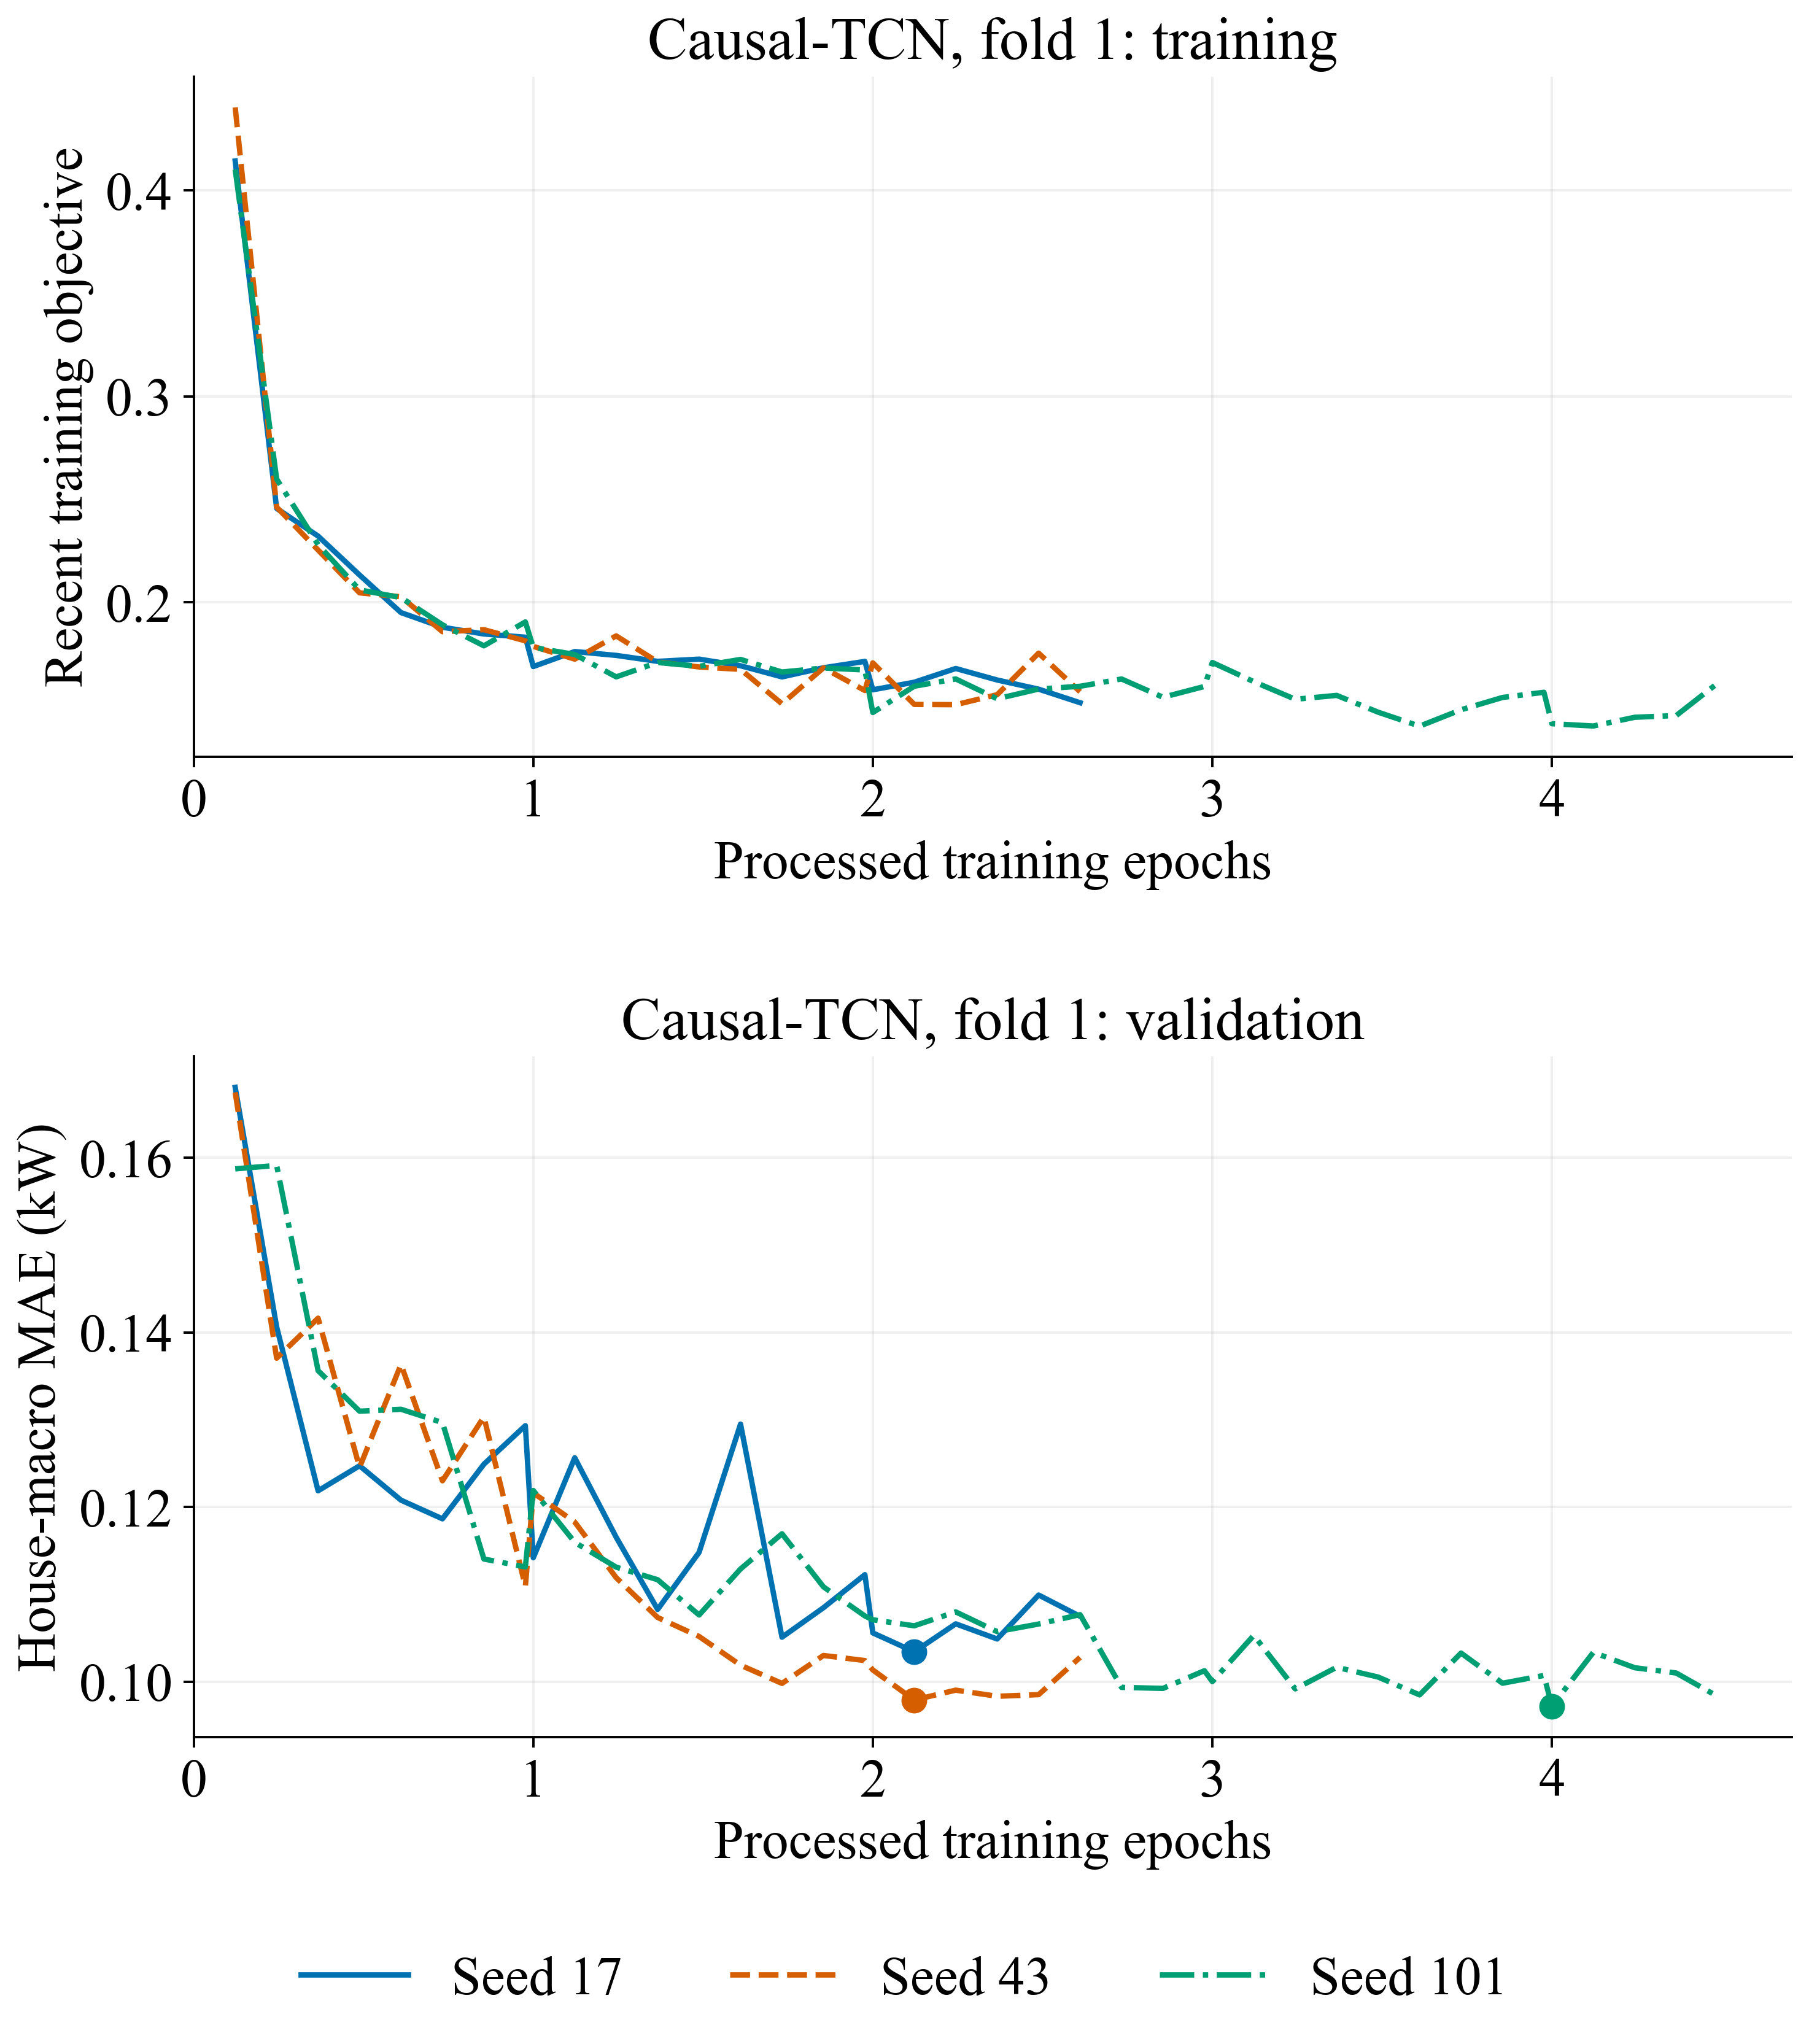

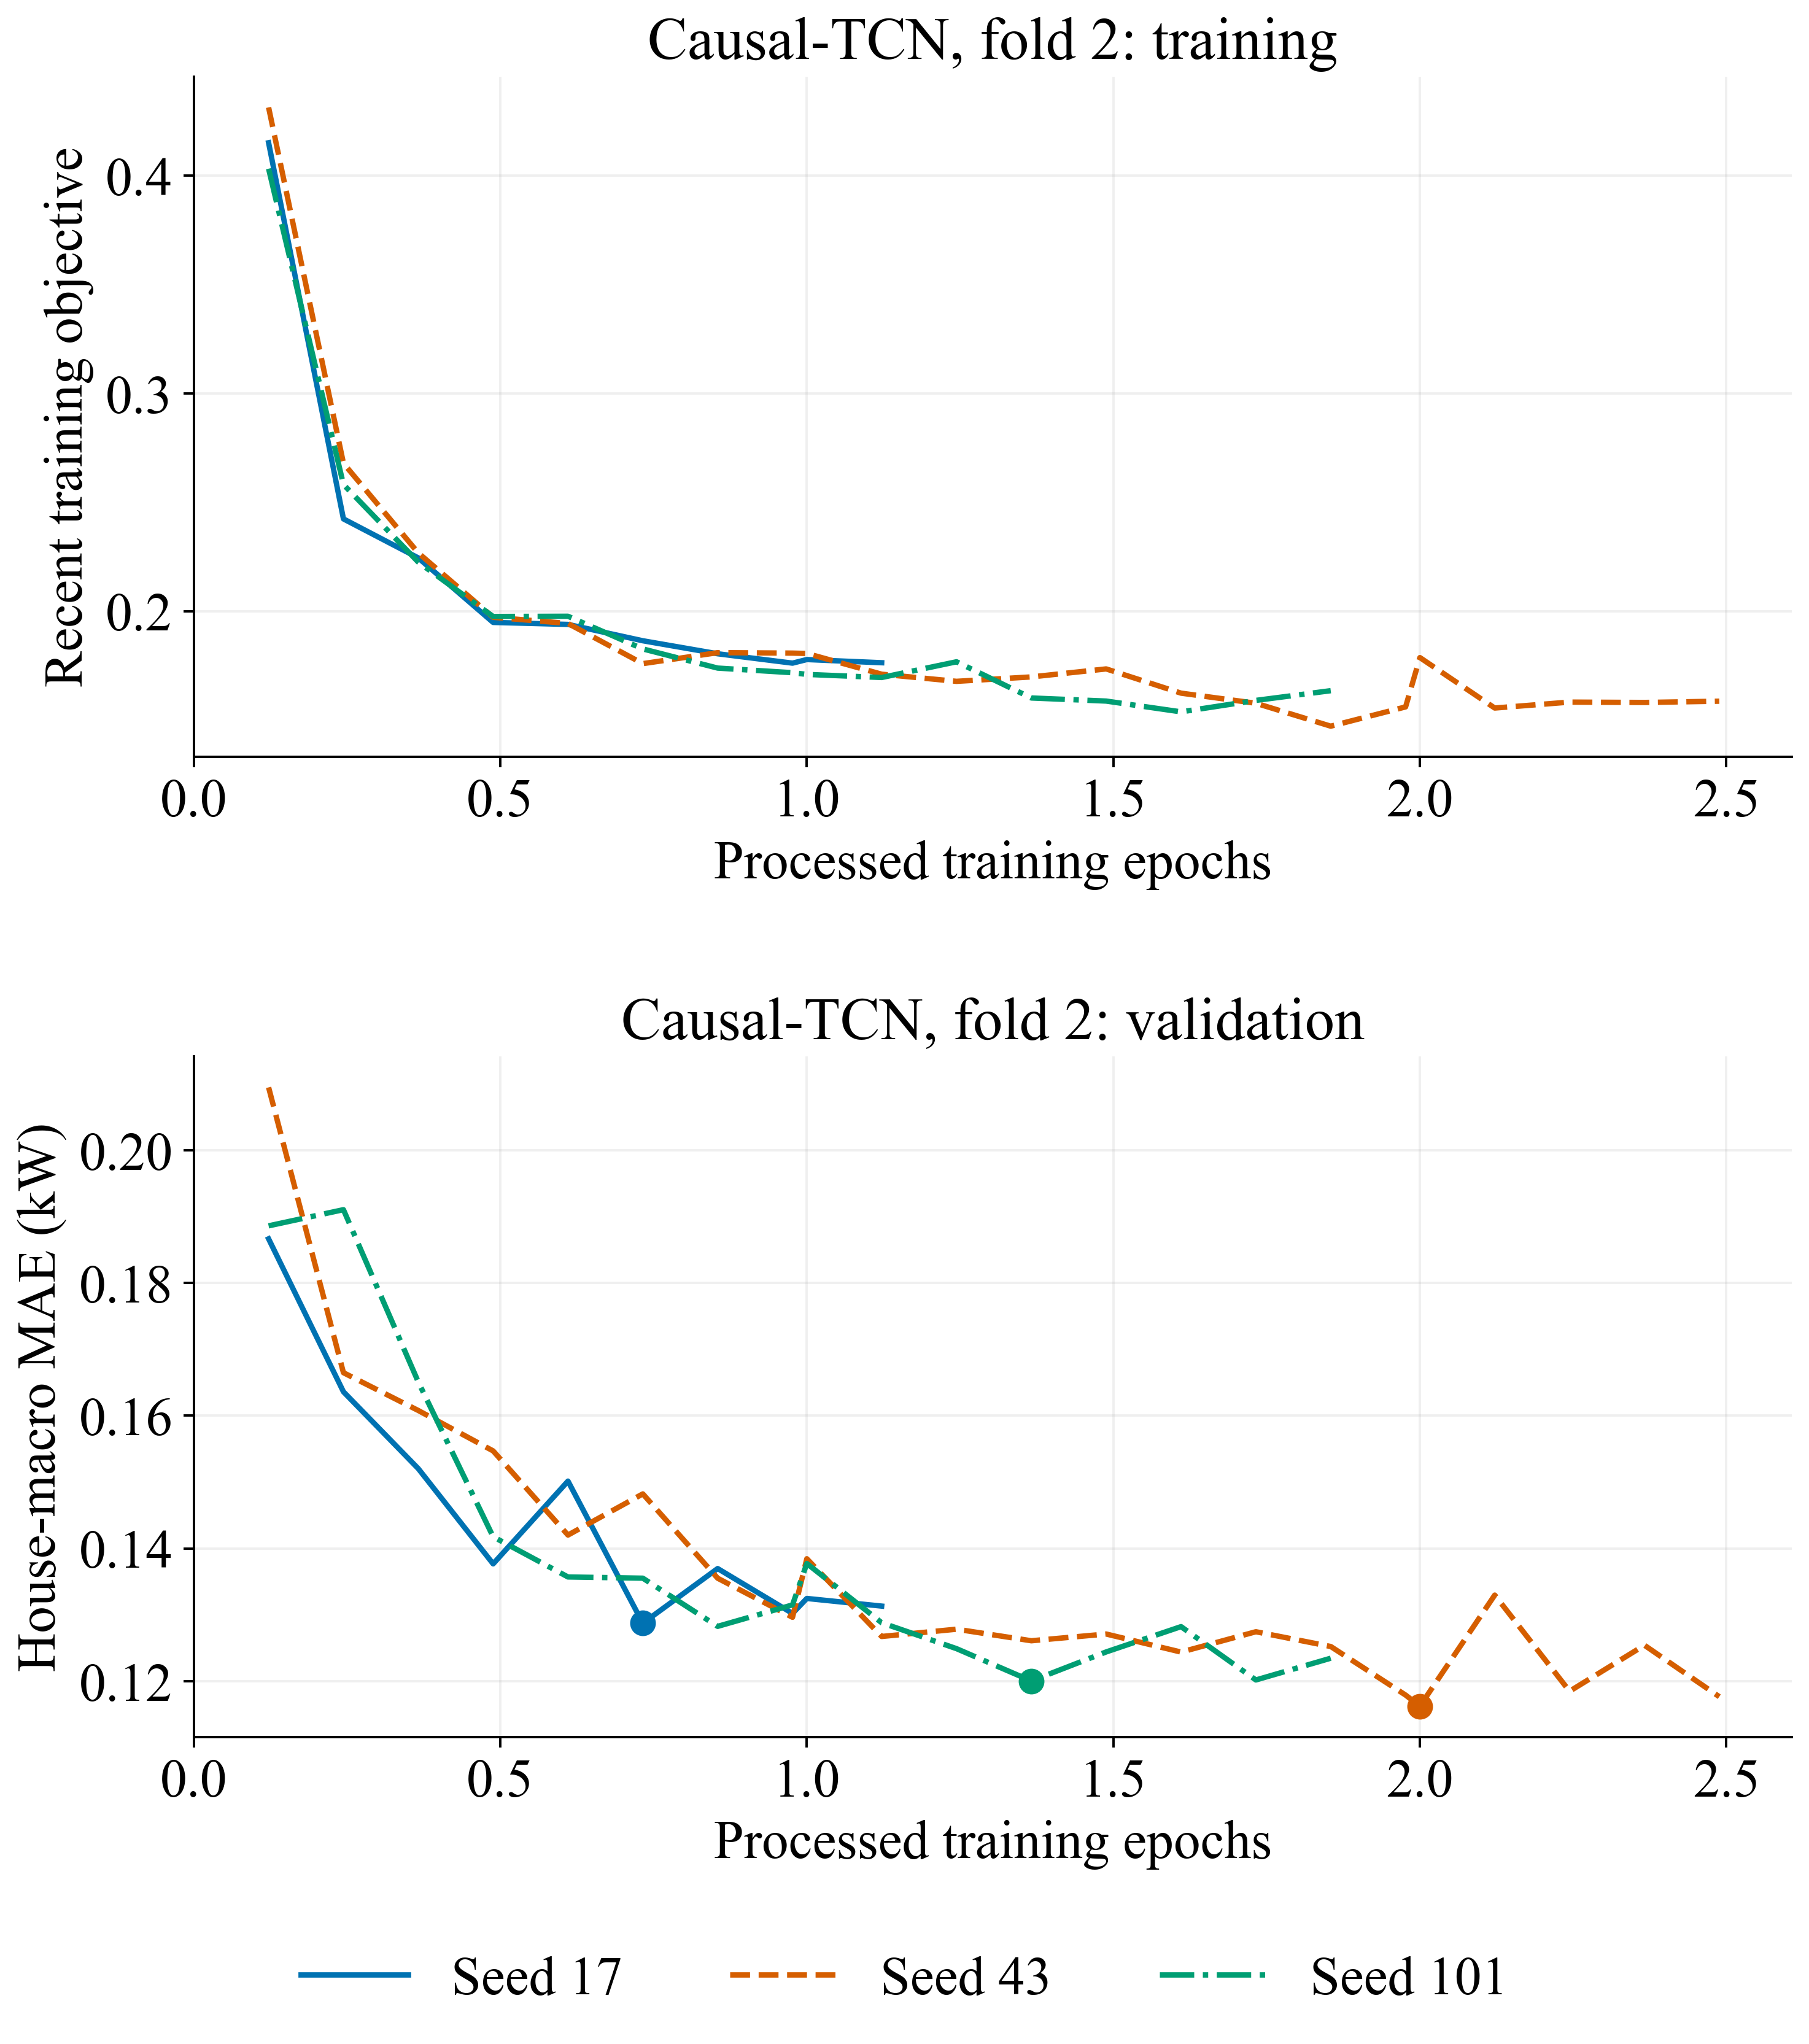

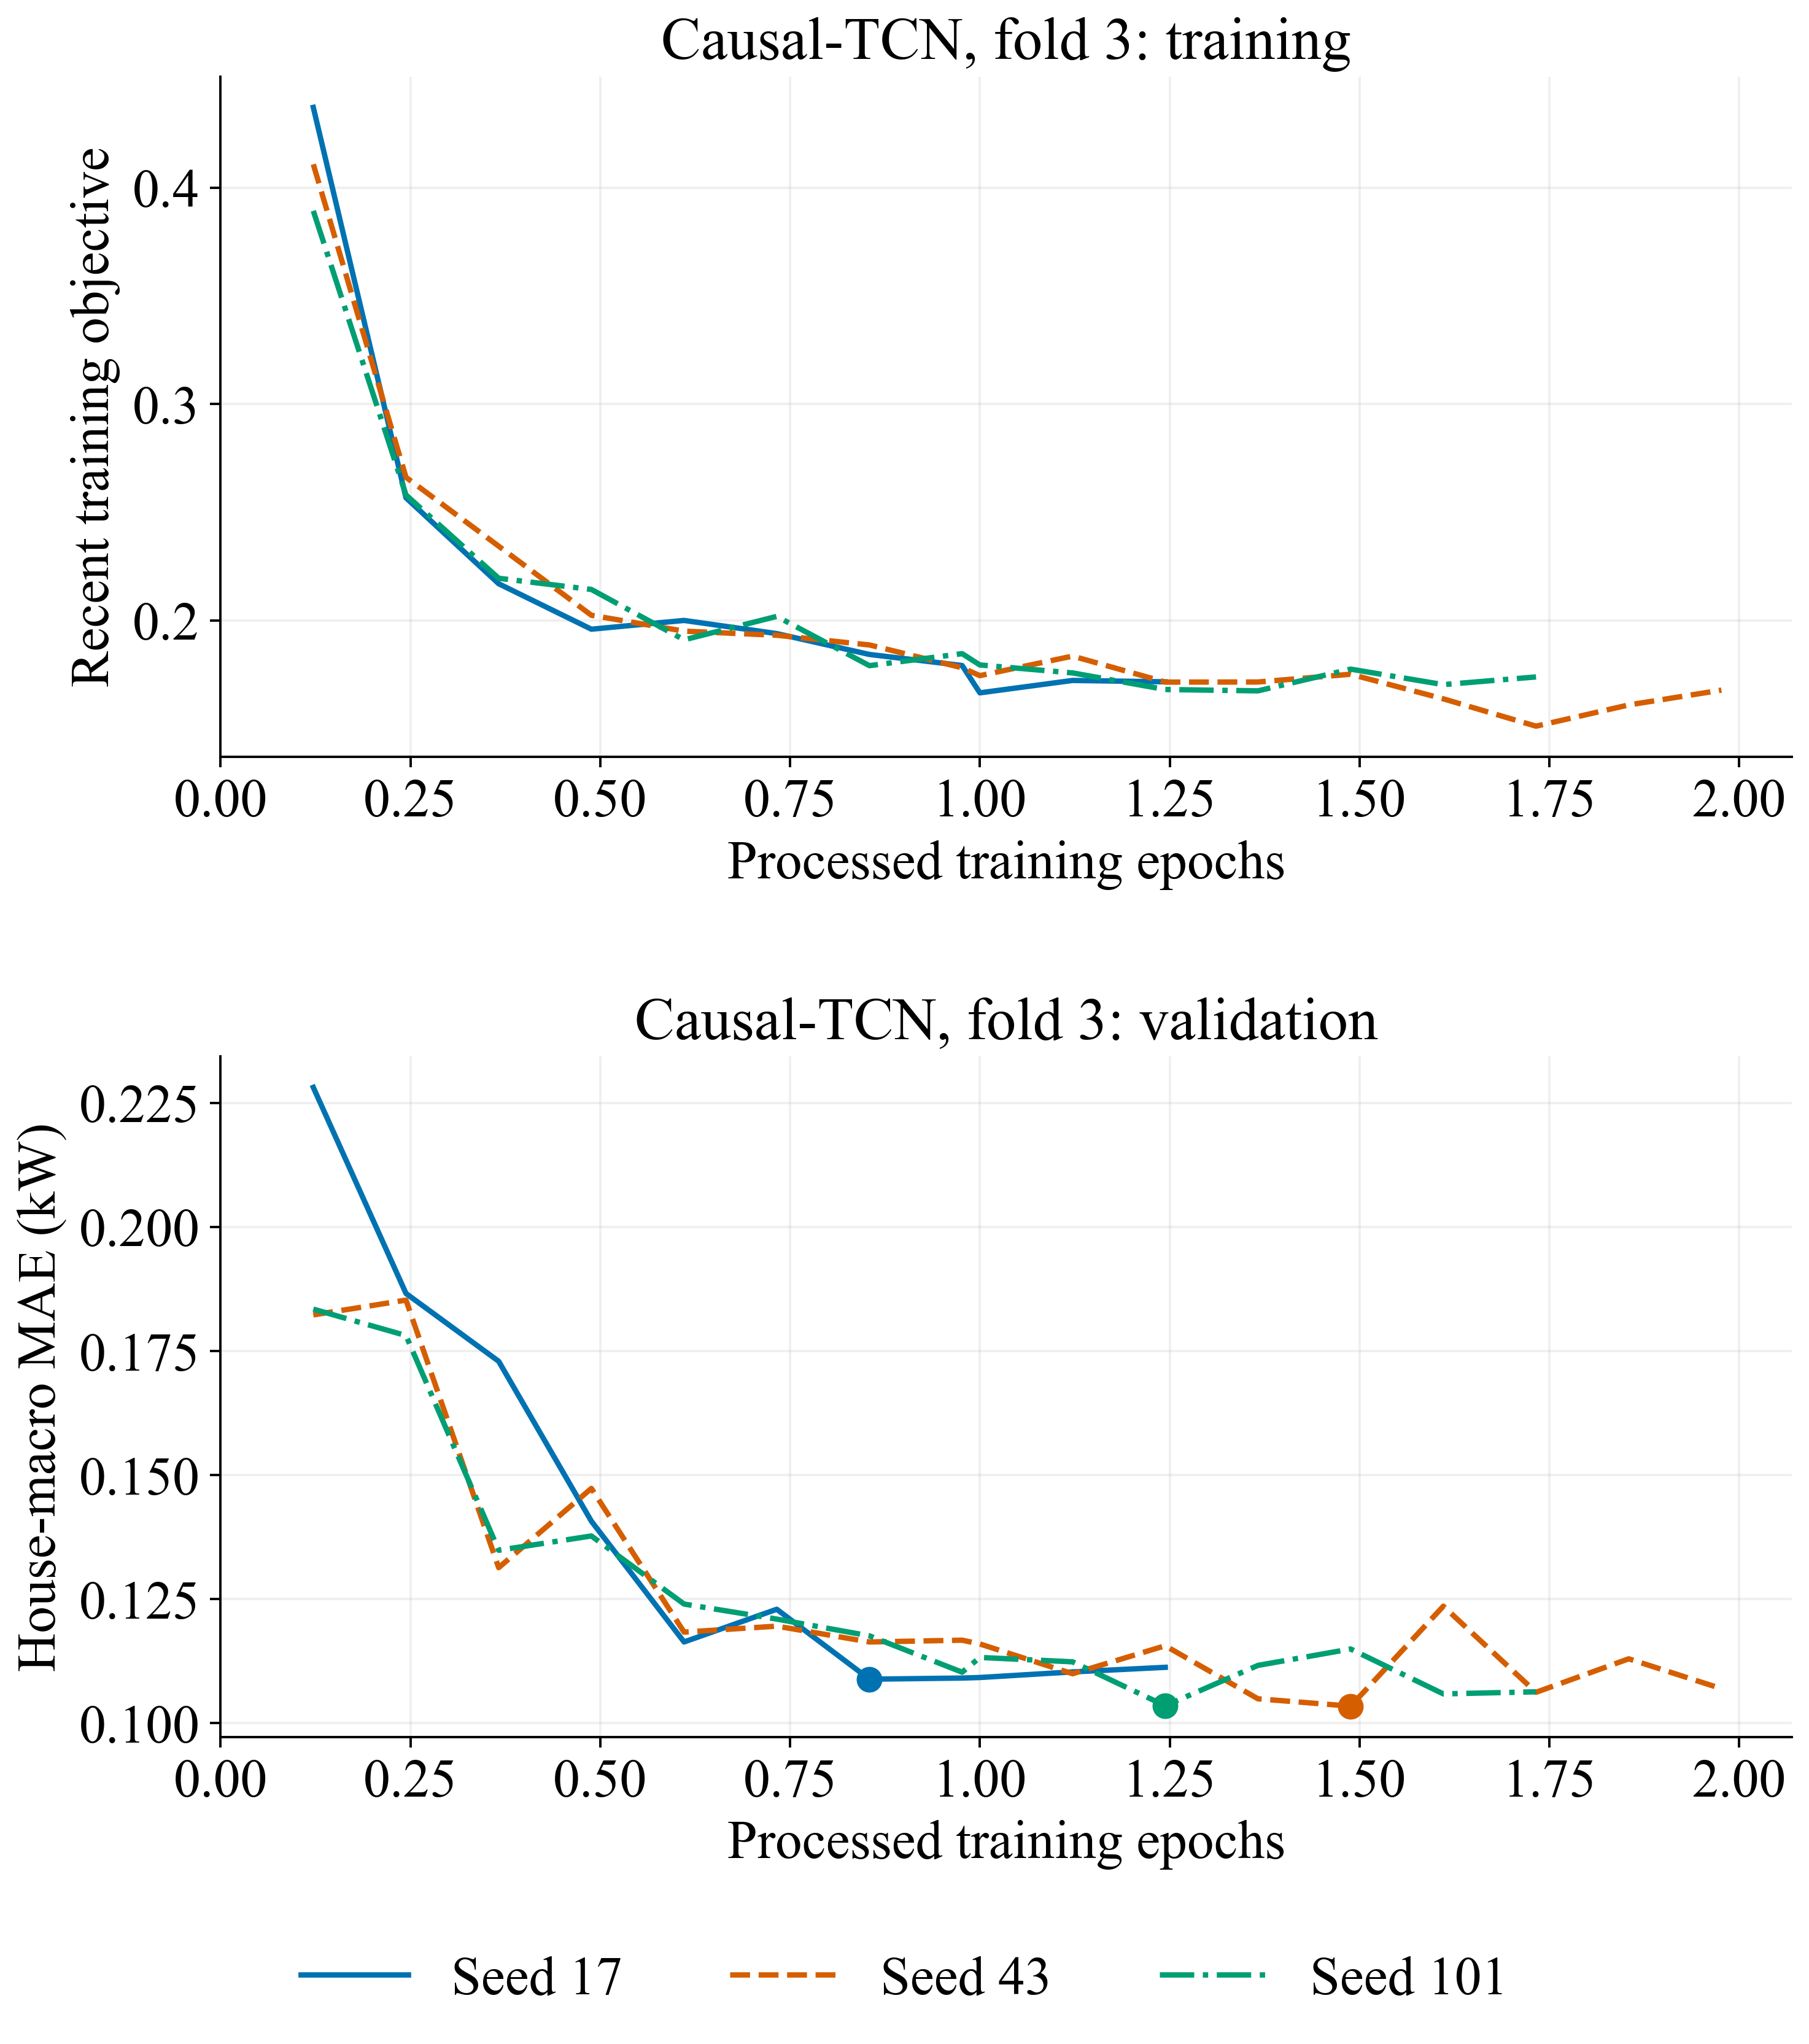

In [1]:
# Re-render archived scientific figures; this cell does not train models or recompute metrics.
def _presentation_nb04_bf0c4831():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_1_seed_17_history.csv': '7cbb302ab52e64f013869869ea507631ee2697420c49205bde064d7e593e16e3', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_1_seed_17_complete.json': '2aff4d69954307192e097d5d1635cacb6dbca184cc8a77a1468fbdcb5de6ad94', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_1_seed_43_history.csv': 'c8e2fa99010b670fb6f531b88c14917df697ea16998b6e9333044fe9b00c2980', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_1_seed_43_complete.json': '37f77aff959acf98e1b84c54c7b4c9391117f19a6434abd88f8e7583d052a780', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_1_seed_101_history.csv': 'b8c939a61c58493262a305d47b5d393c4905e7532f43f6469d68cbc3f28ed468', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_1_seed_101_complete.json': '66330b0348a1e1752713807151cfb11746c377fb4a73c64db105a959e0dc1e0c', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_2_seed_17_history.csv': 'c49f3ffc11231cdbb18b147724e21348e85a7d6eafc9a4c9e138cb1cecd2be67', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_2_seed_17_complete.json': '6b87cf531b61634b8542274b48e481b6b6eeb5da255baeb75fd0dffcbcc1b523', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_2_seed_43_history.csv': 'ad19b76f7ee1d9eeabbca2bea6c1a546fe0e1de064ea50affaad8acff3c2e051', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_2_seed_43_complete.json': 'a080502e1075a8aaa5d9d8f39c4f599589f099ec2c6103daf84d7067b46b3532', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_2_seed_101_history.csv': '6ef6cbc4039d9e35e33dba823018c04e595270cb10dba60fbc6ad97371142e81', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_2_seed_101_complete.json': '6ab64ea6751d94c0232bdaa1917480fef26cf076d51a762024539422ee0df983', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_3_seed_17_history.csv': '0dfd193a6a3815e77314e0e1fd093d82f4599fb3f656220d9470349ff14ce7ff', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_3_seed_17_complete.json': 'b11e7f5c9ea855a04ba688d702a3cb96f1af1d3be94bb65e89b56784cdf09145', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_3_seed_43_history.csv': 'd3139a7119cc0ae32c61e0e98463bc8cca47fb18aeee5b0688c7aecf77e43059', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_3_seed_43_complete.json': 'ca64ff7fd4cc84c46f0665b201bda3c93f37a984d81dc4eb185c2a3a75eb34c6', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_3_seed_101_history.csv': 'f3c398dd8660d626475a0b0dc1b66c27735895c3d121299f18fbfeb4cd78a429', 'Models/modern/guldana_n3_20261007_v01/Causal-TCN_fold_3_seed_101_complete.json': '43212b67300964b97bee09217256d1cb0912d8c75b5f60eb06296fa2436deec4'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB04"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB04"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    family = 'Causal-TCN'
    colors={17:"#0072B2",43:"#D55E00",101:"#009E73"}
    for fold in [1,2,3]:
        fig,axes=plt.subplots(2,1,figsize=(8.8,9.8))
        for seed, style in zip([17,43,101],["-","--","-."]):
            stem=f"{family}_fold_{fold}_seed_{seed}"
            history=pd.read_csv(ROOT / f"Models/modern/guldana_n3_20261007_v01/{stem}_history.csv")
            record=json.loads((ROOT / f"Models/modern/guldana_n3_20261007_v01/{stem}_complete.json").read_text())
            assert np.isfinite(history[["recent_mean_training_objective","inner_house_macro_MAE_kW"]]).all().all()
            x=history.examples_processed/record["training_queries_available"]
            axes[0].plot(x,history.recent_mean_training_objective,color=colors[seed],ls=style,label=f"Seed {seed}",lw=1.8)
            axes[1].plot(x,history.inner_house_macro_MAE_kW,color=colors[seed],ls=style,label=f"Seed {seed}",lw=1.8)
            chosen=np.flatnonzero(np.isclose(history.inner_house_macro_MAE_kW,record["best_inner_house_macro_MAE_kW"],rtol=0,atol=1e-12))
            assert len(chosen)>0
            k=chosen[0]
            axes[1].scatter([x.iloc[k]],[history.inner_house_macro_MAE_kW.iloc[k]],color=colors[seed],s=58,marker="o",zorder=4)
        axes[0].set(title=f"{family}, fold {fold}: training",ylabel="Recent training objective")
        axes[1].set(title=f"{family}, fold {fold}: validation",ylabel="House-macro MAE (kW)")
        for ax in axes:
            ax.set_xlabel("Processed training epochs");ax.set_xlim(left=0);_quiet_axes(ax)
        handles,names=axes[0].get_legend_handles_labels()
        fig.legend(handles,names,loc="lower center",bbox_to_anchor=(.5,.005),ncol=3,frameon=False)
        fig.tight_layout(rect=(0,.065,1,1),h_pad=2)
        _export(fig,f"25_causal_tcn_learning_fold_{fold}")

_presentation_nb04_bf0c4831()


### Matched accuracy and error regimes

Recalculate the complete three-fold, three-seed TCN comparison from its saved predictions, verifying target IDs, timestamps, labels and observation scenarios against the baseline files before computing any difference. The observable-age selector remains an exploratory development-derived control. Seed ranges describe training/masking variability and are not confidence intervals. Conditional tables include the number of contributing houses and seed-query cases.

The saved selector predictions contain the same IDs and scenarios but omit sensor counts. Counts are joined one-to-one from the matching observation metadata before alignment is checked; no fitted predictions change.

In [44]:
# Matched full-family diagnostics require every outer fold and every prespecified seed.
def modern_family_diagnostics(family):
    paired_frames=[]
    seed_rows=[]
    comparator_names=[family,"ExtraTrees","Observable age selector","Last valid aggregate"]
    for seed in [17,43,101]:
        per_model={name:[] for name in comparator_names}
        for fold in [1,2,3]:
            stem=f"{family}_fold_{fold}_seed_{seed}"
            record=json.loads((MODERN_DIR/f"{stem}_complete.json").read_text())
            assert file_sha256(PRED_DIR/f"{stem}.parquet")==record["prediction_sha256"]
            frame=pd.read_parquet(PRED_DIR/f"{stem}.parquet")
            assert len(frame)==40960 and frame.role.eq("outer_validation").all()
            assert frame.fold.eq(fold).all() and frame.seed.eq(seed).all()
            candidates={family:frame,
                "ExtraTrees":pd.read_parquet(BASELINE_PRED_DIR/f"ExtraTrees_fold_{fold}_seed_{seed}.parquet"),
                "Observable age selector":pd.read_parquet(PRED_DIR/f"Observable_age_selector_fold_{fold}_seed_{seed}.parquet")}
            naive=pd.read_parquet(BASELINE_PRED_DIR/f"naive_OOF_fold_{fold}_seed_{seed}.parquet")
            candidates["Last valid aggregate"]=naive.assign(prediction_kW=naive["Last valid aggregate"])
            for name,candidate in candidates.items():
                assert candidate.fold.eq(fold).all() and candidate.seed.eq(seed).all()
                if name=="Observable age selector":
                    # This saved control omits counts; attach immutable scenario metadata by identity.
                    assert not candidate.observation_id.duplicated().any()
                    candidate=candidate.merge(frame[["observation_id","observed_auxiliary_count",
                        "installed_auxiliary_count"]],on="observation_id",how="left",sort=False,validate="one_to_one")
                alignment=["observation_id","house","timestamp","y_kW","mode","gap","retention",
                           "observed_auxiliary_count","installed_auxiliary_count"]
                pd.testing.assert_frame_equal(candidate[alignment].reset_index(drop=True),
                                              frame[alignment].reset_index(drop=True))
                result=candidate[alignment+["prediction_kW"]].copy()
                result["Model"]=name;result["Seed"]=seed;result["Fold"]=fold
                result["absolute_error_kW"]=(result.prediction_kW-result.y_kW).abs()
                per_model[name].append(result)
                paired_frames.append(result)
        for name,pieces in per_model.items():
            complete=pd.concat(pieces,ignore_index=True)
            assert len(complete)==122880
            seed_rows.append({"Model":name,"Seed":seed,
                **regression_summary(complete,complete.prediction_kW.to_numpy())})
    seed_metrics=pd.DataFrame(seed_rows)
    table(seed_metrics,f"{family}_complete_seed_comparison",
        f"Complete three-fold comparison for {family}, paired with three diagnostic controls. "
        "Every seed uses identical target IDs and masks within each model comparison.")
    summary=seed_metrics.groupby("Model",sort=False).agg(
        MAE_mean=("House-macro MAE (kW)","mean"),MAE_min=("House-macro MAE (kW)","min"),
        MAE_max=("House-macro MAE (kW)","max"),RMSE_mean=("House-macro RMSE (kW)","mean"),
        bias_mean=("Bias (kW)","mean")).reset_index()
    summary=summary.rename(columns={"MAE_mean":"Mean MAE (kW)","MAE_min":"Minimum seed MAE (kW)",
        "MAE_max":"Maximum seed MAE (kW)","RMSE_mean":"Mean macro RMSE (kW)","bias_mean":"Mean bias (kW)"})
    table(summary,f"{family}_complete_model_summary",
        "Descriptive mean and range over seeds; the seed range is not a population confidence interval.")
    paired=pd.concat(paired_frames,ignore_index=True)
    household=(paired.groupby(["Model","Seed","house"],sort=False).absolute_error_kW.mean()
        .groupby(["Model","house"],sort=False).mean().unstack("Model").reset_index())
    household=household.rename_axis(columns=None)
    table(household,f"{family}_house_MAE","House-specific MAE in kW, averaged across the three retained seeds.")
    for field,label in [("mode","Missingness mode"),("gap","Gap minutes"),("retention","Auxiliary retention"),
                        ("observed_auxiliary_count","Observed auxiliary sensors")]:
        grouped=(paired.groupby(["Model","Seed","house",field],observed=True).absolute_error_kW.mean()
            .groupby(["Model","Seed",field],observed=True).mean()
            .groupby(["Model",field],observed=True).mean().unstack("Model").reset_index().rename(columns={field:label}))
        support=(paired.loc[paired.Model.eq(family)].groupby(field,observed=True).agg(
            Houses=("house","nunique"),seed_query_cases=("observation_id","size")).reset_index()
            .rename(columns={field:label,"seed_query_cases":"Seed-query cases"}))
        grouped=grouped.rename_axis(columns=None).merge(support,on=label,validate="one_to_one")
        table(grouped,f"{family}_MAE_by_{field}",
            f"Conditional house-macro MAE (kW) by {label.lower()}, averaged over seeds; empirical OOF scenario weights.")
    return seed_metrics,summary,household

tcn_seed_metrics,tcn_model_summary,tcn_house_summary=modern_family_diagnostics("Causal-TCN")


Model,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-TCN,17,0.1228,0.3788,−0.0649,0.0977
ExtraTrees,17,0.1165,0.3357,−0.0074,0.0000
Observable age selector,17,0.1095,0.3401,−0.0066,0.0000
Last valid aggregate,17,0.1530,0.5549,−0.0017,0.0000
Causal-TCN,43,0.1146,0.3674,−0.0514,0.0749
ExtraTrees,43,0.1160,0.3360,−0.0066,0.0000
Observable age selector,43,0.1100,0.3411,−0.0073,0.0000
Last valid aggregate,43,0.1525,0.5533,−0.0017,0.0000
Causal-TCN,101,0.1159,0.3660,−0.0520,0.1546
ExtraTrees,101,0.1150,0.3355,−0.0062,0.0000


Model,Mean MAE (kW),Minimum seed MAE (kW),Maximum seed MAE (kW),Mean macro RMSE (kW),Mean bias (kW)
Causal-TCN,0.1178,0.1146,0.1228,0.3708,−0.0561
ExtraTrees,0.1158,0.1150,0.1165,0.3357,−0.0067
Observable age selector,0.1093,0.1083,0.1100,0.3405,−0.0070
Last valid aggregate,0.1518,0.1499,0.1530,0.5517,−0.0011


house,Causal-TCN,ExtraTrees,Observable age selector,Last valid aggregate
1,0.0683,0.0771,0.0715,0.1171
2,0.1586,0.1544,0.1432,0.2021
3,0.0888,0.0875,0.0833,0.1399
4,0.0977,0.1024,0.0965,0.1433
5,0.2506,0.2621,0.2528,0.3496
6,0.1141,0.1058,0.0998,0.1552
7,0.0702,0.0765,0.0726,0.0847
8,0.1122,0.1015,0.0980,0.1129
9,0.0624,0.0650,0.0622,0.0791
10,0.1547,0.1262,0.1130,0.1343


Missingness mode,Causal-TCN,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
block,0.1505,0.1651,0.2580,0.1651,10,92696
mixed,0.1705,0.1807,0.2584,0.1807,10,92346
point,0.0751,0.0594,0.0451,0.0455,10,91617
sensor_dropout,0.0744,0.0576,0.0447,0.0451,10,91981


Gap minutes,Causal-TCN,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
1,0.0747,0.0585,0.0449,0.0453,10,183598
5,0.1221,0.1141,0.1113,0.1141,10,61463
30,0.1736,0.1909,0.2800,0.1909,10,61836
120,0.1854,0.2132,0.3822,0.2132,10,61743


Auxiliary retention,Causal-TCN,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
0.0000,0.1281,0.1257,0.1507,0.1179,10,73282
0.2500,0.1219,0.1200,0.1503,0.1132,10,74179
0.5000,0.1186,0.1167,0.1526,0.1100,10,73611
0.7500,0.1121,0.1105,0.1517,0.1043,10,74116
1.0000,0.1082,0.1065,0.1539,0.1011,10,73452


Observed auxiliary sensors,Causal-TCN,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
0,0.1291,0.1267,0.1513,0.1190,10,109765
1,0.1247,0.1215,0.1503,0.1147,10,61278
2,0.1147,0.1129,0.1488,0.1064,10,64291
3,0.1111,0.1104,0.1533,0.1044,10,67566
4,0.1148,0.1164,0.1688,0.1094,7,41612
5,0.1574,0.1286,0.3167,0.1289,7,22660
6,0.1884,0.1314,0.1867,0.1108,1,1468


**Interpretation.** The complete computed tables show that TCN has higher mean house-macro MAE than ExtraTrees and the exploratory observable-age selector. TCN also has a wider seed range, higher macro RMSE and more negative signed error than ExtraTrees. Thus the complete comparison does not support overall TCN dominance.

The regime trade-off is informative: TCN improves on ExtraTrees at the two longest prescribed gaps while worsening at the shorter gaps. House 10 is a notable weakness; the subgroup with all six auxiliaries observed contains only this house and must not be treated as broad population evidence. The learning curves show rapid initial improvement and seed-dependent later validation minima. Every retained run reached the full available training subset and stopped by inner patience; no convergence or significance claim follows from that stopping rule.

## 8. Incomplete CSDI: computation and numerical limits

The first prespecified CSDI candidate completed 10,240 inner-validation queries with 100 draws per query: fitting took 196.94 s and sampling took 8,673.92 s. This is an internal-selection result, not a complete OOF comparison. A prefix-cache acceleration was rejected after a numerical-parity counterexample (maximum normalized difference 0.000211954; two of twenty planned cases evaluated), and the original sampler was retained. Compiler and larger-batch changes were not adopted; the earlier query-readout screen passed its stated tolerance but established no accuracy advantage.

The remaining CSDI search, retained fits and OOF cohorts were not carried out. CSDI is therefore excluded from the accuracy ranking; this exclusion is not evidence of inferior accuracy.

## 9. Causal Transformer

Apply the same four prespecified configurations, training populations and stopping rules as for TCN. The attention mask is triangular within the observed prefix ending at the current query. Selection uses only the complete inner-validation cohort; the subsequent retained runs differ by the three fixed seeds.


In [47]:
# Select the causal Transformer using only fold-1 inner validation.
transformer_fold_1_selection=search_point_family(1,"Causal-Transformer")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
Causal-Transformer,1,1,60,0.0010,0.1088,182.9280,16380,wall_clock_budget
Causal-Transformer,1,2,120,0.0010,0.1071,183.6229,16380,wall_clock_budget
Causal-Transformer,1,3,60,0.0003,0.1095,182.8945,16380,wall_clock_budget
Causal-Transformer,1,4,120,0.0003,0.1143,183.6737,16380,wall_clock_budget


**Selection interpretation.** The longer tested history and larger tested learning rate yield the lowest inner-validation MAE in this fold. Every trial visited the full search-training subset and reached the fixed wall-clock ceiling. The exact configurations, scores and exposure are retained in the preceding computed table; no outer target chose this setting.

### Retained first-fold runs

Fit the selected configuration independently at each seed and compute the complete outer-validation predictions.

In [48]:
# Fit and reproduce the selected Transformer on fold 1 for all three retained seeds.
transformer_fold_1_resources=[]
for seed in [17,43,101]:
    transformer_fold_1_resources.append(final_point_fit(1,"Causal-Transformer",seed))


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,1,17,0.1201,0.3975,−0.0628,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,1,17,325.5001,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,1,43,0.1155,0.3625,−0.0431,0.0806


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,1,43,284.4878,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,1,101,0.1232,0.3844,−0.0585,0.0342


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,1,101,196.1422,65530,inner_patience


**First-fold interpretation.** The independently fitted seeds and their paired OOF results are shown above. These results describe one temporal fold; they do not establish a completed Transformer-versus-TCN ranking. Continue to the next outer fold under the unchanged search space and inner-only selection rule.

### Second-fold selection

In [49]:
# Select the causal Transformer using only fold-2 inner validation.
transformer_fold_2_selection=search_point_family(2,"Causal-Transformer")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
Causal-Transformer,2,1,60,0.0010,0.1262,183.1374,16380,wall_clock_budget
Causal-Transformer,2,2,120,0.0010,0.1258,183.9077,16380,wall_clock_budget
Causal-Transformer,2,3,60,0.0003,0.1300,183.3112,16380,wall_clock_budget
Causal-Transformer,2,4,120,0.0003,0.1339,183.9707,16380,wall_clock_budget


**Second-fold selection.** The longer tested history again gives the lowest inner-validation MAE at the larger tested learning rate. The two larger-rate candidates are close in the computed scores; this is an inner-selection decision, not evidence of a population-level difference between histories. Every trial visited the complete search subset and reached the fixed time ceiling.

### Second-fold retained fits

Fit the selected configuration at all prespecified seeds and compute the complete OOF predictions.

In [50]:
# Fit and reproduce the selected Transformer on fold 2 for all three retained seeds.
transformer_fold_2_resources=[]
for seed in [17,43,101]:
    transformer_fold_2_resources.append(final_point_fit(2,"Causal-Transformer",seed))


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,2,17,0.1160,0.3396,−0.0691,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,2,17,246.4604,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,2,43,0.1188,0.3518,−0.0653,0.0879


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,2,43,251.0352,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,2,101,0.1171,0.3450,−0.0455,0.8301


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,2,101,221.3231,65530,inner_patience


The second-fold retained models completed their prescribed training exposure and stopped by inner-validation patience. Their outer-fold errors are close across seeds, while all retain negative average bias; the last seed also produces more negative predictions. These diagnostics do not modify the selected architecture, predictions or scoring rule.

### Third-fold inner selection

The same ordered search configurations and budget now apply to the last development fold. Only its inner-validation labels choose the retained configuration; the outer labels remain excluded from selection.

In [51]:
# Select the causal Transformer using only fold-3 inner validation.
transformer_fold_3_selection=search_point_family(3,"Causal-Transformer")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
Causal-Transformer,3,1,60,0.0010,0.1063,183.1943,16380,wall_clock_budget
Causal-Transformer,3,2,120,0.0010,0.1116,183.8468,16380,wall_clock_budget
Causal-Transformer,3,3,60,0.0003,0.1186,182.9046,16380,wall_clock_budget
Causal-Transformer,3,4,120,0.0003,0.1277,180.1688,16380,wall_clock_budget


The shorter history and larger tested learning rate give the lowest third-fold inner-validation MAE. All configurations visit the complete prescribed search subset and reach the time limit; a completed trial is therefore not evidence of convergence. The fold-specific history choice differs from the earlier folds and is retained without using outer-fold errors. The selected configuration is now fitted for every prespecified seed on the common retained training subset.

In [52]:
# Fit and reproduce the selected Transformer on fold 3 for all three retained seeds.
transformer_fold_3_resources=[]
for seed in [17,43,101]:
    transformer_fold_3_resources.append(final_point_fit(3,"Causal-Transformer",seed))


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,3,17,0.1070,0.3023,−0.0496,0.0024


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,3,17,384.5852,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,3,43,0.1193,0.3178,−0.0400,0.0122


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,3,43,148.7343,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,3,101,0.1156,0.3148,−0.0539,0.0171


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
Causal-Transformer,3,101,172.7428,65530,inner_patience


The retained third-fold runs all stopped by inner-validation patience after exposing the full prescribed training subset. Their negative mean bias persists across seeds.

### Transformer optimization trajectories

The following figure plots the actual retained histories. Its inner-validation checkpoints explain the stopping decision without using outer labels.

In [53]:
# Inspect the actual Transformer training and validation histories.
modern_learning_report("Causal-Transformer",26)

Fold,Seed,Selected step,Stop reason,Fit seconds,Training queries
1,17,4346,inner_patience,325.5001,65530
1,43,3798,inner_patience,284.4878,65530
1,101,2048,inner_patience,196.1422,65530
2,17,3048,inner_patience,246.4604,65530
2,43,3298,inner_patience,251.0352,65530
2,101,2548,inner_patience,221.3231,65530
3,17,6394,inner_patience,384.5852,65530
3,43,2000,inner_patience,148.7343,65530
3,101,2298,inner_patience,172.7428,65530


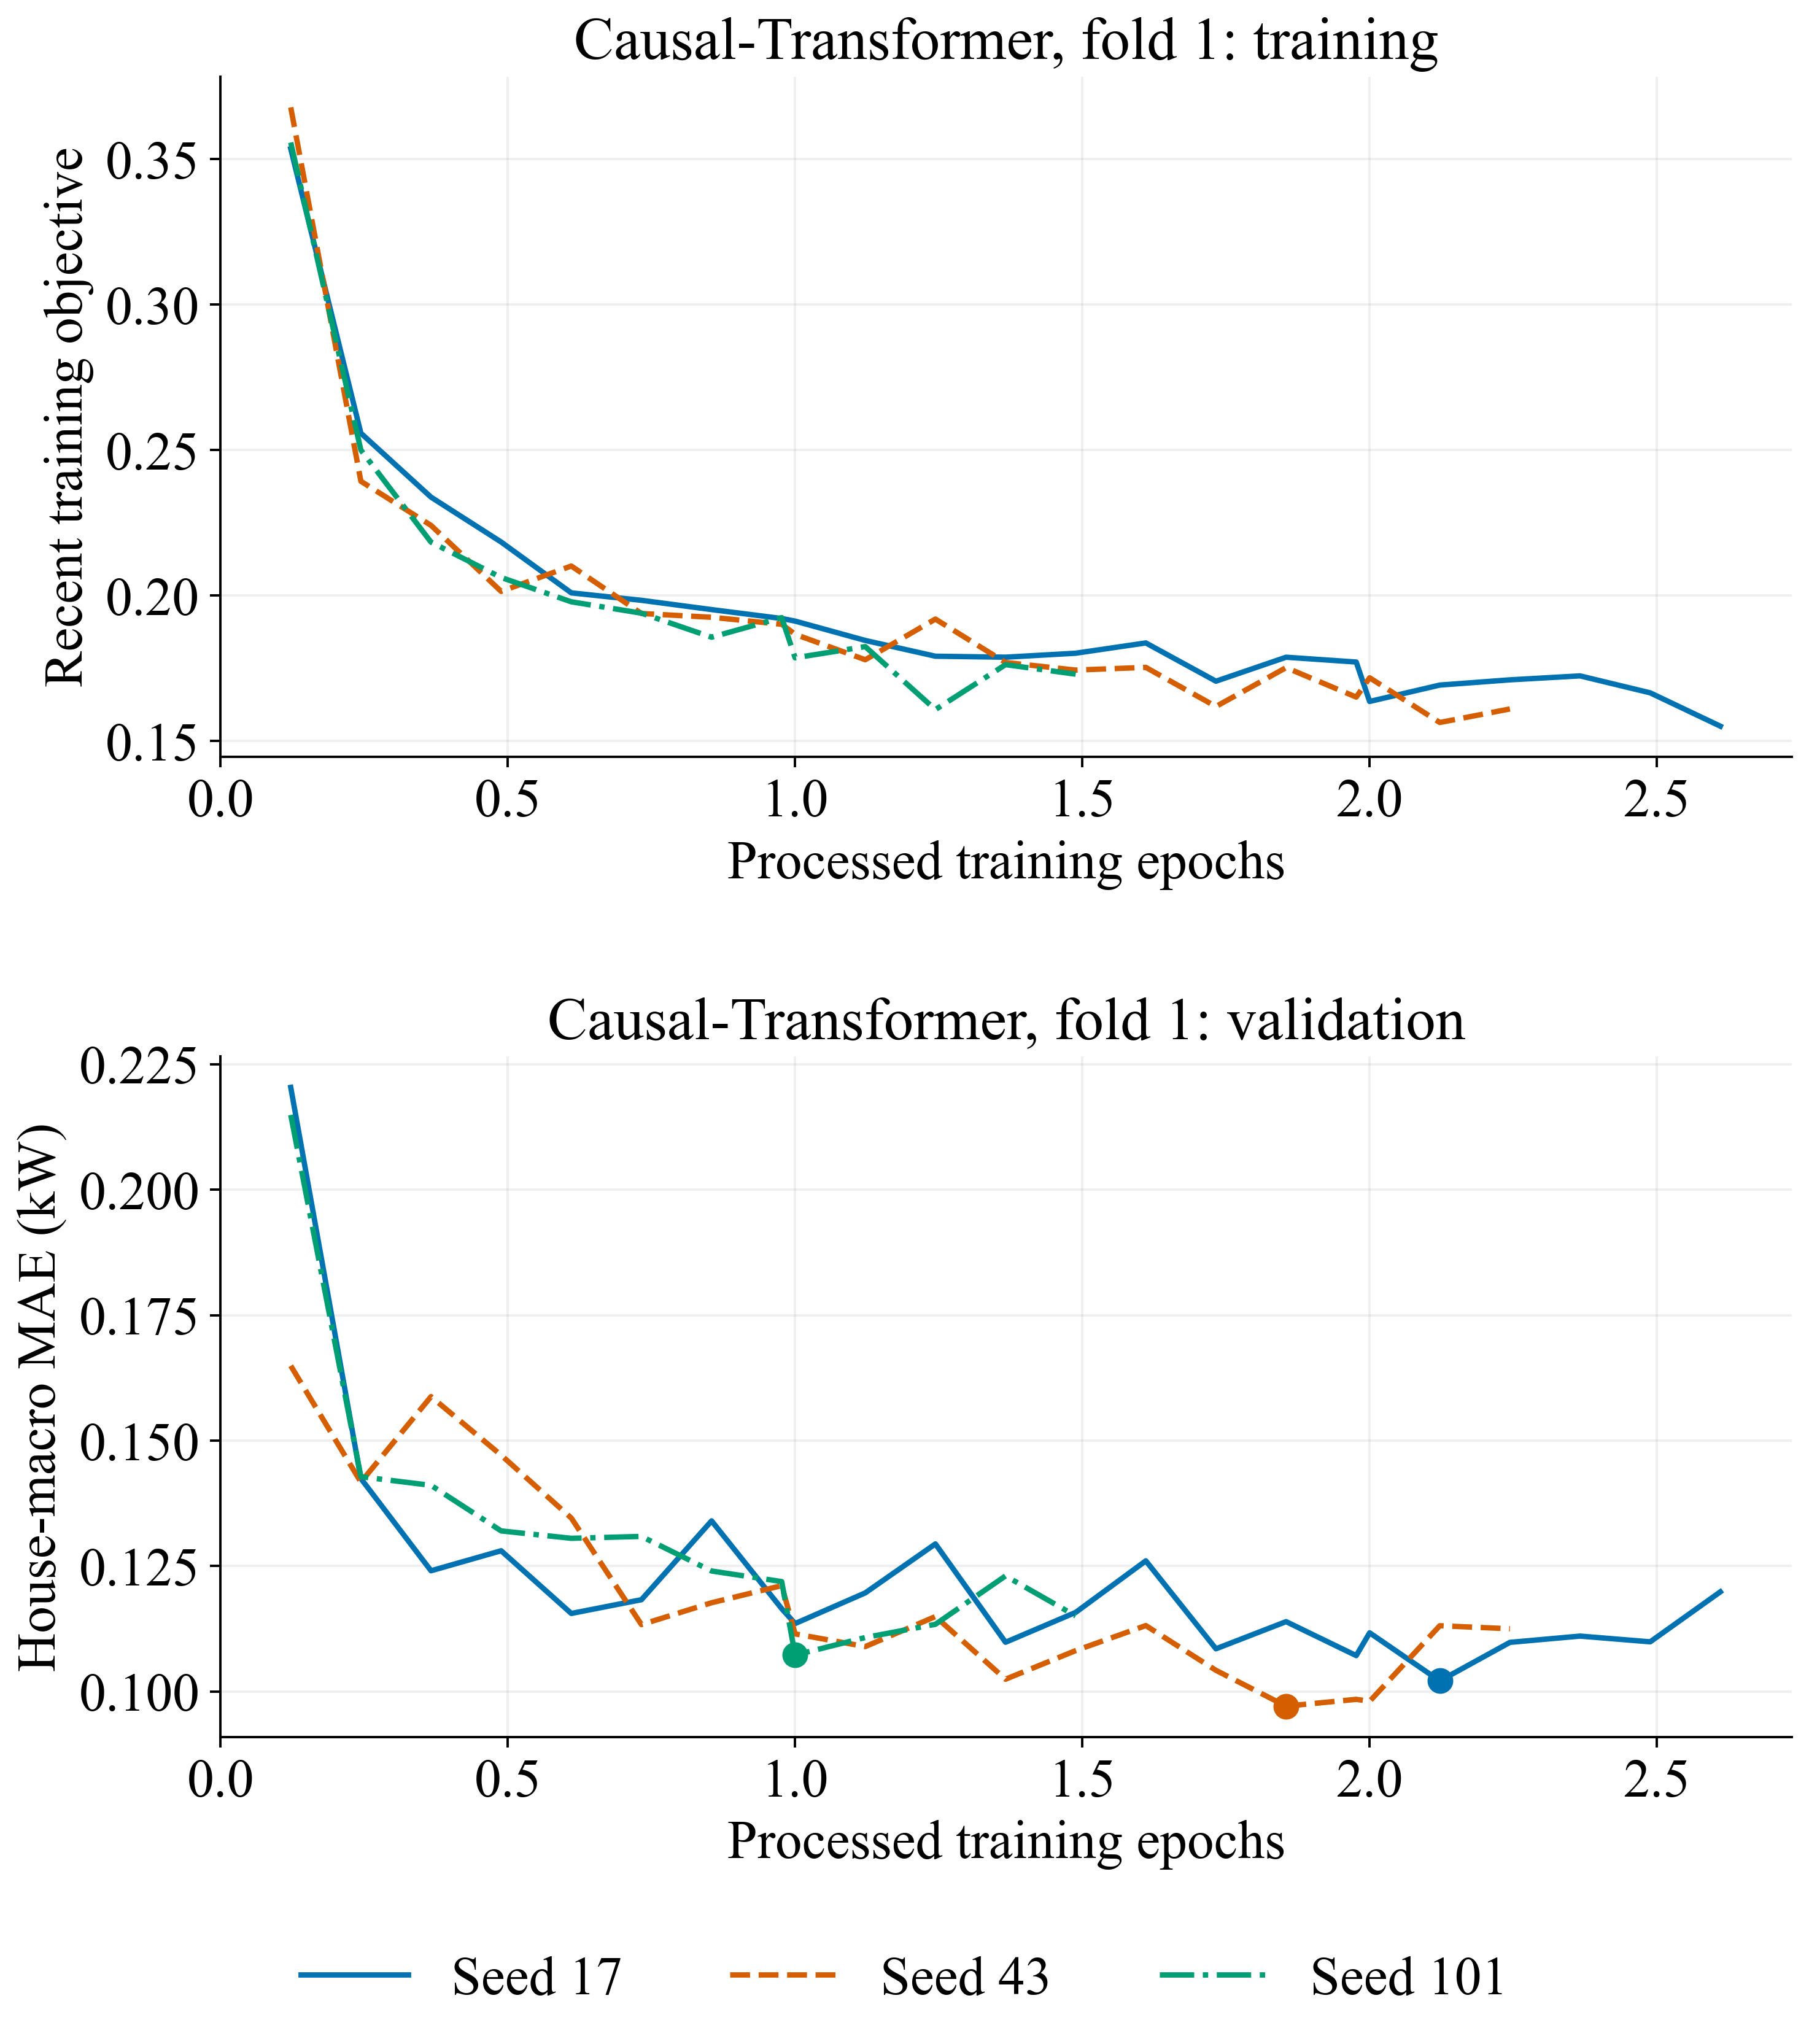

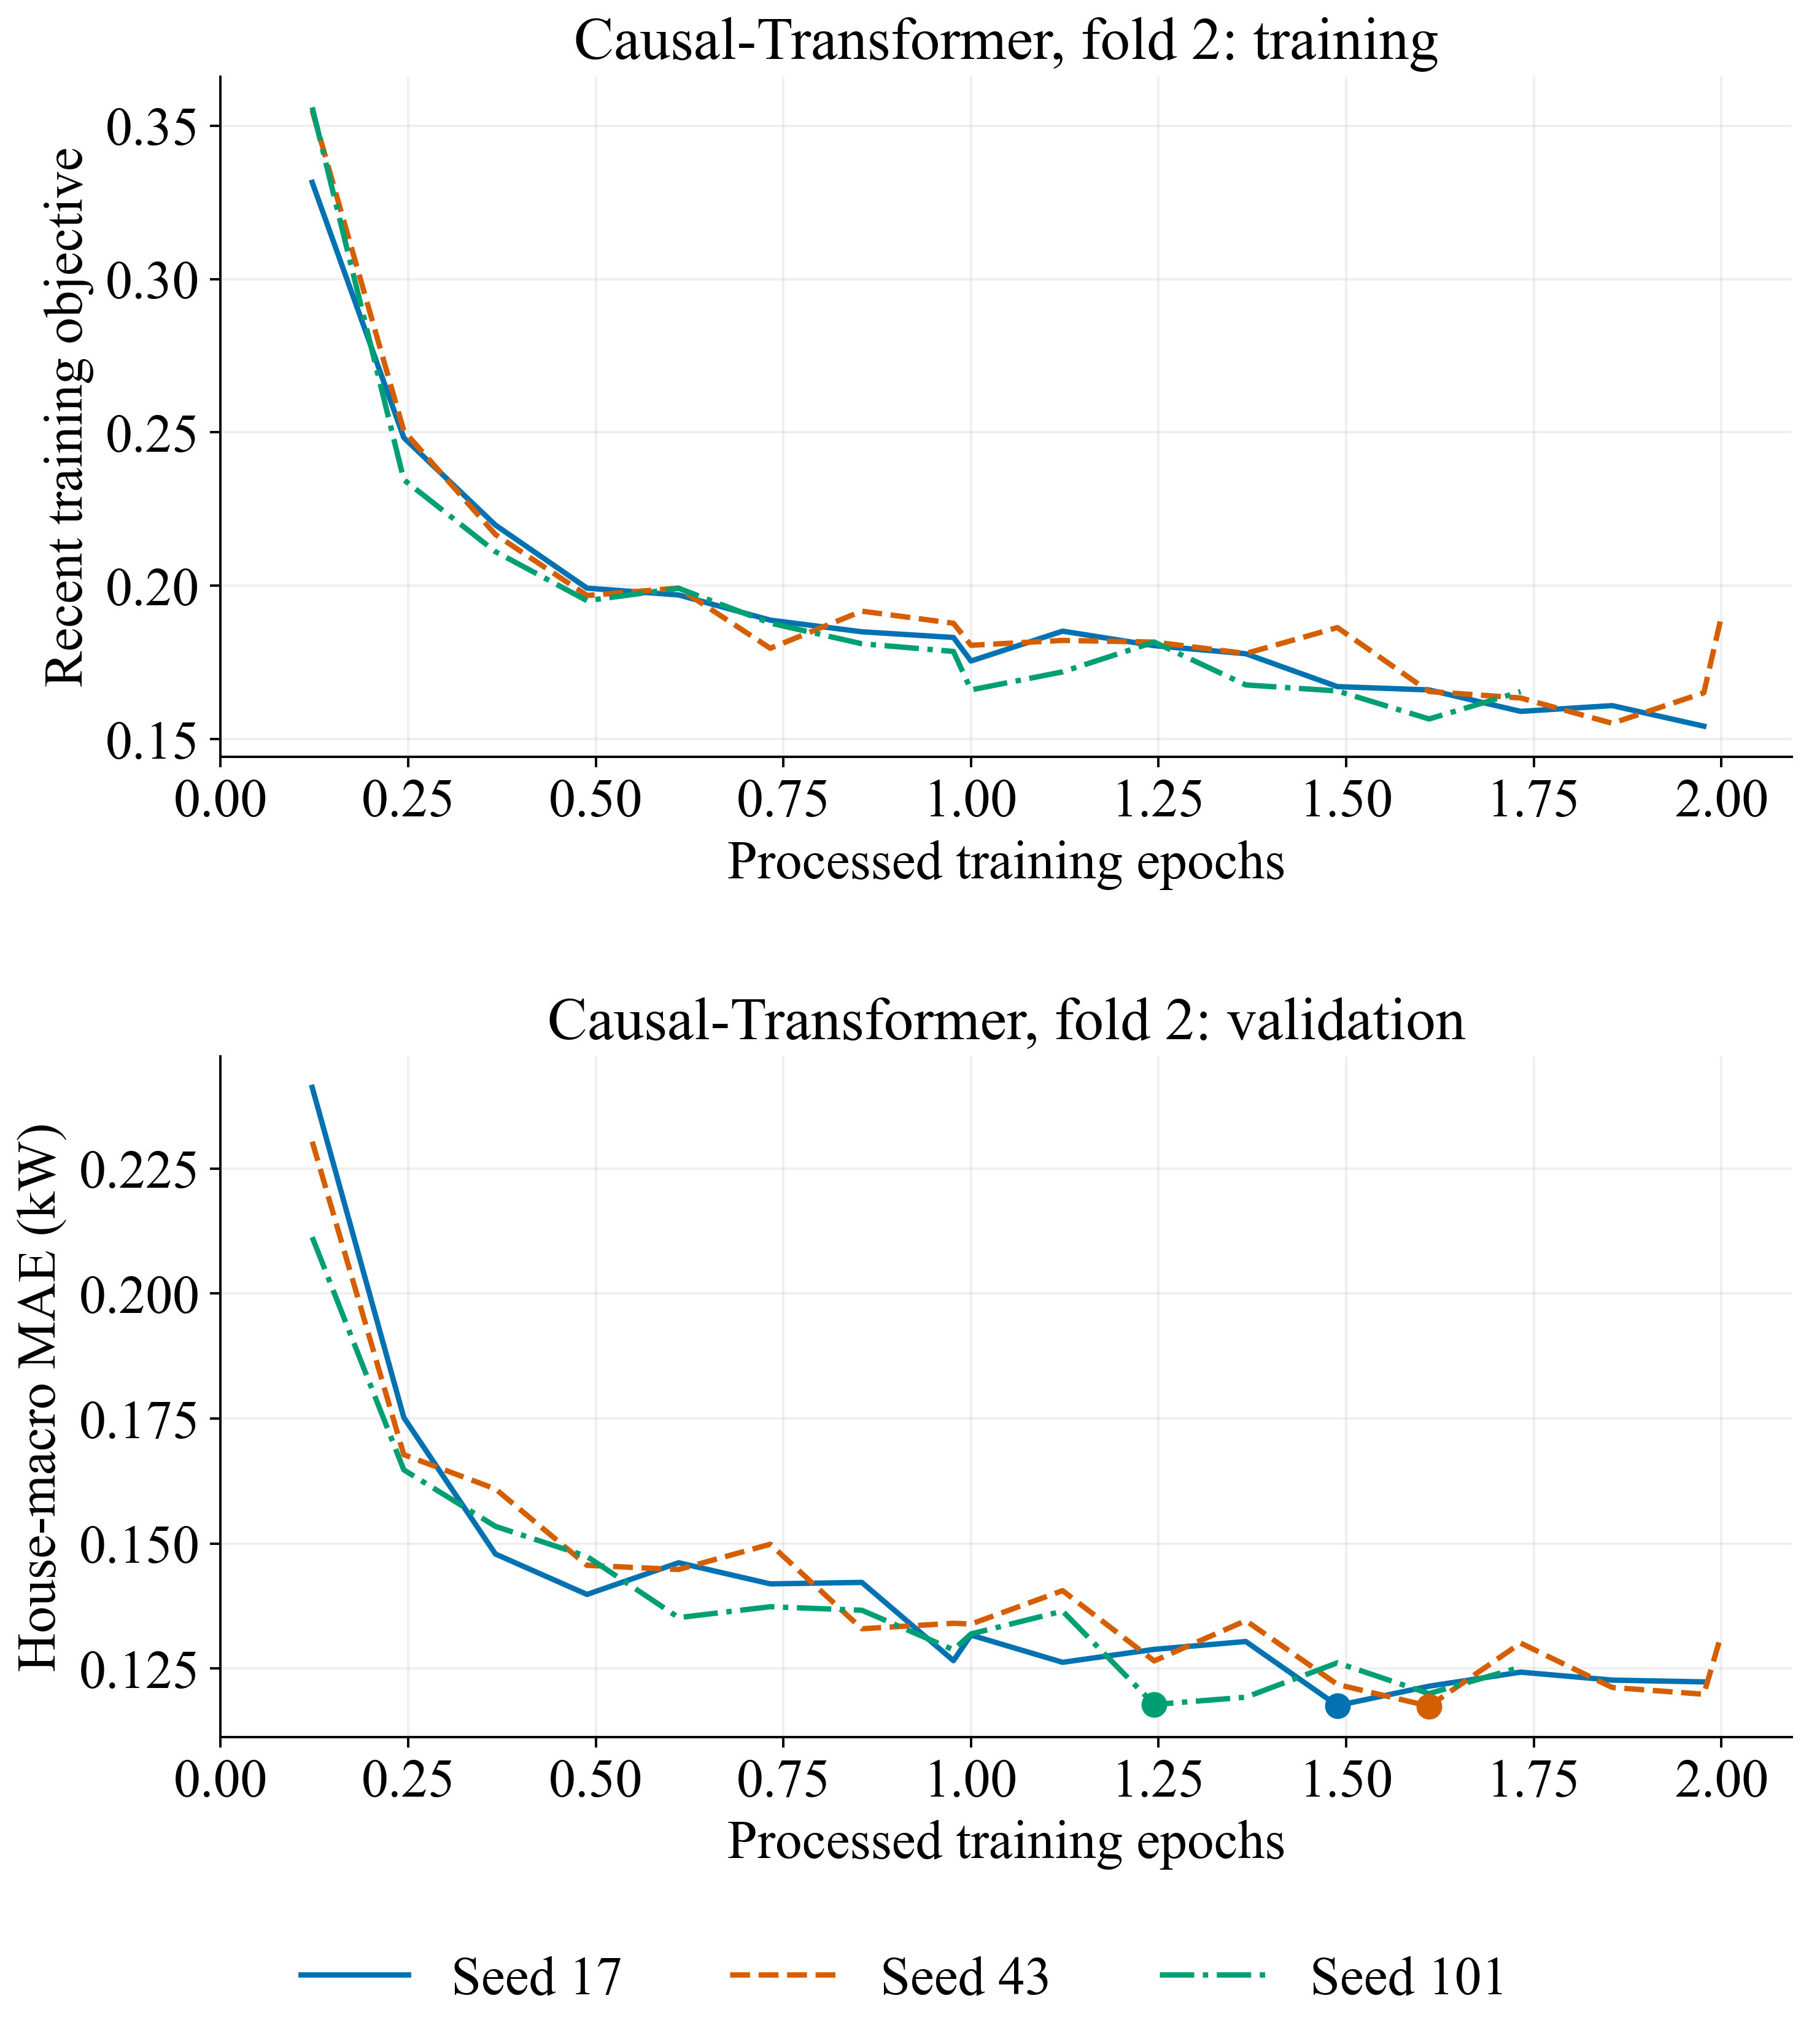

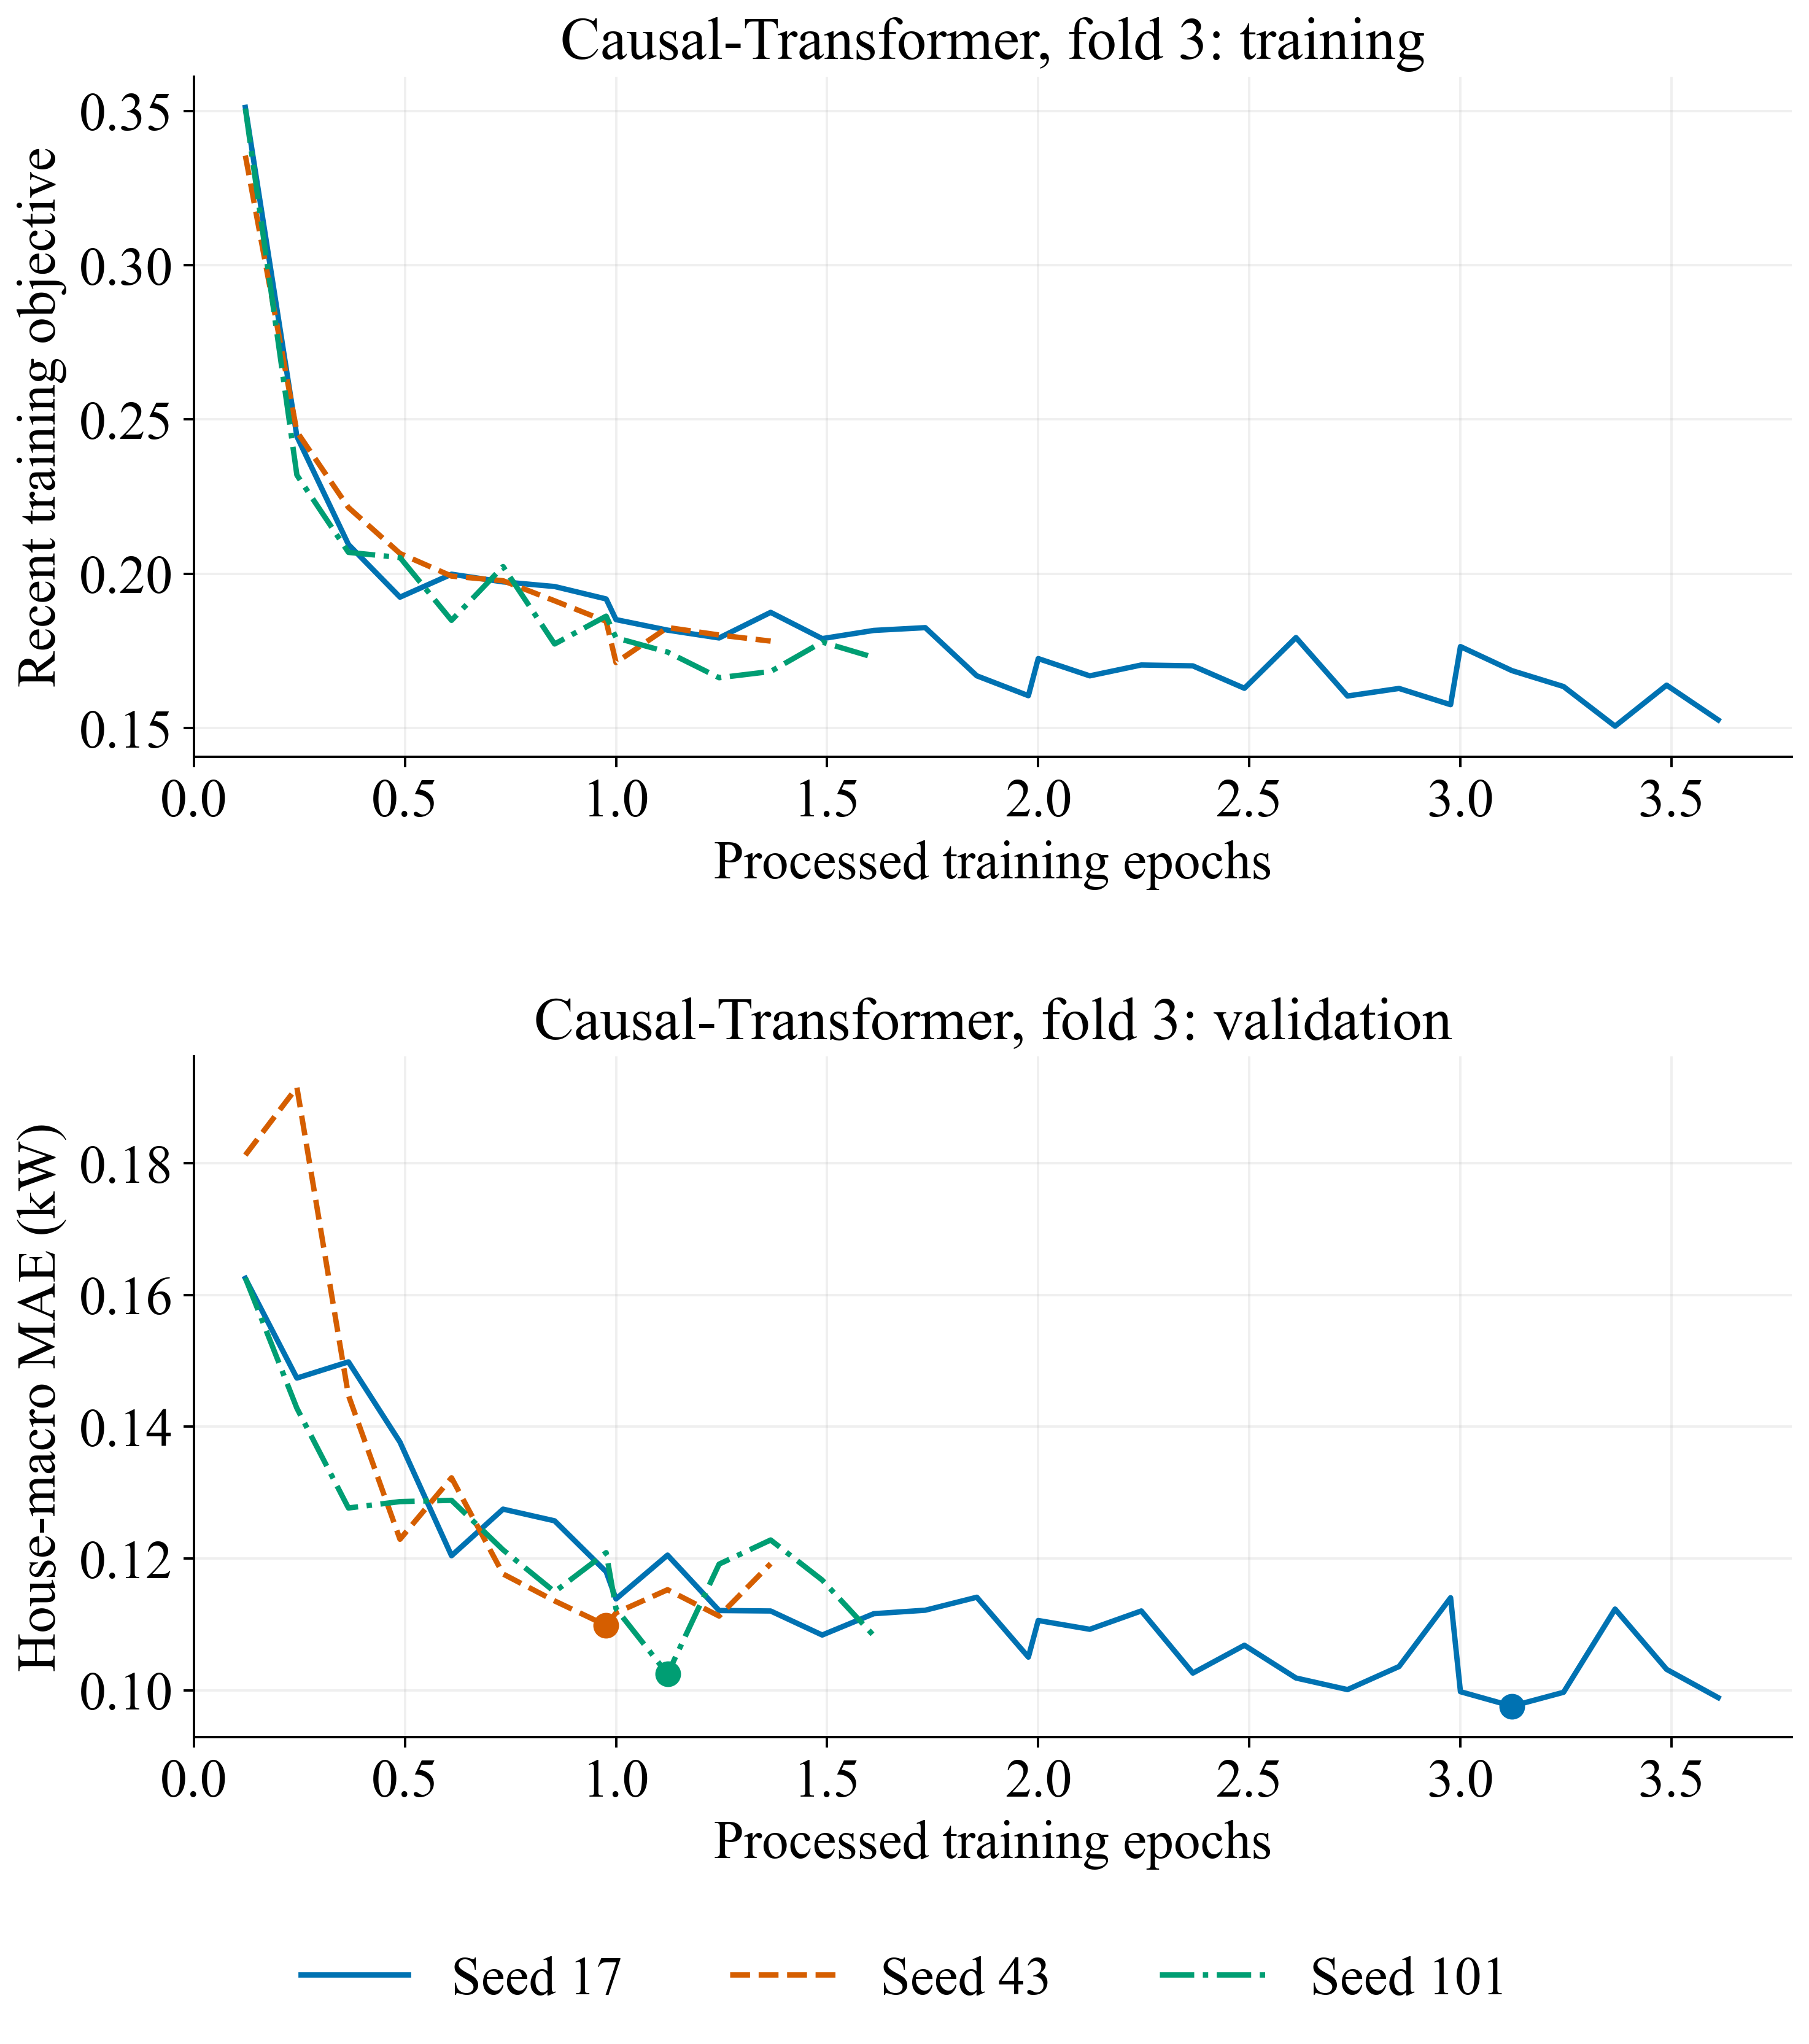

In [2]:
# Re-render archived scientific figures; this cell does not train models or recompute metrics.
def _presentation_nb04_8cf9d939():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_1_seed_17_history.csv': 'ce42a3c5d8cd56eff78d04f4469efb277f739b8203894e56ae35d2ba047b646a', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_1_seed_17_complete.json': 'c383cc47f2751a5d013f2b8d06f52f121c80d7ea95c1f1a88fcf1e862fdf28fc', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_1_seed_43_history.csv': '2ede550ffb15ec95d66f74f5787ae283952ccb759d343572379a73a6034757c4', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_1_seed_43_complete.json': 'dbca5efcfa28a3ce051bc7ae61b6d3c46075ce39b9378a73000009ae2b02487f', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_1_seed_101_history.csv': '62391f36b60b41987d9e1a1d791368ef33371c8d42628a9ef507f0ed590df6eb', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_1_seed_101_complete.json': '2256c4c438c6d986add06cf243fc1fbd447231c3777c9f027a595d1ccb318685', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_2_seed_17_history.csv': 'e0de3e331008d92ae851fac2ba7251f557e1db500c843daa35c1bd7e5bd839b5', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_2_seed_17_complete.json': 'fe3c6970af12337ae13145ff1c869b96548d63f551efc84683716bd7b2d7b7a6', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_2_seed_43_history.csv': 'e8c38ea7f889730ad149fa82852559fd4651b40a2d13f18b15ef13b59d49015b', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_2_seed_43_complete.json': 'd3f03d0182b357f4c08bb9f72f910c0c86277211b02bbf9359fcbd884590d046', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_2_seed_101_history.csv': 'd06456529a91a01010ce4a14f124bb6b5f7c270836cba370decebbe89aa32afa', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_2_seed_101_complete.json': 'e6f002e8b3cabd19c6d0c7f041e9972275e0d8951490b6e9fb8917c23dccd33f', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_3_seed_17_history.csv': 'f0864231e75a242c33b391dc313e3a442ba77f564a6189fef0a8b080fd1e839a', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_3_seed_17_complete.json': 'b5748cbf9226bbfb6d9e2f38dc63629a83b873cc503f02ab7aac1863b4507ebf', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_3_seed_43_history.csv': '99f823ac7a11bc0fb6d26e1839233d67d2d7b167b99a5438b5be754b4984ac06', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_3_seed_43_complete.json': '0c66148d6610d1b2fd40950974eef430b576da0ad07aea757841be751a260d21', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_3_seed_101_history.csv': '1d8c7e92b9eece8ec3758cf88faefe083fc1d9b92e5a4e881fd6547f09004afc', 'Models/modern/guldana_n3_20261007_v01/Causal-Transformer_fold_3_seed_101_complete.json': 'd194fc2fae1a5cbd6112d40f358d7acbc70734155343dda8a6414fc73c26fb28'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB04"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB04"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    family = 'Causal-Transformer'
    colors={17:"#0072B2",43:"#D55E00",101:"#009E73"}
    for fold in [1,2,3]:
        fig,axes=plt.subplots(2,1,figsize=(8.8,9.8))
        for seed, style in zip([17,43,101],["-","--","-."]):
            stem=f"{family}_fold_{fold}_seed_{seed}"
            history=pd.read_csv(ROOT / f"Models/modern/guldana_n3_20261007_v01/{stem}_history.csv")
            record=json.loads((ROOT / f"Models/modern/guldana_n3_20261007_v01/{stem}_complete.json").read_text())
            assert np.isfinite(history[["recent_mean_training_objective","inner_house_macro_MAE_kW"]]).all().all()
            x=history.examples_processed/record["training_queries_available"]
            axes[0].plot(x,history.recent_mean_training_objective,color=colors[seed],ls=style,label=f"Seed {seed}",lw=1.8)
            axes[1].plot(x,history.inner_house_macro_MAE_kW,color=colors[seed],ls=style,label=f"Seed {seed}",lw=1.8)
            chosen=np.flatnonzero(np.isclose(history.inner_house_macro_MAE_kW,record["best_inner_house_macro_MAE_kW"],rtol=0,atol=1e-12))
            assert len(chosen)>0
            k=chosen[0]
            axes[1].scatter([x.iloc[k]],[history.inner_house_macro_MAE_kW.iloc[k]],color=colors[seed],s=58,marker="o",zorder=4)
        axes[0].set(title=f"{family}, fold {fold}: training",ylabel="Recent training objective")
        axes[1].set(title=f"{family}, fold {fold}: validation",ylabel="House-macro MAE (kW)")
        for ax in axes:
            ax.set_xlabel("Processed training epochs");ax.set_xlim(left=0);_quiet_axes(ax)
        handles,names=axes[0].get_legend_handles_labels()
        fig.legend(handles,names,loc="lower center",bbox_to_anchor=(.5,.005),ncol=3,frameon=False)
        fig.tight_layout(rect=(0,.065,1,1),h_pad=2)
        _export(fig,f"26_causal_transformer_learning_fold_{fold}")

_presentation_nb04_8cf9d939()


### Transformer matched diagnostics

The complete comparison below requires every outer fold and prespecified seed. Conditional summaries retain their observed support; seed ranges describe fitting variation and are not population confidence intervals.

In [54]:
# Compare complete Transformer predictions on identical scenarios.
transformer_seed_metrics,transformer_model_summary,transformer_house_summary=modern_family_diagnostics("Causal-Transformer")

Model,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
Causal-Transformer,17,0.1144,0.3691,−0.0605,0.0008
ExtraTrees,17,0.1165,0.3357,−0.0074,0.0000
Observable age selector,17,0.1095,0.3401,−0.0066,0.0000
Last valid aggregate,17,0.1530,0.5549,−0.0017,0.0000
Causal-Transformer,43,0.1179,0.3640,−0.0495,0.0602
ExtraTrees,43,0.1160,0.3360,−0.0066,0.0000
Observable age selector,43,0.1100,0.3411,−0.0073,0.0000
Last valid aggregate,43,0.1525,0.5533,−0.0017,0.0000
Causal-Transformer,101,0.1186,0.3670,−0.0526,0.2938
ExtraTrees,101,0.1150,0.3355,−0.0062,0.0000


Model,Mean MAE (kW),Minimum seed MAE (kW),Maximum seed MAE (kW),Mean macro RMSE (kW),Mean bias (kW)
Causal-Transformer,0.1170,0.1144,0.1186,0.3667,−0.0542
ExtraTrees,0.1158,0.1150,0.1165,0.3357,−0.0067
Observable age selector,0.1093,0.1083,0.1100,0.3405,−0.0070
Last valid aggregate,0.1518,0.1499,0.1530,0.5517,−0.0011


house,Causal-Transformer,ExtraTrees,Observable age selector,Last valid aggregate
1,0.0758,0.0771,0.0715,0.1171
2,0.1618,0.1544,0.1432,0.2021
3,0.0881,0.0875,0.0833,0.1399
4,0.1011,0.1024,0.0965,0.1433
5,0.2457,0.2621,0.2528,0.3496
6,0.1122,0.1058,0.0998,0.1552
7,0.0697,0.0765,0.0726,0.0847
8,0.1071,0.1015,0.0980,0.1129
9,0.0623,0.0650,0.0622,0.0791
10,0.1457,0.1262,0.1130,0.1343


Missingness mode,Causal-Transformer,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
block,0.1503,0.1651,0.2580,0.1651,10,92696
mixed,0.1685,0.1807,0.2584,0.1807,10,92346
point,0.0751,0.0594,0.0451,0.0455,10,91617
sensor_dropout,0.0733,0.0576,0.0447,0.0451,10,91981


Gap minutes,Causal-Transformer,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
1,0.0742,0.0585,0.0449,0.0453,10,183598
5,0.1188,0.1141,0.1113,0.1141,10,61463
30,0.1698,0.1909,0.2800,0.1909,10,61836
120,0.1893,0.2132,0.3822,0.2132,10,61743


Auxiliary retention,Causal-Transformer,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
0.0000,0.1277,0.1257,0.1507,0.1179,10,73282
0.2500,0.1214,0.1200,0.1503,0.1132,10,74179
0.5000,0.1183,0.1167,0.1526,0.1100,10,73611
0.7500,0.1109,0.1105,0.1517,0.1043,10,74116
1.0000,0.1066,0.1065,0.1539,0.1011,10,73452


Observed auxiliary sensors,Causal-Transformer,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
0,0.1285,0.1267,0.1513,0.1190,10,109765
1,0.1240,0.1215,0.1503,0.1147,10,61278
2,0.1140,0.1129,0.1488,0.1064,10,64291
3,0.1106,0.1104,0.1533,0.1044,10,67566
4,0.1144,0.1164,0.1688,0.1094,7,41612
5,0.1492,0.1286,0.3167,0.1289,7,22660
6,0.1718,0.1314,0.1867,0.1108,1,1468


**Interpretation.** Transformer has a slightly higher mean MAE and macro RMSE than ExtraTrees under the complete matched OOF protocol. Its seed-specific ranking is not consistent, so the descriptive results do not establish overall superiority. The observable-age selector remains the strongest of these controls overall, although it was motivated by development diagnostics and remains exploratory.

The Transformer improves over ExtraTrees for long aggregate gaps and for block/mixed scenarios, while point and sensor-dropout scenarios favour recent-history controls. Increasing auxiliary retention is associated with lower error, but the comparison is conditional on the realized scenarios, not a causal intervention. Negative mean bias occurs for every seed. Household effects vary, and the fully observed auxiliary-count extreme represents only one household; it cannot support a general sensor-count conclusion.

The learning curves show declining training objectives followed by variable validation performance. Every retained fit reached the prescribed training subset and stopped by patience. Neither the checkpoint choice nor the following BRITS search uses outer labels.

### BRITS-prefix: first outer fold

The original bidirectional recurrence is restricted to the permitted prefix ending at the current query. Its backward branch therefore has no access to future timestamps. The prespecified CPU implementation, candidate list and time-accounting rules remain unchanged.

In [55]:
# Select BRITS-prefix in fold 1 using only the full inner-validation cohort.
brits_fold_1_selection=search_point_family(1,"BRITS-prefix")

Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
BRITS-prefix,1,1,60,0.0010,0.1467,192.0844,16380,wall_clock_budget
BRITS-prefix,1,2,120,0.0010,0.1677,202.6578,14848,wall_clock_budget
BRITS-prefix,1,3,60,0.0003,0.1771,191.5967,16380,wall_clock_budget
BRITS-prefix,1,4,120,0.0003,0.2107,201.7693,14528,wall_clock_budget


**BRITS search interpretation.** The shorter-window, higher-learning-rate candidate has the lowest inner MAE. Every trial reaches the wall-clock limit, including its final full inner check. The longer-window trials do not expose the complete search subset. This is evidence of compute censoring, not of convergence or a general architectural ranking; actual exposure and overruns remain part of the result.

### Reproducibility of classical search models

Each saved classical search model is reloaded twice and its full inner-validation MAE is recomputed and compared with the original score within a declared numerical tolerance. ExtraTrees prediction aggregation uses one thread for a fixed reduction order; fitted weights are left untouched. The initial Huber OOF predictions are compared directly with their saved per-query values.

In [57]:
# Audit every saved classical search checkpoint, including archived numerical attempts.
# Original trial-level prediction arrays were not stored; their aggregate selection scores were.
TRIAL_REPLAY_DIR=ROOT/"Predictions/checkpoint_replay"/RUN/"classical_trials"
TRIAL_REPLAY_DIR.mkdir(parents=True,exist_ok=True)
classical_trial_replay_records=[]
for fold in [1,2,3]:
    x,raw,meta,columns=load_modeling_inputs(fold,17)
    mask=meta.role.eq("inner_validation").to_numpy()
    inner_meta=meta.loc[mask].reset_index(drop=True)
    assert len(inner_meta)==10240
    checkpoint_paths=[]
    for family in CLASSICAL_NAMES:
        for trial in [1,2,3,4]:
            checkpoint_paths.append((family,trial,BASELINE_DIR/"trials"/f"fold_{fold}_{family}"/f"trial_{trial}.joblib","retained_search"))
    if fold==1:
        archive=BASELINE_DIR/"numerical_diagnostics/huber_initial_300_iterations"
        checkpoint_paths.extend(("Huber",trial,archive/"trials"/f"trial_{trial}.joblib","archived_initial_attempt") for trial in [1,2,3,4])
    for family,trial,path,scope in checkpoint_paths:
        original_hash=file_sha256(path)
        record=json.loads(path.with_suffix(".json").read_text())
        predictions=[]
        for replay in range(2):
            bundle=joblib.load(path)
            assert bundle["input_contract"]==INPUT_CONTRACT
            selected=[columns.index(name) for name in bundle["feature_columns"]]
            model=bundle["model"]
            # Fix summation order for tree aggregation without mutating the serialized estimator.
            if isinstance(model,ExtraTreesRegressor):model.set_params(n_jobs=1)
            with threadpool_limits(limits=4):
                predictions.append(np.asarray(model.predict(x[mask][:,selected]),dtype=np.float64))
            del model,bundle
        np.testing.assert_array_equal(predictions[0],predictions[1])
        actual=regression_summary(inner_meta,predictions[0])["House-macro MAE (kW)"]
        difference=abs(actual-record["inner_house_macro_MAE_kW"])
        assert difference<=1e-12,(path,difference)
        fixture=inner_meta[["observation_id","house","timestamp","y_kW"]].copy()
        fixture["reloaded_prediction_kW"]=predictions[0]
        fixture_path=TRIAL_REPLAY_DIR/f"{scope}_{family}_fold_{fold}_trial_{trial}.parquet"
        fixture.to_parquet(fixture_path,index=False)
        assert file_sha256(path)==original_hash
        classical_trial_replay_records.append({"Model":family,"Fold":fold,"Trial":trial,"Scope":scope,
            "Compared inner queries":len(inner_meta),"Saved inner MAE (kW)":record["inner_house_macro_MAE_kW"],
            "Reloaded inner MAE (kW)":actual,"MAE difference (kW)":difference,
            "Two-load maximum prediction difference":float(np.max(np.abs(predictions[0]-predictions[1]))),
            "Original checkpoint":str(path.relative_to(ROOT)),"Checkpoint SHA256":original_hash,
            "Current replay fixture":str(fixture_path.relative_to(ROOT)),"Fixture SHA256":file_sha256(fixture_path)})
        del predictions,fixture
    del x,raw,meta;gc.collect()
assert len(classical_trial_replay_records)==88
classical_trial_replay=pd.DataFrame(classical_trial_replay_records)
table(classical_trial_replay.drop(columns=["Original checkpoint","Checkpoint SHA256","Current replay fixture","Fixture SHA256"]),
    "classical_search_checkpoint_replay","Every saved classical trial: full inner-score reconstruction and exact agreement between two independent loads.",precision=12)
classical_trial_replay.to_csv(TABLES/"classical_search_checkpoint_replay_manifest.csv",index=False)
(ROOT/"Manifests/Runs"/RUN/"classical_trial_replay.json").write_text(json.dumps({
    "status":"completed","checkpoint_count":len(classical_trial_replay),
    "comparison_to_original_trial_predictions":"unavailable: original per-query trial arrays were not saved",
    "original_evidence":"saved inner house-macro MAE, tolerance 1e-12 kW",
    "new_evidence":"two independent loads agree exactly; current replay fixtures saved with hashes",
    "serialized_checkpoints_unchanged":True,"all_ExtraTrees_estimators_replay_threads":1,
    "manifest":str((TABLES/"classical_search_checkpoint_replay_manifest.csv").relative_to(ROOT))},indent=2)+"\n");


In [58]:
# Reproduce archived initial Huber OOF predictions, whose original row-level outputs are available.
archive=BASELINE_DIR/"numerical_diagnostics/huber_initial_300_iterations"
archived_huber_reload=[]
for seed in [17,43,101]:
    x,raw,meta,columns=load_modeling_inputs(1,seed)
    mask=meta.role.eq("outer_validation").to_numpy()
    outer_meta=meta.loc[mask].reset_index(drop=True)
    path=archive/f"Huber_fold_1_seed_{seed}.joblib"
    original_hash=file_sha256(path)
    bundle=joblib.load(path)
    selected=[columns.index(name) for name in bundle["feature_columns"]]
    with threadpool_limits(limits=4):
        actual=np.asarray(bundle["model"].predict(x[mask][:,selected]),dtype=np.float64)
    expected=pd.read_parquet(archive/f"Huber_fold_1_seed_{seed}.parquet")
    pd.testing.assert_series_equal(outer_meta.observation_id,expected.observation_id)
    np.testing.assert_array_equal(actual,expected.prediction_kW.to_numpy())
    assert file_sha256(path)==original_hash
    archived_huber_reload.append({"Model":"Archived initial Huber","Fold":1,"Seed":seed,
        "Compared original OOF predictions":len(actual),"Maximum absolute difference":float(np.max(np.abs(actual-expected.prediction_kW.to_numpy()))),
        "Checkpoint SHA256":original_hash,"Prediction SHA256":file_sha256(archive/f"Huber_fold_1_seed_{seed}.parquet")})
    del x,raw,meta,bundle;gc.collect()
table(pd.DataFrame(archived_huber_reload).drop(columns=["Checkpoint SHA256","Prediction SHA256"]),
    "archived_initial_huber_checkpoint_replay","Exact replay against the original archived initial Huber OOF arrays.",precision=0)
(ROOT/"Manifests/Runs"/RUN/"archived_initial_huber_replay.json").write_text(json.dumps(archived_huber_reload,indent=2)+"\n");


### BRITS-prefix: retained fits in the first outer fold

Use the selected inner-only configuration with each prespecified seed. Report exposure and stopping reason for each fit. The shared wall-clock ceiling may limit the number of training queries actually seen by this recurrent implementation.

In [59]:
# Fit and fully replay the selected first-fold BRITS models.
brits_fold_1_resources=[]
for seed in [17,43,101]:
    brits_fold_1_resources.append(final_point_fit(1,"BRITS-prefix",seed))

Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,1,17,0.1261,0.3912,−0.0663,0.8301


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,1,17,610.7409,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,1,43,0.1292,0.3833,−0.0472,0.2466


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,1,43,611.4155,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,1,101,0.1267,0.3802,−0.0484,0.0488


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,1,101,610.9887,65530,wall_clock_budget


### BRITS: first-fold interpretation and independent second-fold selection

All retained seeds used the complete prespecified training-query population and stopped at the wall-clock ceiling. The best inner checkpoints were therefore selected from resource-censored trajectories; the learning curves do not establish convergence. The outer errors and negative biases above are computed from actual held-out predictions. No configuration is changed in response to these outer errors.

The next search repeats the same candidate list on the second chronological fold, using its own training and inner-validation queries only. This separation tests whether the inner-selected history and learning rate remain stable as the training period expands.

In [60]:
# Select BRITS using only fold-2 inner validation.
brits_fold_2_selection=search_point_family(2,"BRITS-prefix")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
BRITS-prefix,2,1,60,0.0010,0.1534,191.1685,16380,wall_clock_budget
BRITS-prefix,2,2,120,0.0010,0.1802,197.8358,16000,wall_clock_budget
BRITS-prefix,2,3,60,0.0003,0.1966,190.9433,16380,wall_clock_budget
BRITS-prefix,2,4,120,0.0003,0.2210,199.9284,16000,wall_clock_budget


### BRITS: second-fold selection and retained fits

The shorter history with the larger learning rate again has the lowest inner error among the fixed candidates. Every trial reached its time ceiling; the longer-history trials stopped before seeing the complete search cohort. Consequently, this is a budget-dependent selection, not evidence that longer context is intrinsically unhelpful. Outer targets were not used for the choice.

The selected configuration is now fitted on the full common training-query cohort for each retained seed. The following cell adds progress reporting to OOF inference; batch size, ordered inputs and numerical prediction operations are unchanged. The reporting overhead is included in subsequent OOF timings.

In [61]:
# Show live progress during complete OOF inference and checkpoint replay.
# This preserves batch size, ordered inputs, numerical operations and all predictions.
@torch.no_grad()
def predict_point_model(model,cache,rows,config,device,purpose="Prediction"):
    model.eval();predictions=[]
    show_progress=len(rows)>10240
    started=time.perf_counter()
    progress=display(pd.DataFrame(columns=["Phase","Completed queries","Total queries","Elapsed seconds"]),display_id=True) if show_progress else None
    for offset in range(0,len(rows),32):
        inputs,_=cache.batch(rows[offset:offset+32],config["history"],device)
        prediction=model(inputs)["prediction"]
        assert torch.isfinite(prediction).all()
        predictions.append(prediction.detach().cpu().numpy().astype(np.float64))
        if show_progress and (offset==0 or (offset+32)%4096==0 or offset+32>=len(rows)):
            progress.update(pd.DataFrame([{"Phase":purpose,"Completed queries":min(offset+32,len(rows)),
                "Total queries":len(rows),"Elapsed seconds":time.perf_counter()-started}])
                .style.hide(axis="index").format({"Elapsed seconds":"{:.2f}"}))
    return np.concatenate(predictions)*preprocessors[cache.fold].state["target_scale"]

def final_point_fit(fold,family,seed):
    selection=json.loads((MODERN_DIR/f"selection_{family}_fold_{fold}.json").read_text())
    config=selection["parameters"];assert selection["protocol_sha256"]==MODERN_PROTOCOL_HASH
    build_neural_cache(fold,seed);cache=NeuralInputCache(fold,seed)
    stem=f"{family}_fold_{fold}_seed_{seed}";complete=MODERN_DIR/f"{stem}_complete.json"
    if complete.exists():
        resource_record=json.loads(complete.read_text())
        assert file_sha256(MODERN_DIR/f"{stem}.pt")==resource_record["checkpoint_sha256"]
        assert file_sha256(PRED_DIR/f"{stem}.parquet")==resource_record["prediction_sha256"]
        result=pd.read_parquet(PRED_DIR/f"{stem}.parquet")
    else:
        model,history,resource_record=fit_point_model(family,config,cache,seed,600,False,stem)
        outer_rows=np.flatnonzero(cache.metadata.role.eq("outer_validation").to_numpy());assert len(outer_rows)==40960
        started=time.perf_counter()
        prediction=predict_point_model(model,cache,outer_rows,config,torch.device(MODERN_DEVICES[family]),purpose="OOF inference")
        resource_record["OOF_prediction_seconds"]=time.perf_counter()-started
        replay_started=time.perf_counter()
        bundle=torch.load(MODERN_DIR/f"{stem}.pt",map_location="cpu",weights_only=True)
        restored=MODEL_CLASSES[family](**config).to(MODERN_DEVICES[family]);restored.load_state_dict(bundle["state_dict"]);restored.eval()
        # Complete same-process replay; fresh-kernel reproduction is required at the next notebook gate.
        repeated=predict_point_model(restored,cache,outer_rows,config,torch.device(MODERN_DEVICES[family]),purpose="Checkpoint replay")
        np.testing.assert_array_equal(prediction,repeated)
        resource_record["checkpoint_load_and_replay_seconds"]=time.perf_counter()-replay_started
        resource_record["execution_kernel_pid"]=os.getpid()
        resource_record["OOF_progress_reporting"]="one live row updated every 4096 queries; included in OOF timing"
        result=cache.metadata.iloc[outer_rows].reset_index(drop=True).copy();result["prediction_kW"]=prediction
        result.to_parquet(PRED_DIR/f"{stem}.parquet",index=False)
        resource_record.update(checkpoint_sha256=file_sha256(MODERN_DIR/f"{stem}.pt"),
            prediction_sha256=file_sha256(PRED_DIR/f"{stem}.parquet"),checkpoint_bytes=(MODERN_DIR/f"{stem}.pt").stat().st_size,
            same_process_replay_maximum_difference=0.,fresh_kernel_replay="pending")
        complete.write_text(json.dumps(resource_record,indent=2)+"\n")
        del model,restored
    quality_row={"Model":family,"Fold":fold,"Seed":seed,**regression_summary(result,result.prediction_kW.to_numpy())}
    table(pd.DataFrame([quality_row]),f"modern_OOF_{stem}",
        f"Table 13.{stem}. Actual OOF predictions after independent inner selection; no outer-label tuning.")
    table(pd.DataFrame([{"Model":family,"Fold":fold,"Seed":seed,"Fit seconds":resource_record["fit_seconds"],
        "Seen train queries":resource_record["unique_training_queries_seen"],"Stop reason":resource_record["stop_reason"]}]),
        f"modern_fit_{stem}",f"Table 13r.{stem}. Training exposure and stopping rule for the same saved model.")
    del cache;gc.collect()
    if torch.backends.mps.is_available():torch.mps.empty_cache()
    return resource_record


# Fit and fully replay the selected second-fold BRITS models.
brits_fold_2_resources=[]
for seed in [17,43,101]:
    brits_fold_2_resources.append(final_point_fit(2,"BRITS-prefix",seed))


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,2,17,0.1249,0.3511,−0.0644,0.0928


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,2,17,611.5179,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,2,43,0.1317,0.3742,−0.0959,0.2490


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,2,43,611.1331,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,2,101,0.1288,0.3677,−0.0758,0.0977


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,2,101,610.3819,65530,wall_clock_budget


### BRITS second-fold interpretation

All retained second-fold seeds have now produced complete OOF predictions. Every fit used the complete training-query cohort and stopped at its time ceiling. The seed differences and negative biases above remain part of the evidence; the third chronological fold is still required before a complete BRITS comparison.

### BRITS: third chronological fold

BRITS continues on the last chronological development fold. The first two folds completed all retained seeds. Their remaining variation does not justify changing the prespecified search space or examining protected targets. The following search again uses only the current fold’s complete inner-validation cohort.

In [66]:
# Select BRITS using only fold-3 inner validation.
brits_fold_3_selection=search_point_family(3,"BRITS-prefix")

Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
BRITS-prefix,3,1,60,0.0010,0.1391,190.8957,16380,wall_clock_budget
BRITS-prefix,3,2,120,0.0010,0.1521,202.0729,14080,wall_clock_budget
BRITS-prefix,3,3,60,0.0003,0.1535,190.9103,16380,wall_clock_budget
BRITS-prefix,3,4,120,0.0003,0.2011,202.6097,14112,wall_clock_budget


### Third-fold BRITS selection and retained fitting

The inner-validation comparison selects the shorter history with the higher declared learning rate, matching the selections in the earlier folds. Every search fit reached the time ceiling, and the longer-history candidates saw fewer unique training queries. The conclusion therefore concerns the fixed local resource protocol, not converged performance under unlimited training.

The retained fits use the unchanged selected configuration and prescribed seeds. The fitting routine additionally displays the optimizer step, processed training population and phase approximately every ten seconds; this display overhead is included in measured fit time. The objective, checkpoint metric, stopping rule and data remain unchanged.

In [67]:
# A live phase row is separate from the unchanged scientific checkpoint-history table.
def update_training_phase(handle,phase,step,seen,started):
    handle.update(pd.DataFrame([{"Phase":phase,"Optimizer step":step,"Seen training queries":seen,
        "Elapsed seconds":time.perf_counter()-started}])
        .style.hide(axis="index").format({"Elapsed seconds":"{:.1f}"}))

def fit_point_model(family,config,cache,seed,seconds,search,stem):
    device=torch.device(MODERN_DEVICES[family]);seed_everything(seed)
    model=MODEL_CLASSES[family](**config).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config["learning_rate"],weight_decay=config["weight_decay"])
    frame=cache.metadata
    train_rows=np.flatnonzero((frame.role.eq("train") & (frame.search_train if search else True)).to_numpy())
    inner_rows=np.flatnonzero(frame.role.eq("inner_validation").to_numpy())
    assert len(train_rows)==(16380 if search else 65530) and len(inner_rows)==10240
    inner_meta=frame.iloc[inner_rows].reset_index(drop=True)
    history=[];best=float("inf");best_state=None;stale=0;step=0;examples=0;seen=set();recent_loss=[]
    rng=np.random.default_rng(seed)
    memory=KernelMemorySampler(device);memory.start();synchronize(device);started=time.perf_counter()
    last_check=0;reason="epoch_limit";progress=display(pd.DataFrame(columns=["Optimizer step","Seen queries","Inner MAE (kW)"]),display_id=True)
    heartbeat=display(pd.DataFrame(columns=["Phase","Optimizer step","Seen training queries","Elapsed seconds"]),display_id=True)
    last_progress_seconds=0.
    update_training_phase(heartbeat,"Training",0,0,started)
    try:
        stop=False
        for epoch in range(1,101):
            order=rng.permutation(train_rows)
            for offset in range(0,len(order),config["batch_size"]):
                rows=order[offset:offset+config["batch_size"]];model.train()
                inputs,labels=cache.batch(rows,config["history"],device,supervision=True)
                optimizer.zero_grad(set_to_none=True)
                result=model(inputs);loss=endpoint_training_loss(family,result,inputs,labels)
                assert torch.isfinite(loss),f"{family}: nonfinite objective"
                loss.backward()
                norm=torch.nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
                optimizer.step();synchronize(device)
                step+=1;examples+=len(rows);seen.update(rows.tolist());recent_loss.append(float(loss.detach().cpu()))
                elapsed=time.perf_counter()-started
                if elapsed-last_progress_seconds>=10:
                    update_training_phase(heartbeat,"Training",step,len(seen),started)
                    last_progress_seconds=elapsed
                at_epoch_end=offset+config["batch_size"]>=len(order)
                if step-last_check>=250 or at_epoch_end or elapsed>=seconds:
                    update_training_phase(heartbeat,"Inner validation",step,len(seen),started)
                    prediction=predict_point_model(model,cache,inner_rows,config,device)
                    score=regression_summary(inner_meta,prediction)["House-macro MAE (kW)"]
                    elapsed=time.perf_counter()-started
                    row={"epoch":epoch,"step":step,"seen_queries":len(seen),"examples_processed":examples,
                        "elapsed_seconds":elapsed,"recent_mean_training_objective":float(np.mean(recent_loss)),
                        "inner_house_macro_MAE_kW":score,"gradient_norm":float(norm.detach().cpu())}
                    history.append(row);recent_loss=[];last_check=step
                    if score<best-1e-5:
                        best=score;best_state={key:value.detach().cpu().clone() for key,value in model.state_dict().items()};stale=0
                    else:stale+=1
                    pd.DataFrame(history).to_csv(MODERN_DIR/f"{stem}_history.csv",index=False)
                    progress.update(pd.DataFrame(history)[["step","seen_queries","elapsed_seconds","inner_house_macro_MAE_kW"]]
                        .rename(columns={"step":"Optimizer step","seen_queries":"Seen queries","elapsed_seconds":"Elapsed seconds",
                                         "inner_house_macro_MAE_kW":"Inner MAE (kW)"}).style.hide(axis="index").format(precision=4).set_caption(stem))
                    update_training_phase(heartbeat,"Training",step,len(seen),started)
                    last_progress_seconds=elapsed
                    if elapsed>=seconds:reason="wall_clock_budget";stop=True
                    elif stale>=4:reason="inner_patience";stop=True
                    if stop:break
            if stop:break
        assert best_state is not None
        model.load_state_dict(best_state);model.eval();synchronize(device)
        duration=time.perf_counter()-started
        update_training_phase(heartbeat,"Fit complete",step,len(seen),started)
    finally:
        memory_frame=memory.stop()
        memory_frame.to_csv(MODERN_DIR/f"{stem}_memory.csv",index=False)
    resource_record={"family":family,"fold":cache.fold,"seed":seed,"fit_seconds":duration,"budget_seconds":seconds,
        "budget_censored":reason=="wall_clock_budget","stop_reason":reason,"optimizer_steps":step,
        "training_queries_available":len(train_rows),"unique_training_queries_seen":len(seen),"examples_processed":examples,
        "best_inner_house_macro_MAE_kW":best,"device":str(device),"cpu_threads":4,"parameters":sum(p.numel() for p in model.parameters()),
        "baseline_kernel_RSS_bytes":memory.baseline,"peak_kernel_RSS_bytes":int(memory_frame.RSS_bytes.max()),
        "peak_MPS_allocated_bytes":int(memory_frame.MPS_allocated_bytes.max()) if "MPS_allocated_bytes" in memory_frame else None,
        "peak_MPS_driver_bytes":int(memory_frame.MPS_driver_bytes.max()) if "MPS_driver_bytes" in memory_frame else None,
        "memory_scope":"whole kernel sampled every 20 ms; includes resident data and allocator cache",
        "fit_progress_reporting":"one live phase row approximately every 10 seconds and at validation boundaries; UI overhead included in fit time"}
    bundle={"state_dict":best_state,"family":family,"parameters":config,"fold":cache.fold,"seed":seed,
        "input_contract":INPUT_CONTRACT,"preprocessing_state":str((PREP/f"fold_{cache.fold}_preprocessing.json").relative_to(ROOT)),
        "modeling_id_sha256":compute_protocol["modeling_id_sha256"],"search_protocol_sha256":MODERN_PROTOCOL_HASH,
        "training_id_sha256":hashlib.sha256("\n".join(frame.iloc[train_rows].observation_id).encode()).hexdigest()}
    torch.save(bundle,MODERN_DIR/f"{stem}.pt")
    (MODERN_DIR/f"{stem}_resources.json").write_text(json.dumps(resource_record,indent=2)+"\n")
    return model,pd.DataFrame(history),resource_record

# Fit and fully replay the selected third-fold BRITS models.
brits_fold_3_resources=[]
for seed in [17,43,101]:
    brits_fold_3_resources.append(final_point_fit(3,"BRITS-prefix",seed))


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,3,17,0.1266,0.3284,−0.0583,0.0488


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,3,17,611.4634,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,3,43,0.1209,0.3268,−0.0715,0.0464


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,3,43,606.4675,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,3,101,0.1247,0.3325,−0.0515,0.3442


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
BRITS-prefix,3,101,605.7440,65530,wall_clock_budget


### Complete BRITS learning dynamics

All retained folds and seeds are complete. Every retained fit reached the time ceiling after seeing the complete prescribed training subset. The following curves show actual optimization exposure and selected inner checkpoints; completion under the ceiling is not evidence of optimizer convergence.

In [68]:
# Inspect actual BRITS training and inner-validation histories.
modern_learning_report("BRITS-prefix",27)

Fold,Seed,Selected step,Stop reason,Fit seconds,Training queries
1,17,3140,wall_clock_budget,610.7409,65530
1,43,3048,wall_clock_budget,611.4155,65530
1,101,3191,wall_clock_budget,610.9887,65530
2,17,3216,wall_clock_budget,611.5179,65530
2,43,3223,wall_clock_budget,611.1331,65530
2,101,3048,wall_clock_budget,610.3819,65530
3,17,2298,wall_clock_budget,611.4634,65530
3,43,2798,wall_clock_budget,606.4675,65530
3,101,2298,wall_clock_budget,605.7440,65530


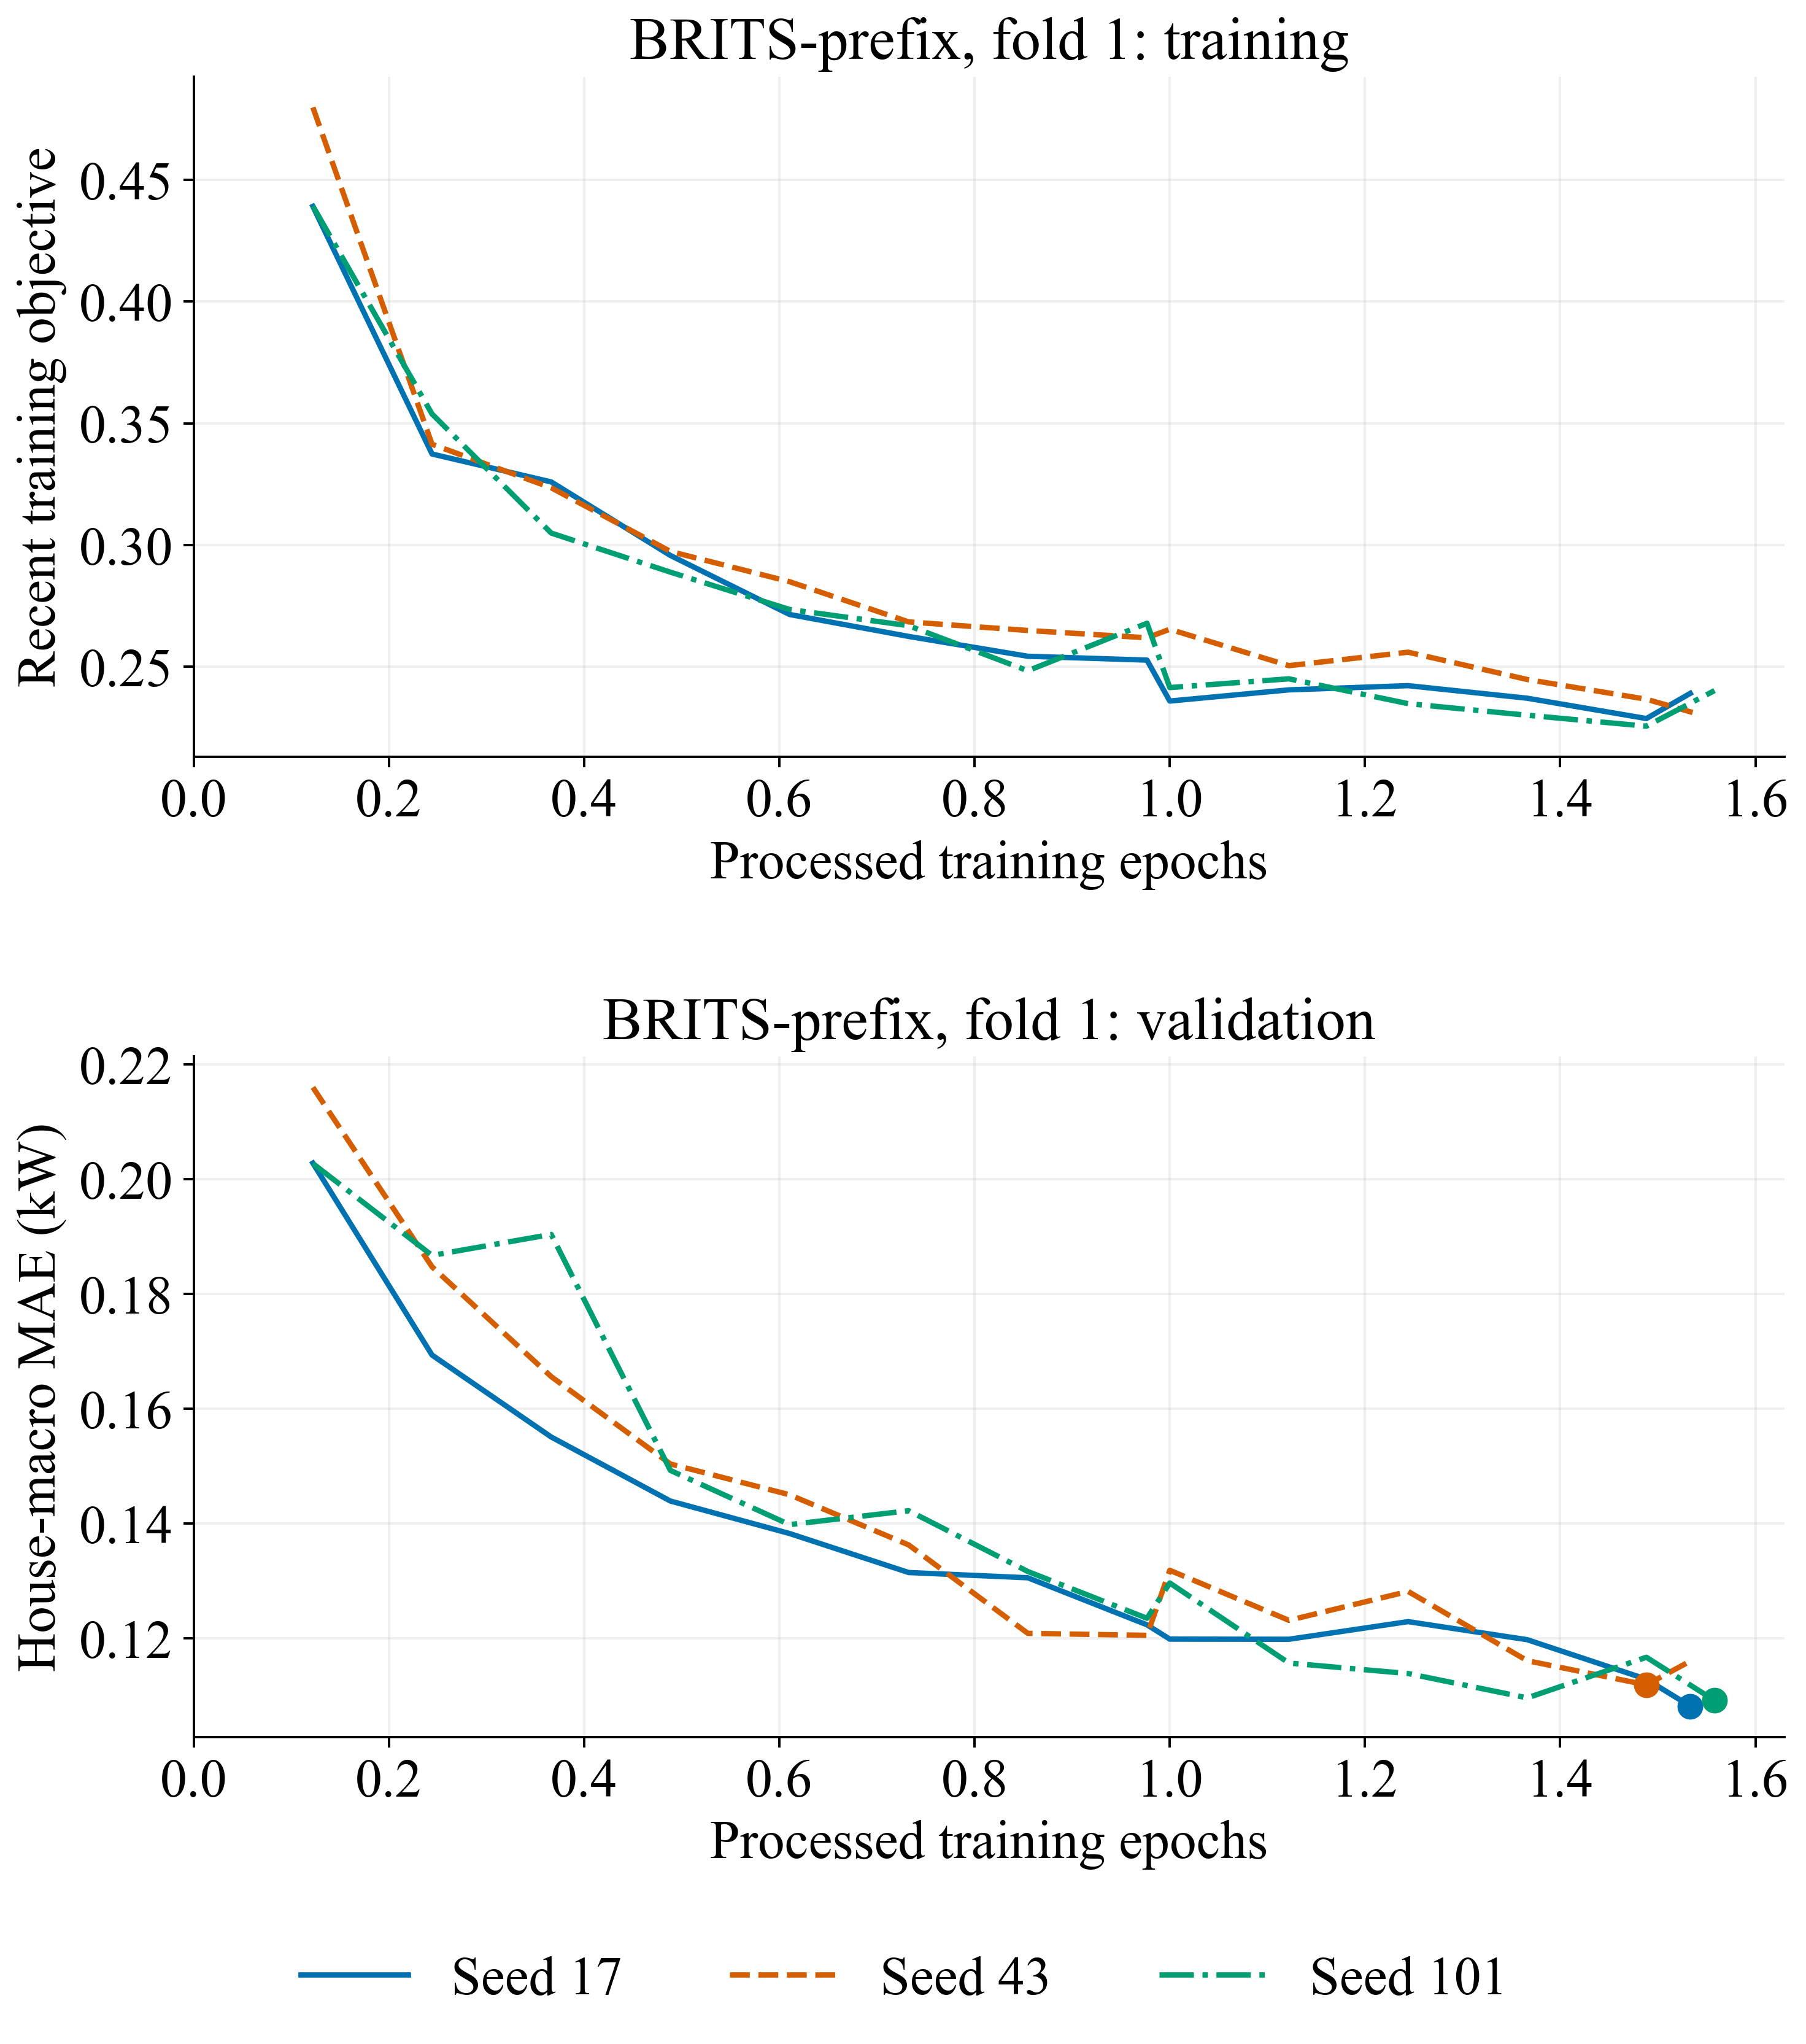

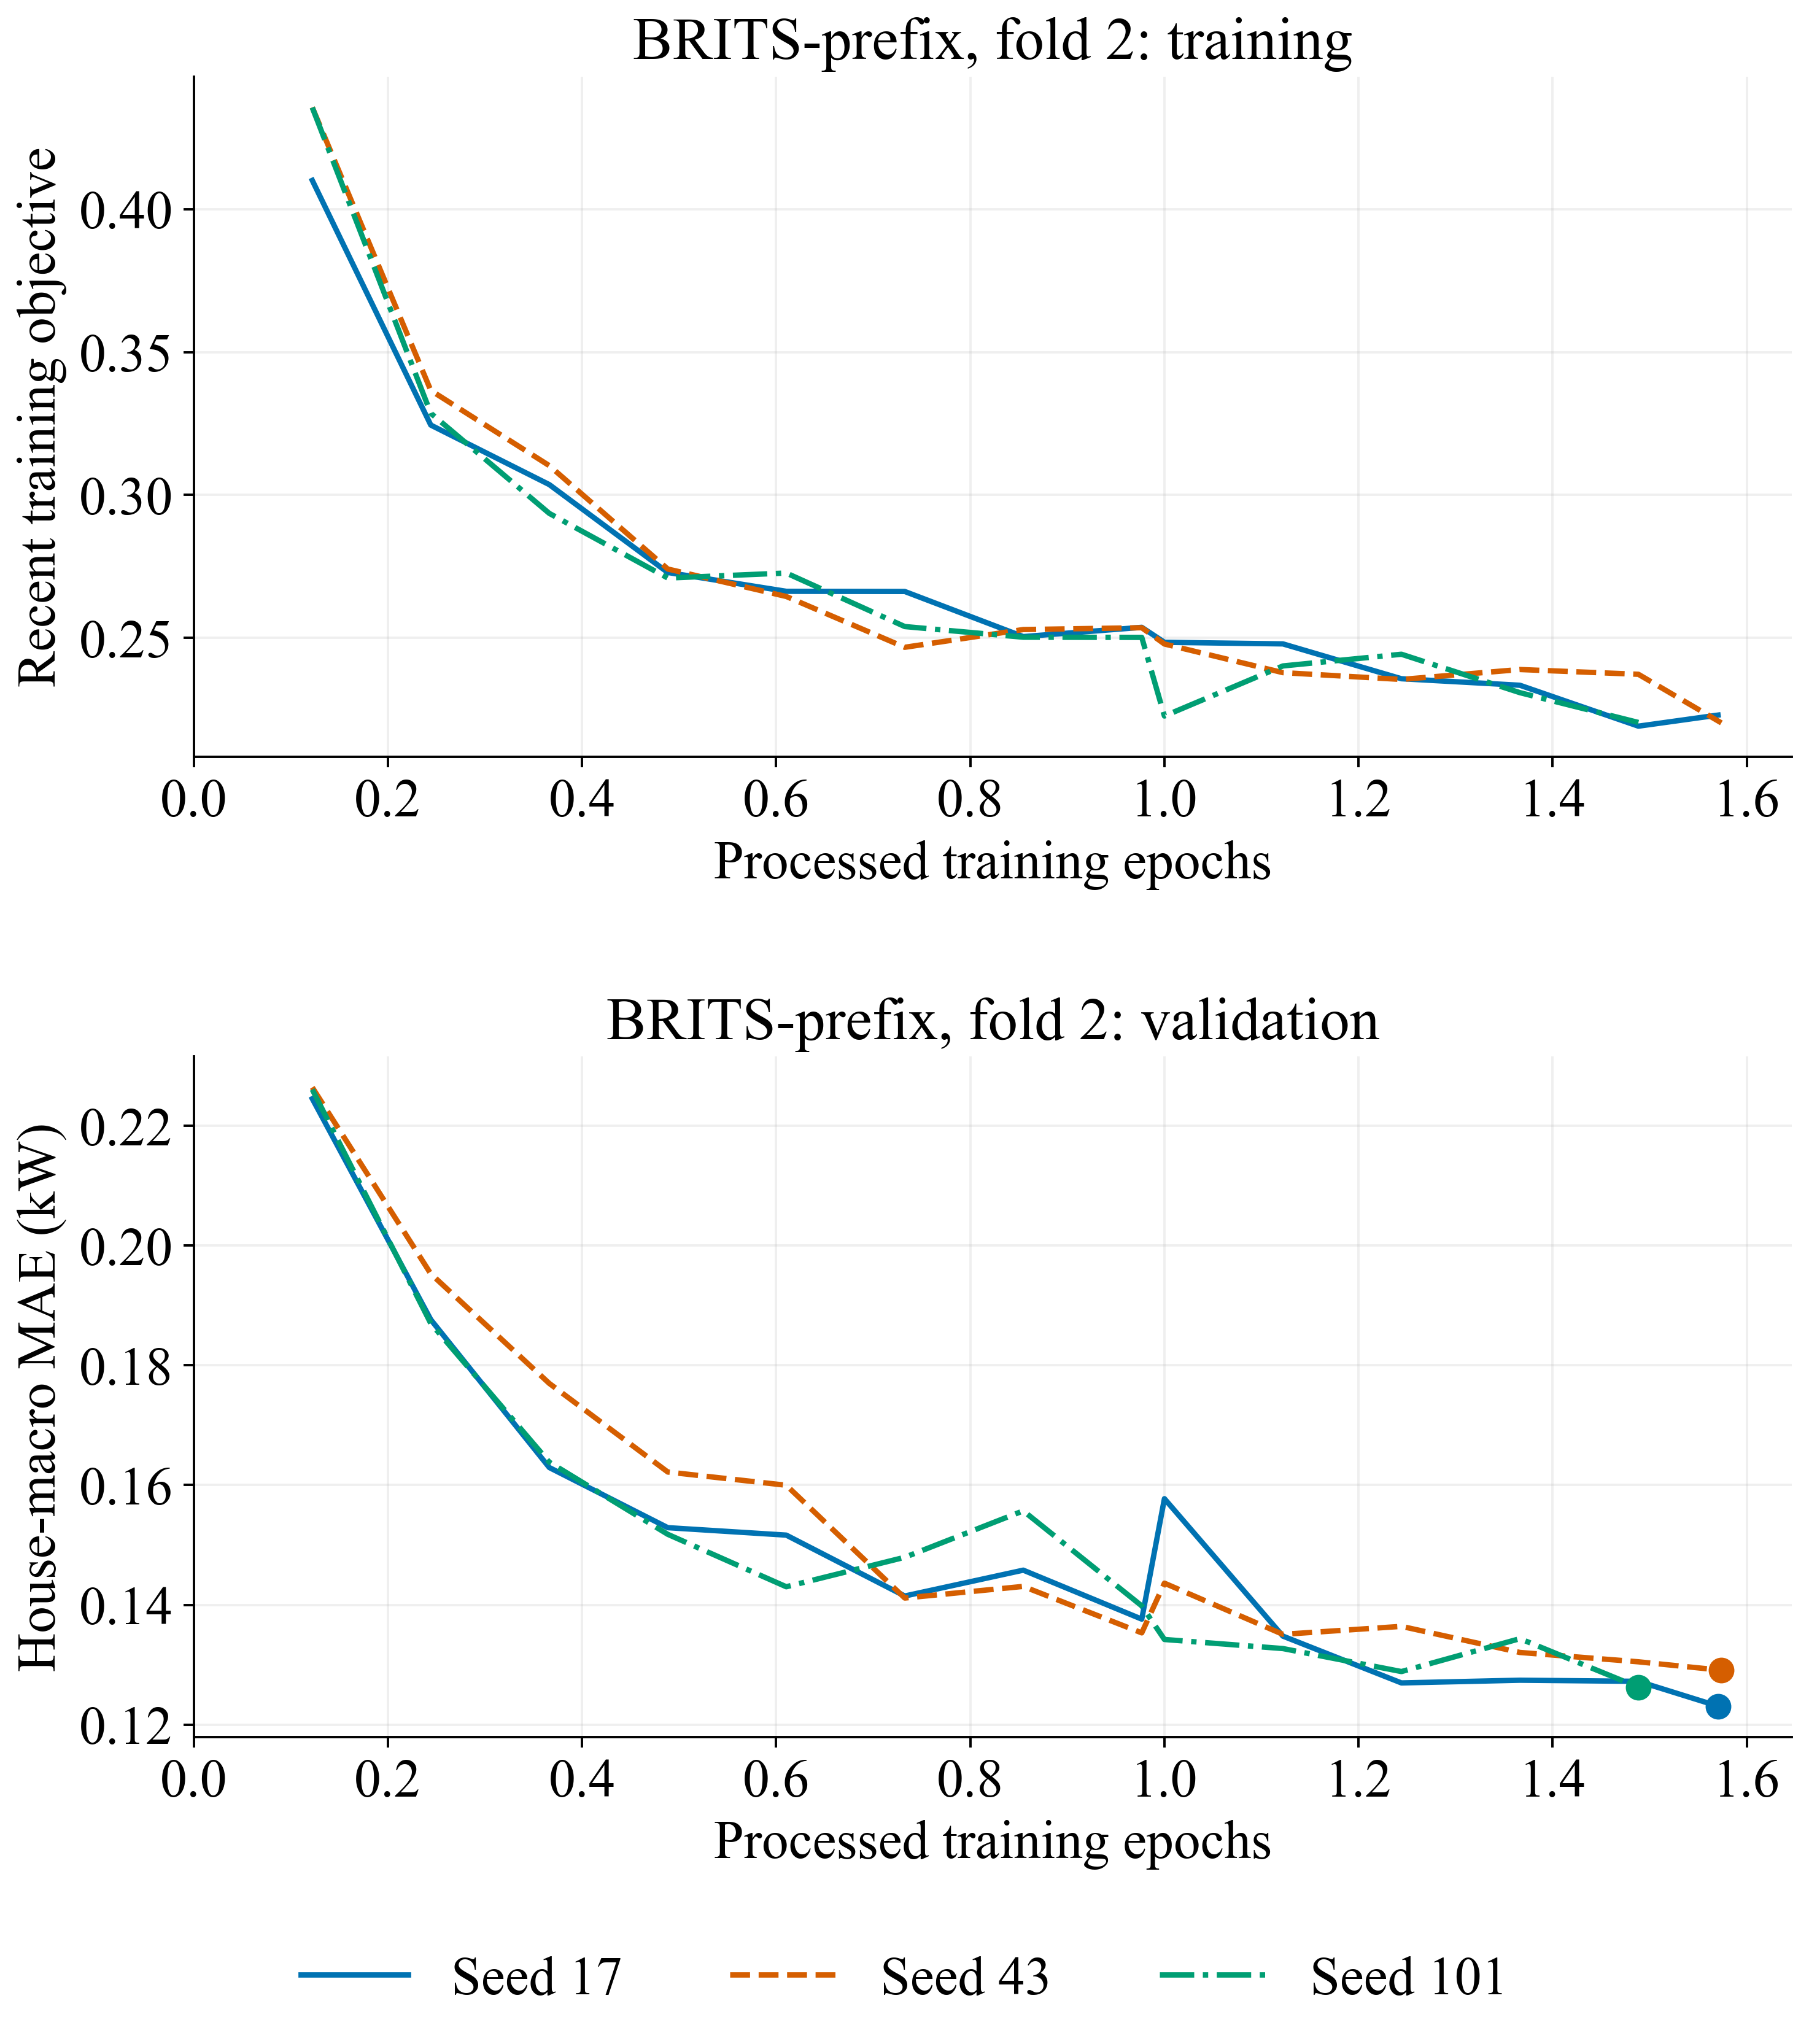

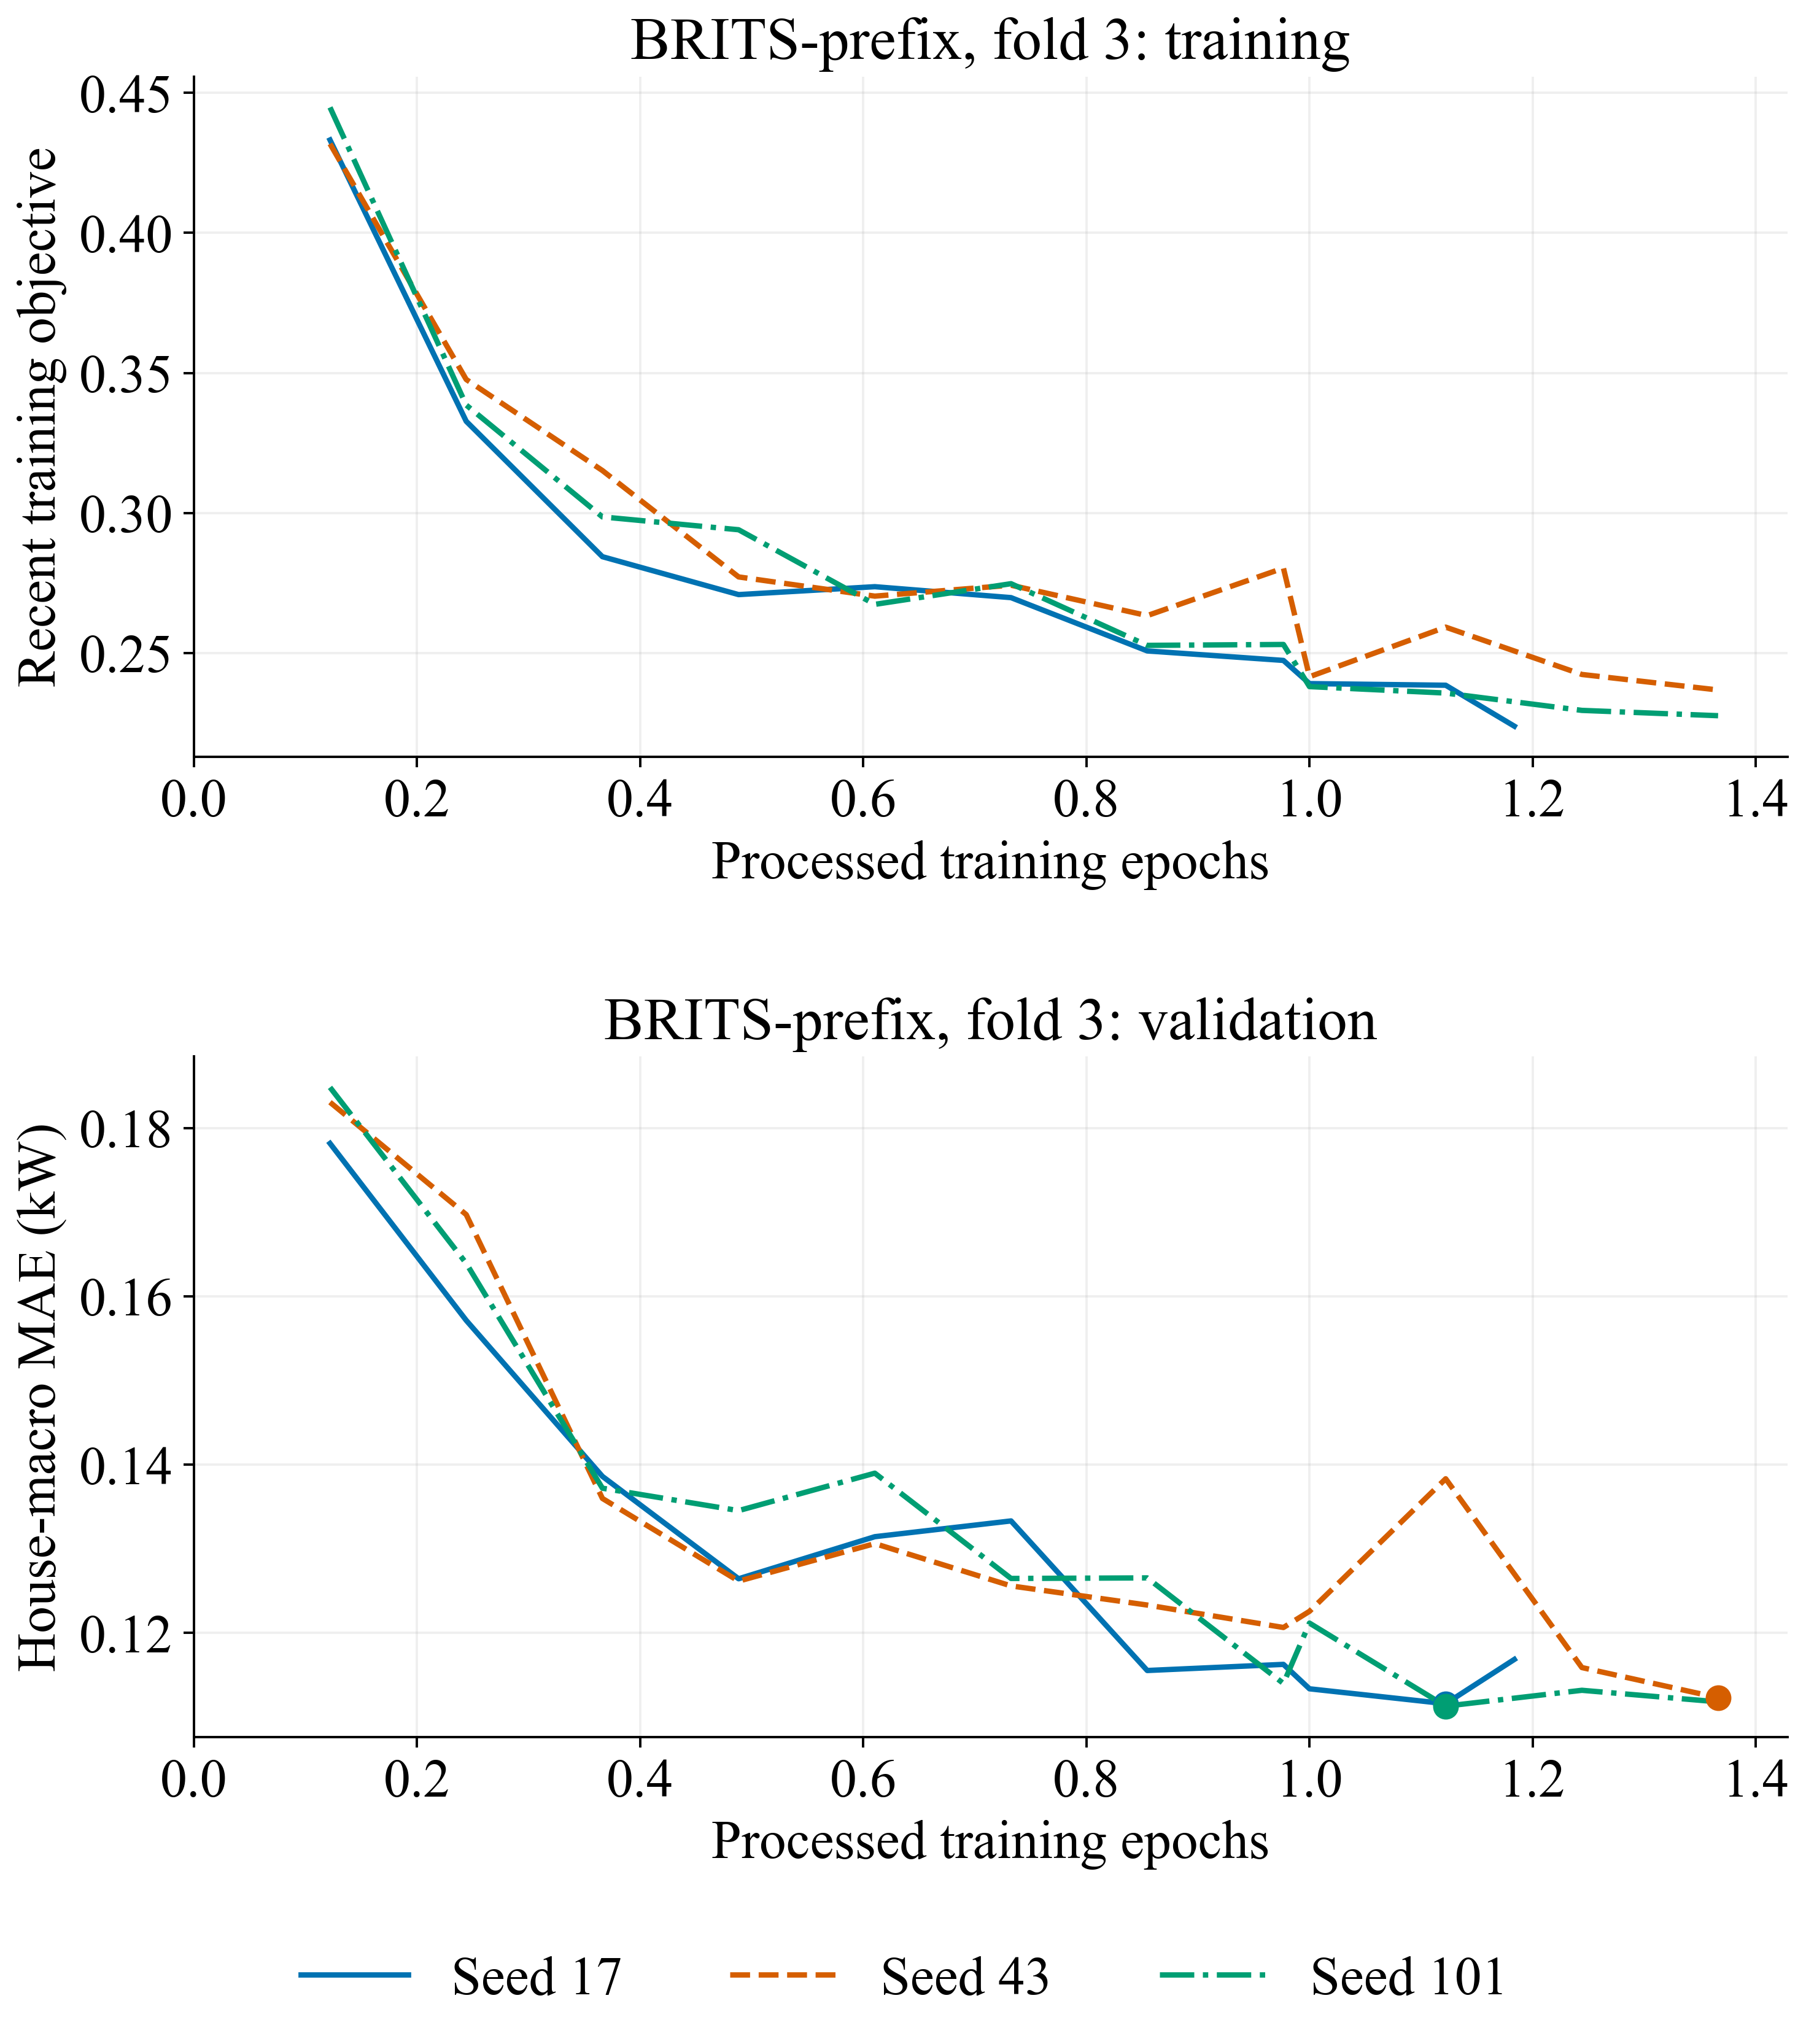

In [3]:
# Re-render archived scientific figures; this cell does not train models or recompute metrics.
def _presentation_nb04_db3c95c1():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_1_seed_17_history.csv': '770d534dbe0838783e89e343a3dd62484fc404b58757dc4aaac449f163498f2b', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_1_seed_17_complete.json': '3aaf786c5ef591cfcaa29f075733a2c712b9adc053f8725543e4723c4e4d9b94', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_1_seed_43_history.csv': 'af8cfac692d0fd38b2705dd3dcc5746c6aca34c070e17d5809db38394b3a809e', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_1_seed_43_complete.json': '0eb88077e0b93e6281e949e3cdd927193285d779928fbb0faaab156cb4a0c79b', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_1_seed_101_history.csv': '129f06685f2a83dbf1b42cf860aaab3e5b138ea704857bad993716798b73d63b', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_1_seed_101_complete.json': '6956e35f9ca200a75635b4caff22798affe5e22592b19f458b9b15b258c76f94', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_2_seed_17_history.csv': '2b9bcd79c758854dcaaedf01f3246661be7d88d2b297fd2c5608b4734112f50d', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_2_seed_17_complete.json': '36cd6a2f2860d02e4f8adac866958fbf4dcfe7b527f866f13de8b0ff263e9629', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_2_seed_43_history.csv': 'dffa56eac122676da8842c4ee5ad14c9fc644ad8caebcedfcb2b78697fdf839c', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_2_seed_43_complete.json': '64d034cc0b5622a986000587ac215e3c9355987dad46a42185c1c9c613b68886', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_2_seed_101_history.csv': '713532b192a43d0addc425e4ee5dc87be4e11af90121cd15a50c7577078a37e8', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_2_seed_101_complete.json': 'c21f8747a0334448420fc097b22a1a51b64da0ac75e6ae907cce7321c13cb43c', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_3_seed_17_history.csv': '573dae7d17c029ad88a2d52ea47218b8e2dd11ac6485910503c19a0536e1d125', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_3_seed_17_complete.json': 'e973e43b98d85d2de4b2d0d3e75064dc49cebef2493360bbdd11ddeb5e1454ea', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_3_seed_43_history.csv': 'b3a5729f77276cbd38b6bd1cb6cd4442df64c2ffda83e67b1626f782f8fc7342', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_3_seed_43_complete.json': '71b4e5231a5636f794b04e1fa610448a21254e39fdb22965f3b12d7660583f74', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_3_seed_101_history.csv': '1a33eedfd44d19040cce4c930160f61a2fec89ebaa8b0f665b1224709debf04b', 'Models/modern/guldana_n3_20261007_v01/BRITS-prefix_fold_3_seed_101_complete.json': '62d80b50a4ea3f1340928d5194adb4232ac19d1ae189a97ae1e231c6ef9eaaa2'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB04"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB04"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    family = 'BRITS-prefix'
    colors={17:"#0072B2",43:"#D55E00",101:"#009E73"}
    for fold in [1,2,3]:
        fig,axes=plt.subplots(2,1,figsize=(8.8,9.8))
        for seed, style in zip([17,43,101],["-","--","-."]):
            stem=f"{family}_fold_{fold}_seed_{seed}"
            history=pd.read_csv(ROOT / f"Models/modern/guldana_n3_20261007_v01/{stem}_history.csv")
            record=json.loads((ROOT / f"Models/modern/guldana_n3_20261007_v01/{stem}_complete.json").read_text())
            assert np.isfinite(history[["recent_mean_training_objective","inner_house_macro_MAE_kW"]]).all().all()
            x=history.examples_processed/record["training_queries_available"]
            axes[0].plot(x,history.recent_mean_training_objective,color=colors[seed],ls=style,label=f"Seed {seed}",lw=1.8)
            axes[1].plot(x,history.inner_house_macro_MAE_kW,color=colors[seed],ls=style,label=f"Seed {seed}",lw=1.8)
            chosen=np.flatnonzero(np.isclose(history.inner_house_macro_MAE_kW,record["best_inner_house_macro_MAE_kW"],rtol=0,atol=1e-12))
            assert len(chosen)>0
            k=chosen[0]
            axes[1].scatter([x.iloc[k]],[history.inner_house_macro_MAE_kW.iloc[k]],color=colors[seed],s=58,marker="o",zorder=4)
        axes[0].set(title=f"{family}, fold {fold}: training",ylabel="Recent training objective")
        axes[1].set(title=f"{family}, fold {fold}: validation",ylabel="House-macro MAE (kW)")
        for ax in axes:
            ax.set_xlabel("Processed training epochs");ax.set_xlim(left=0);_quiet_axes(ax)
        handles,names=axes[0].get_legend_handles_labels()
        fig.legend(handles,names,loc="lower center",bbox_to_anchor=(.5,.005),ncol=3,frameon=False)
        fig.tight_layout(rect=(0,.065,1,1),h_pad=2)
        _export(fig,f"27_brits_prefix_learning_fold_{fold}")

_presentation_nb04_db3c95c1()


### BRITS learning interpretation and matched diagnostics

Training objectives decline substantially, while inner-validation trajectories remain non-monotone. Every retained run stops at the wall-clock budget, with less than two processed training epochs, so these results describe the fixed computational protocol and do not establish convergence. The selected checkpoint follows the prespecified inner-validation improvement threshold during each run.

The next comparison recomputes complete seed, household and missingness-regime metrics on identical query IDs and masks. The observable age selector remains an exploratory control motivated by earlier development diagnostics.

In [69]:
# Compare complete BRITS predictions on identical scenarios.
brits_seed_metrics,brits_model_summary,brits_house_summary=modern_family_diagnostics("BRITS-prefix")

Model,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
BRITS-prefix,17,0.1259,0.3780,−0.0630,0.3239
ExtraTrees,17,0.1165,0.3357,−0.0074,0.0000
Observable age selector,17,0.1095,0.3401,−0.0066,0.0000
Last valid aggregate,17,0.1530,0.5549,−0.0017,0.0000
BRITS-prefix,43,0.1273,0.3819,−0.0716,0.1807
ExtraTrees,43,0.1160,0.3360,−0.0066,0.0000
Observable age selector,43,0.1100,0.3411,−0.0073,0.0000
Last valid aggregate,43,0.1525,0.5533,−0.0017,0.0000
BRITS-prefix,101,0.1267,0.3802,−0.0586,0.1636
ExtraTrees,101,0.1150,0.3355,−0.0062,0.0000


Model,Mean MAE (kW),Minimum seed MAE (kW),Maximum seed MAE (kW),Mean macro RMSE (kW),Mean bias (kW)
BRITS-prefix,0.1266,0.1259,0.1273,0.3800,−0.0644
ExtraTrees,0.1158,0.1150,0.1165,0.3357,−0.0067
Observable age selector,0.1093,0.1083,0.1100,0.3405,−0.0070
Last valid aggregate,0.1518,0.1499,0.1530,0.5517,−0.0011


house,BRITS-prefix,ExtraTrees,Observable age selector,Last valid aggregate
1,0.0782,0.0771,0.0715,0.1171
2,0.1708,0.1544,0.1432,0.2021
3,0.0994,0.0875,0.0833,0.1399
4,0.1058,0.1024,0.0965,0.1433
5,0.2639,0.2621,0.2528,0.3496
6,0.1221,0.1058,0.0998,0.1552
7,0.0734,0.0765,0.0726,0.0847
8,0.1164,0.1015,0.0980,0.1129
9,0.0694,0.0650,0.0622,0.0791
10,0.1668,0.1262,0.1130,0.1343


Missingness mode,BRITS-prefix,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
block,0.1643,0.1651,0.2580,0.1651,10,92696
mixed,0.1832,0.1807,0.2584,0.1807,10,92346
point,0.0798,0.0594,0.0451,0.0455,10,91617
sensor_dropout,0.0785,0.0576,0.0447,0.0451,10,91981


Gap minutes,BRITS-prefix,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
1,0.0792,0.0585,0.0449,0.0453,10,183598
5,0.1380,0.1141,0.1113,0.1141,10,61463
30,0.1908,0.1909,0.2800,0.1909,10,61836
120,0.1921,0.2132,0.3822,0.2132,10,61743


Auxiliary retention,BRITS-prefix,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
0.0000,0.1367,0.1257,0.1507,0.1179,10,73282
0.2500,0.1301,0.1200,0.1503,0.1132,10,74179
0.5000,0.1269,0.1167,0.1526,0.1100,10,73611
0.7500,0.1217,0.1105,0.1517,0.1043,10,74116
1.0000,0.1178,0.1065,0.1539,0.1011,10,73452


Observed auxiliary sensors,BRITS-prefix,ExtraTrees,Last valid aggregate,Observable age selector,Houses,Seed-query cases
0,0.1378,0.1267,0.1513,0.1190,10,109765
1,0.1322,0.1215,0.1503,0.1147,10,61278
2,0.1227,0.1129,0.1488,0.1064,10,64291
3,0.1211,0.1104,0.1533,0.1044,10,67566
4,0.1262,0.1164,0.1688,0.1094,7,41612
5,0.1823,0.1286,0.3167,0.1289,7,22660
6,0.2240,0.1314,0.1867,0.1108,1,1468


### BRITS interpretation and the next comparator

BRITS improves mean MAE over last-valid persistence, but its overall MAE and RMSE are worse than ExtraTrees and the exploratory observable-age selector. It has a stronger negative bias. Its advantage over ExtraTrees is concentrated in the longest tested gap; shorter gaps are unfavorable, and the intermediate long-gap comparison is nearly tied. House-specific errors reveal substantial heterogeneity, including worse performance than persistence in houses 8 and 10. The highest observed-sensor count is supported by only one house and must not be interpreted as a causal effect of more sensors. All these statements concern development OOF scenarios under the fixed, time-censored local protocol.

SAITS is now selected using the same prespecified inner cohort, four configurations and wall-clock budget. Its diagonally masked attention uses only the query-bounded prefix; it receives no future context.

In [70]:
# Select SAITS using only fold-1 inner validation.
saits_fold_1_selection=search_point_family(1,"SAITS-prefix")

Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
SAITS-prefix,1,1,60,0.0010,0.1046,184.8168,16380,wall_clock_budget
SAITS-prefix,1,2,120,0.0010,0.1075,185.4976,16380,wall_clock_budget
SAITS-prefix,1,3,60,0.0003,0.1078,184.3499,16380,wall_clock_budget
SAITS-prefix,1,4,120,0.0003,0.1160,185.4246,16380,wall_clock_budget


### SAITS fold-one selection and retained seeds

Inner validation selects the shorter history with the larger tested learning rate. All search candidates see the complete prescribed search cohort and stop at the wall-clock ceiling; their final validation checks account for the small budget overrun. No outer targets enter this choice. The selected configuration is now fitted independently on the larger training cohort for each prespecified seed, followed by full OOF prediction.

In [71]:
# Fit the selected SAITS configuration for all three fold-1 seeds.
saits_fold_1_resources=[final_point_fit(1,"SAITS-prefix",seed) for seed in [17,43,101]]

Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,1,17,0.1222,0.3982,−0.0667,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,1,17,214.5531,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,1,43,0.1341,0.4063,−0.0705,0.0366


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,1,43,175.4132,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,1,101,0.1174,0.3901,−0.0605,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,1,101,466.9329,65530,inner_patience


### SAITS first-fold interpretation and second-fold selection

Every retained seed sees the entire prescribed training cohort and stops by inner-validation patience. Seed-dependent errors and negative bias are visible, so no single seed is treated as the family result. These outcomes do not alter the declared search space or the later folds.

The next search uses only the second fold’s own inner-validation cohort.

In [72]:
# Select SAITS using only fold-2 inner validation.
saits_fold_2_selection=search_point_family(2,"SAITS-prefix")

Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
SAITS-prefix,2,1,60,0.0010,0.1267,183.4931,16380,wall_clock_budget
SAITS-prefix,2,2,120,0.0010,0.1224,186.0745,16380,wall_clock_budget
SAITS-prefix,2,3,60,0.0003,0.1285,184.7291,16380,wall_clock_budget
SAITS-prefix,2,4,120,0.0003,0.1366,180.2724,16380,wall_clock_budget


### SAITS second-fold selection

This fold selects the longer of the two tested histories with the larger learning rate. Every candidate sees the complete search cohort and stops at the fixed time ceiling. The difference from the first fold illustrates why configuration selection is performed within each chronological fold. The retained runs keep this choice fixed across all prespecified seeds and produce complete OOF predictions.

In [73]:
# Fit the selected SAITS configuration for all three fold-2 seeds.
saits_fold_2_resources=[final_point_fit(2,"SAITS-prefix",seed) for seed in [17,43,101]]

Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,2,17,0.1102,0.3360,−0.0614,0.0659


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,2,17,470.9731,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,2,43,0.1237,0.3682,−0.0464,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,2,43,437.9455,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,2,101,0.1133,0.3542,−0.0678,0.0024


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,2,101,390.7239,65530,inner_patience


## Interim development summary

The TCN, Transformer and BRITS results above are complete. SAITS and ImputeFormer are completed below, followed by the five-family comparison. CSDI remains incomplete and does not enter the completed-family ranking.

The engineering probes measure execution cost and consistency, not reconstruction accuracy. The completed evidence supports testing variable sensor sets, cross-channel state dependence and calibrated physical updates; it does not establish a proposed-method advantage. Protected evaluation data remain unused.

## Comparison of completed modern methods

The complete five-family comparison retains every prespecified fold and seed for TCN, Transformer, BRITS, SAITS and ImputeFormer. The following cells complete the third SAITS fold and all ImputeFormer folds under the unchanged protocol, then compute joint diagnostics for all five families.

CSDI remains **incomplete**: three first-fold search candidates completed, and candidate four stopped after 608 of 10,240 inner queries. There are no retained CSDI OOF runs, and inner-search scores cannot establish a comparative loss. The comparison is therefore not exhaustive.

All methods share query IDs, masks, current permitted measurements and causal time boundaries. Their native representations and selected history lengths differ; this comparison does not isolate architecture from input representation or establish convergence. The common60 classical analysis is reported in Notebook 03.

In [1]:
# Independent extension setup: immutable historical inputs, separate output namespace.
from pathlib import Path
import hashlib, json, os, gc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.text import Text
from IPython.display import display, Image, Markdown, clear_output
from PIL import Image as PILImage
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
V2_RUN="guldana_n3_20261009_v02"
V2_RECORD=ROOT/"Manifests/Runs"/V2_RUN
V2_TABLES=ROOT/"Tables"/V2_RUN/"04_complete_comparisons"
V2_DATA=ROOT/"Data/Processed"/V2_RUN/"sota_auxiliary"
for folder in [V2_TABLES,V2_DATA,ROOT/"Figures/PNG"/V2_RUN,ROOT/"Figures/PDF"/V2_RUN]:folder.mkdir(parents=True,exist_ok=True)
def v2_sha(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()
V2_PROTOCOL=json.loads((ROOT/"Configs/strengthening_v2.json").read_text())
V2_OLD_LOCK=json.loads((V2_RECORD/"historical_artifact_lock.json").read_text())
V2_SPLIT=json.loads((ROOT/"Manifests/split_freeze.json").read_text())
for relative,digest in V2_SPLIT["files"].items():assert v2_sha(ROOT/relative)==digest,relative
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6
font=font_manager.findfont("Times New Roman",fallback_to_default=False)
assert Path(font).is_file()
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,
    "axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,
    "figure.dpi":350,"savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
def v2_table(frame,name,caption,precision=4):
    frame.to_csv(V2_TABLES/f"{name}.csv",index=False)
    frame.to_latex(V2_TABLES/f"{name}.tex",index=False,caption=caption,float_format=lambda x:f"{x:.{precision}f}")
    display(frame.style.format(precision=precision,na_rep="Not identifiable").hide(axis="index").set_caption(caption))
def v2_figure(fig,name):
    fig.canvas.draw()
    for text in fig.findobj(Text):
        if text.get_visible() and text.get_text().strip():
            assert 18<=text.get_fontsize()<=20
            assert font_manager.FontProperties(fname=font_manager.findfont(text.get_fontproperties(),fallback_to_default=False)).get_name()=="Times New Roman"
    png=ROOT/"Figures/PNG"/V2_RUN/f"{name}.png";pdf=ROOT/"Figures/PDF"/V2_RUN/f"{name}.pdf"
    fig.savefig(png,dpi=350,bbox_inches="tight",pad_inches=.06)
    fig.savefig(pdf,dpi=350,bbox_inches="tight",pad_inches=.06)
    with PILImage.open(png) as im:assert all(abs(d-350)<.02 for d in im.info["dpi"])
    plt.close(fig);display(Image(filename=str(png)))

import time,math,copy,random,threading,psutil,torch,yaml
import torch.nn as nn
import torch.nn.functional as F
from types import SimpleNamespace
torch.set_num_threads(4)
OLD_RUN="guldana_n3_20261007_v01";RUN=V2_RUN
schema=json.loads((ROOT/"Configs/sensor_schema.json").read_text())
DEVICE=torch.device("mps" if torch.backends.mps.is_available() else "cpu")
DENSE_CAPACITY=16;N_TYPES=len(schema["power_types"])
PREP=ROOT/"Models/preprocessing"/OLD_RUN
preprocessors={fold:SimpleNamespace(state=json.loads((PREP/f"fold_{fold}_preprocessing.json").read_text())) for fold in [1,2,3]}
CACHE=ROOT/"Data/Processed"/OLD_RUN/"modeling_inputs"
NEURAL_CACHE=ROOT/"Data/Processed"/OLD_RUN/"neural_inputs_v1"
MODERN_DIR=ROOT/"Models/modern"/V2_RUN;PRED_DIR=ROOT/"Predictions/development_modern"/V2_RUN
for folder in [MODERN_DIR,PRED_DIR]:folder.mkdir(parents=True,exist_ok=True)
INPUT_CONTRACT="masked_sensor_v1_exact_fixtures"
compute_protocol=yaml.safe_load((ROOT/"Configs/compute_protocol.yaml").read_text())
point_protocol=json.loads((ROOT/"Configs/modern_point_search.json").read_text())
MODERN_SPACES=point_protocol["spaces"];MODERN_DEVICES=point_protocol["devices"]
MODERN_PROTOCOL_HASH=v2_sha(ROOT/"Configs/modern_point_search.json")
POINT_FAMILIES=["SAITS-prefix","ImputeFormer-semantic"]
TABLES=V2_TABLES;table=v2_table


In [2]:
def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.backends.mps.is_available():torch.mps.manual_seed(seed)

def synchronize(device=DEVICE):
    if str(device)=="mps":torch.mps.synchronize()

def padded_inputs(inputs,capacity=DENSE_CAPACITY):
    b,n,l,c=inputs["history"].shape
    assert n<=capacity,"Sensor capacity exceeded; never silently discard a sensor."
    result={}
    for key,value in inputs.items():
        if key=="context":result[key]=value
        elif key=="history":result[key]=F.pad(value,(0,0,0,0,0,capacity-n))
        else:result[key]=F.pad(value,(0,capacity-n))
    return result

def sequence_observations(inputs):
    history=inputs["history"]
    current_mask=inputs["current_mask"].to(history.dtype)
    current_age=torch.where(current_mask.bool(),0.,(history[:,:,-1,3]+1/361).clamp(max=1))
    # Current coverage is not supplied by the input contract: its channel is zero, not an invented reading count.
    current=torch.stack([inputs["current_values"],current_mask,torch.zeros_like(current_mask),current_age],-1)
    seq=torch.cat([history,current[:,:,None,:]],2).transpose(1,2)
    seq=seq*inputs["installed"][:,None,:,None]
    return seq

def masked_mean(values,mask):
    mask=mask.to(values.dtype)
    return (values*mask).sum()/mask.sum().clamp_min(1)

def position_encoding(length,width,device):
    position=torch.arange(length,device=device,dtype=torch.float32)[:,None]
    frequencies=torch.exp(torch.arange(0,width,2,device=device,dtype=torch.float32)*(-math.log(10000.)/width))
    encoding=torch.zeros(length,width,device=device)
    encoding[:,0::2]=torch.sin(position*frequencies)
    encoding[:,1::2]=torch.cos(position*frequencies[:encoding[:,1::2].shape[1]])
    return encoding

class DenseObservationAdapter(nn.Module):
    def __init__(self,embedding=4):
        super().__init__()
        self.type_embedding=nn.Embedding(N_TYPES,embedding)
        self.output_size=DENSE_CAPACITY*(5+embedding)+14
        self.side_size=DENSE_CAPACITY*(3+embedding)+14
    def forward(self,inputs):
        inputs=padded_inputs(inputs);seq=sequence_observations(inputs)
        b,t,n,_=seq.shape
        installed=inputs["installed"].to(seq.dtype)
        semantics=self.type_embedding(inputs["type_ids"])*installed[:,:,None]
        static=torch.cat([installed[:,:,None],semantics],-1)[:,None].expand(-1,t,-1,-1)
        context=inputs["context"][:,None].expand(-1,t,-1)
        flat=torch.cat([torch.cat([seq,static],-1).flatten(2),context],-1)
        side=torch.cat([torch.cat([seq[:,:,:,2:],static],-1).flatten(2),context],-1)
        return seq[:,:,:,0],seq[:,:,:,1],flat,side,inputs["installed"]

class CausalConvBlock(nn.Module):
    def __init__(self,width,dilation,dropout):
        super().__init__();self.padding=2*dilation
        self.conv1=nn.Conv1d(width,width,3,dilation=dilation)
        self.conv2=nn.Conv1d(width,width,3,dilation=dilation)
        self.norm1=nn.LayerNorm(width);self.norm2=nn.LayerNorm(width)
        self.drop=nn.Dropout(dropout)
    def forward(self,x):
        y=self.conv1(F.pad(x,(self.padding,0))).transpose(1,2)
        y=self.drop(F.gelu(self.norm1(y))).transpose(1,2)
        y=self.conv2(F.pad(y,(self.padding,0))).transpose(1,2)
        return x+self.drop(F.gelu(self.norm2(y))).transpose(1,2)

class CausalTCN(nn.Module):
    def __init__(self,history=120,width=64,layers=6,dropout=.1,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter()
        self.input=nn.Linear(self.adapter.output_size,width)
        self.blocks=nn.ModuleList([CausalConvBlock(width,2**i,dropout) for i in range(layers)])
        self.output=nn.Linear(width,DENSE_CAPACITY)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs)
        hidden=self.input(flat).transpose(1,2)
        for block in self.blocks:hidden=block(hidden)
        pred=self.output(hidden.transpose(1,2))
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":pred.sum()*0}

class CausalTransformer(nn.Module):
    def __init__(self,history=120,width=64,layers=2,heads=4,dropout=.1,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter()
        self.input=nn.Linear(self.adapter.output_size,width)
        self.layers=nn.ModuleList([nn.TransformerEncoderLayer(width,heads,2*width,dropout,
            activation="gelu",batch_first=True,norm_first=True) for _ in range(layers)])
        self.output=nn.Linear(width,DENSE_CAPACITY)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs);t=flat.shape[1]
        hidden=self.input(flat)+position_encoding(t,self.input.out_features,flat.device)[None]
        causal=torch.ones(t,t,dtype=torch.bool,device=flat.device).triu(1)
        for layer in self.layers:hidden=layer(hidden,src_mask=causal)
        pred=self.output(hidden)
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":pred.sum()*0}

class DiagonalMaskedAttentionBlock(nn.Module):
    def __init__(self,width,heads,dropout):
        super().__init__()
        self.q=nn.Linear(width,width,bias=False);self.k=nn.Linear(width,width,bias=False);self.v=nn.Linear(width,width,bias=False)
        self.out=nn.Linear(width,width,bias=False);self.heads=heads;self.width=width
        self.norm1=nn.LayerNorm(width,eps=1e-6);self.norm2=nn.LayerNorm(width,eps=1e-6)
        self.ff=nn.Sequential(nn.Linear(width,2*width),nn.ReLU(),nn.Dropout(dropout),nn.Linear(2*width,width))
        self.drop=nn.Dropout(dropout)
    def forward(self,x):
        z=self.norm1(x);b,t,d=z.shape;h=self.heads
        q,k,v=[layer(z).view(b,t,h,d//h).transpose(1,2) for layer in [self.q,self.k,self.v]]
        logits=q@k.transpose(-2,-1)/math.sqrt(d//h)
        logits=logits.masked_fill(torch.eye(t,device=z.device,dtype=torch.bool)[None,None],float("-inf"))
        attention=logits.softmax(-1)
        hidden=(attention@v).transpose(1,2).reshape(b,t,d)
        x=x+self.drop(self.out(hidden));x=x+self.drop(self.ff(self.norm2(x)))
        return x,attention.mean(1)

class SAITSPrefix(nn.Module):
    # Architecture follows the two DMSA groups of the pinned SAITS implementation.
    def __init__(self,history=120,width=64,layers=2,heads=4,dropout=.1,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter();self.history=history
        d=DENSE_CAPACITY;inp=2*d+self.adapter.side_size
        self.embed1=nn.Linear(inp,width);self.embed2=nn.Linear(inp,width)
        self.first=nn.ModuleList([DiagonalMaskedAttentionBlock(width,heads,dropout) for _ in range(layers)])
        self.second=nn.ModuleList([DiagonalMaskedAttentionBlock(width,heads,dropout) for _ in range(layers)])
        self.out1=nn.Linear(width,d);self.out2=nn.Sequential(nn.Linear(width,d),nn.ReLU(),nn.Linear(d,d))
        self.combine=nn.Linear(d+history+1,d);self.drop=nn.Dropout(dropout)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs);position=position_encoding(x.shape[1],self.embed1.out_features,x.device)[None]
        hidden=self.drop(self.embed1(torch.cat([x,m,side],-1))+position)
        for layer in self.first:hidden,_=layer(hidden)
        x1=self.out1(hidden);filled=m*x+(1-m)*x1
        hidden=self.embed2(torch.cat([filled,m,side],-1))+position
        for layer in self.second:hidden,attention=layer(hidden)
        x2=self.out2(hidden);eta=torch.sigmoid(self.combine(torch.cat([m,attention],-1)))
        x3=(1-eta)*x2+eta*x1
        observed_loss=sum(masked_mean((p-x).abs(),m) for p in [x1,x2,x3])/3
        return {"sequence":x3,"prediction":x3[:,-1,0],"observed_loss":observed_loss}
class ProjectedTemporalLayer(nn.Module):
    def __init__(self,width,projectors,heads,dropout):
        super().__init__()
        self.projectors=nn.Parameter(torch.empty(projectors,width));nn.init.xavier_uniform_(self.projectors)
        self.out_attention=nn.MultiheadAttention(width,heads,dropout=0,batch_first=True)
        self.in_attention=nn.MultiheadAttention(width,heads,dropout=0,batch_first=True)
        self.norm1=nn.LayerNorm(width);self.norm2=nn.LayerNorm(width);self.drop=nn.Dropout(dropout)
        self.ff=nn.Sequential(nn.Linear(width,2*width),nn.GELU(),nn.Linear(2*width,width))
    def forward(self,x):
        b,t,n,d=x.shape;z=x.transpose(1,2).reshape(b*n,t,d)
        p=self.projectors[None].expand(b*n,-1,-1)
        message,_=self.out_attention(p,z,z,need_weights=False)
        update,_=self.in_attention(z,p,message,need_weights=False)
        z=self.norm1(z+self.drop(update));z=self.norm2(z+self.drop(self.ff(z)))
        return z.reshape(b,n,t,d).transpose(1,2)

class EmbeddedSpatialLayer(nn.Module):
    def __init__(self,width,embedding,dropout):
        super().__init__()
        self.query=nn.Linear(embedding,embedding);self.value=nn.Linear(width,width)
        self.norm1=nn.LayerNorm(width);self.norm2=nn.LayerNorm(width);self.drop=nn.Dropout(dropout)
        self.ff=nn.Sequential(nn.Linear(width,2*width),nn.ReLU(),nn.Linear(2*width,width))
    def forward(self,x,embedding,installed):
        q=self.query(embedding)
        query=q.softmax(-1)
        key=q.transpose(-2,-1).masked_fill(~installed[:,None,None,:],float("-inf")).softmax(-1)
        update=query@(key@self.value(x))
        z=self.norm1(x+self.drop(update));z=self.norm2(z+self.drop(self.ff(z)))
        return z*installed[:,None,:,None]

class ImputeFormerSemantic(nn.Module):
    def __init__(self,history=120,width=64,layers=2,heads=4,dropout=.1,projectors=10,**kwargs):
        super().__init__();e=width//2
        self.type_embedding=nn.Embedding(N_TYPES,e);self.role_embedding=nn.Embedding(2,e)
        self.time_embedding=nn.Parameter(torch.empty(history+1,e));nn.init.xavier_uniform_(self.time_embedding)
        self.input=nn.Linear(4+14,width-e)
        self.temporal=nn.ModuleList([ProjectedTemporalLayer(width,projectors,heads,dropout) for _ in range(layers)])
        self.spatial=nn.ModuleList([EmbeddedSpatialLayer(width,e,dropout) for _ in range(layers)])
        self.readout=nn.Sequential(nn.Linear(width,width),nn.ReLU(),nn.Linear(width,1))
    def forward(self,inputs):
        seq=sequence_observations(inputs);b,t,n,_=seq.shape
        embedding=(self.type_embedding(inputs["type_ids"])+self.role_embedding(inputs["role_ids"]))[:,None]
        embedding=embedding+self.time_embedding[None,:,None,:]
        context=inputs["context"][:,None,None].expand(-1,t,n,-1)
        hidden=torch.cat([self.input(torch.cat([seq,context],-1)),embedding],-1)
        for temporal,spatial in zip(self.temporal,self.spatial):
            hidden=temporal(hidden);hidden=spatial(hidden,embedding,inputs["installed"])
        pred=self.readout(hidden).squeeze(-1)
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":pred.sum()*0}

def fourier_imputation_penalty(prediction,inputs):
    observed=sequence_observations(inputs);n=observed.shape[2];prediction=prediction[:,:,:n]
    completed=torch.where(observed[:,:,:,1].bool(),observed[:,:,:,0],prediction)
    # Paper Eq. 14: FFT over time and sensors independently for each observation.
    # The pinned trainer uses fftn without dimensions, also transforming the batch; we explicitly follow the paper.
    # CPU FFT remains differentiable through the device copies on macOS; no detached NumPy computation.
    counts=inputs["installed"].sum(-1).detach().cpu().numpy()
    penalties=[]
    for count in sorted(set(counts.tolist())):
        rows=torch.as_tensor(np.flatnonzero(counts==count),device=completed.device)
        physical=completed.index_select(0,rows)[:,:,:int(count)].to("cpu")
        spectrum=torch.fft.fftn(physical,dim=(1,2))
        penalties.append(spectrum.abs().mean((1,2)).sum().to(completed.device))
    return torch.stack(penalties).sum()/len(completed)

def endpoint_training_loss(model_name,result,inputs,labels):
    n=inputs["installed"].shape[1];pred=result["sequence"][:,-1,:n]
    target=labels["values"].to(pred.dtype);known=labels["observed"]
    primary=(pred[:,0]-target[:,0]).abs().mean()
    hidden_aux=known & ~inputs["current_mask"] & inputs["role_ids"].eq(1)
    auxiliary=masked_mean((pred-target).abs(),hidden_aux)
    loss=primary+.25*auxiliary
    if model_name in {"BRITS-prefix","SAITS-prefix"}:loss=loss+result["observed_loss"]
    if model_name=="BRITS-prefix":loss=loss+.1*result["consistency_loss"]
    if model_name=="ImputeFormer-semantic":loss=loss+.01*fourier_imputation_penalty(result["sequence"],inputs)
    return loss

MODEL_CLASSES={"SAITS-prefix":SAITSPrefix,"ImputeFormer-semantic":ImputeFormerSemantic}


In [3]:
def file_sha256(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()

class NeuralInputCache:
    def __init__(self,fold,seed):
        self.fold=fold;self.seed=seed;self.folder=NEURAL_CACHE/f"fold_{fold}_seed_{seed}"
        self.record=json.loads((self.folder/"manifest.json").read_text())
        self.metadata=pd.read_parquet(CACHE/f"fold_{fold}_seed_{seed}.parquet")
        assert self.record["metadata_sha256"]==file_sha256(CACHE/f"fold_{fold}_seed_{seed}.parquet")
        self.arrays={item["name"][:-4]:np.load(self.folder/item["name"],mmap_mode="r",allow_pickle=False)
                     for item in self.record["arrays"]}
    def batch(self,rows,history,device,supervision=False):
        inputs={}
        for key,array in self.arrays.items():
            if key.startswith("label_"):continue
            values=array[rows]
            if key=="history":values=values[:,:,-history:,:]
            inputs[key]=torch.as_tensor(np.array(values,copy=True),device=device)
        labels=None
        if supervision:
            labels={"values":torch.as_tensor(np.array(self.arrays["label_values"][rows],dtype=np.float32),device=device),
                "observed":torch.as_tensor(np.array(self.arrays["label_observed"][rows],copy=True),device=device)}
        return inputs,labels

_VERIFIED_CACHES=set()
def build_neural_cache(fold,seed):
    """Read-only lineage check; this strengthening stage never rewrites historical caches."""
    key=(fold,seed)
    if key not in _VERIFIED_CACHES:
        folder=NEURAL_CACHE/f"fold_{fold}_seed_{seed}"
        manifest=json.loads((folder/"manifest.json").read_text())
        assert manifest["metadata_sha256"]==file_sha256(CACHE/f"fold_{fold}_seed_{seed}.parquet")
        for item in manifest["arrays"]:assert file_sha256(folder/item["name"])==item["sha256"],item["name"]
        _VERIFIED_CACHES.add(key)
    return json.loads((NEURAL_CACHE/f"fold_{fold}_seed_{seed}"/"manifest.json").read_text())

def regression_summary(metadata,prediction):
    error=np.asarray(prediction)-metadata.y_kW.to_numpy(dtype=float)
    by_house=pd.DataFrame({"house":metadata.house.to_numpy(),"absolute":abs(error),"squared":error**2,
        "bias":error,"negative":np.asarray(prediction)<0}).groupby("house").mean()
    return {"House-macro MAE (kW)":float(by_house.absolute.mean()),"House-macro RMSE (kW)":float(np.sqrt(by_house.squared).mean()),
        "Bias (kW)":float(by_house.bias.mean()),"Negative prediction (%)":float(100*by_house.negative.mean())}


In [4]:
class KernelMemorySampler:
    def __init__(self,device):
        self.device=device;self.stop_event=threading.Event();self.rows=[]
        self.process=psutil.Process();self.thread=threading.Thread(target=self._sample,daemon=True)
    def _sample(self):
        while not self.stop_event.is_set():
            row={"seconds":time.perf_counter()-self.started,"RSS_bytes":self.process.memory_info().rss}
            if str(self.device)=="mps":
                row.update(MPS_allocated_bytes=torch.mps.current_allocated_memory(),
                           MPS_driver_bytes=torch.mps.driver_allocated_memory())
            self.rows.append(row);self.stop_event.wait(.02)
    def start(self):
        self.started=time.perf_counter();self.baseline=self.process.memory_info().rss;self.thread.start()
    def stop(self):
        self.stop_event.set();self.thread.join()
        return pd.DataFrame(self.rows)

def search_point_family(fold,family):
    assert family in POINT_FAMILIES
    build_neural_cache(fold,17);cache=NeuralInputCache(fold,17);records=[];candidates=[]
    for trial,config in enumerate(MODERN_SPACES[family],1):
        stem=f"trial_{family}_fold_{fold}_{trial}"
        path=MODERN_DIR/f"{stem}_trial.json"
        if path.exists():
            record=json.loads(path.read_text())
            assert record["parameters"]==config and record["protocol_sha256"]==MODERN_PROTOCOL_HASH
            assert file_sha256(MODERN_DIR/f"{stem}.pt")==record["checkpoint_sha256"]
            resources=json.loads((MODERN_DIR/f"{stem}_resources.json").read_text())
        else:
            model,history,resources=fit_point_model(family,config,cache,17,180,True,stem)
            record={"trial":trial,"parameters":config,"inner_house_macro_MAE_kW":resources["best_inner_house_macro_MAE_kW"],
                "protocol_sha256":MODERN_PROTOCOL_HASH,"checkpoint_sha256":file_sha256(MODERN_DIR/f"{stem}.pt")}
            path.write_text(json.dumps(record,indent=2)+"\n")
            del model;gc.collect()
            if torch.backends.mps.is_available():torch.mps.empty_cache()
        score=record["inner_house_macro_MAE_kW"];candidates.append((score,trial,config))
        records.append({"Model":family,"Fold":fold,"Trial":trial,"History minutes":config["history"],
            "Learning rate":config["learning_rate"],"Inner MAE (kW)":score,"Fit seconds":resources["fit_seconds"],
            "Seen train queries":resources["unique_training_queries_seen"],"Stop reason":resources["stop_reason"]})
    table(pd.DataFrame(records),f"modern_search_{family}_fold_{fold}",
        f"Table 12.{family}.{fold}. All prespecified point-model trials, selected only on the full inner-validation cohort.")
    score,trial,config=min(candidates,key=lambda row:(row[0],row[1]))
    selection={"family":family,"fold":fold,"trial":trial,"parameters":config,"inner_house_macro_MAE_kW":score,
        "protocol_sha256":MODERN_PROTOCOL_HASH,"outer_targets_used":False}
    (MODERN_DIR/f"selection_{family}_fold_{fold}.json").write_text(json.dumps(selection,indent=2)+"\n")
    return selection
@torch.no_grad()
def predict_point_model(model,cache,rows,config,device,purpose="Prediction"):
    model.eval();predictions=[]
    show_progress=len(rows)>10240
    started=time.perf_counter()
    progress=display(pd.DataFrame(columns=["Phase","Completed queries","Total queries","Elapsed seconds"]),display_id=True) if show_progress else None
    for offset in range(0,len(rows),32):
        inputs,_=cache.batch(rows[offset:offset+32],config["history"],device)
        prediction=model(inputs)["prediction"]
        assert torch.isfinite(prediction).all()
        predictions.append(prediction.detach().cpu().numpy().astype(np.float64))
        if show_progress and (offset==0 or (offset+32)%4096==0 or offset+32>=len(rows)):
            progress.update(pd.DataFrame([{"Phase":purpose,"Completed queries":min(offset+32,len(rows)),
                "Total queries":len(rows),"Elapsed seconds":time.perf_counter()-started}])
                .style.hide(axis="index").format({"Elapsed seconds":"{:.2f}"}))
    return np.concatenate(predictions)*preprocessors[cache.fold].state["target_scale"]

def final_point_fit(fold,family,seed):
    selection=json.loads((MODERN_DIR/f"selection_{family}_fold_{fold}.json").read_text())
    config=selection["parameters"];assert selection["protocol_sha256"]==MODERN_PROTOCOL_HASH
    build_neural_cache(fold,seed);cache=NeuralInputCache(fold,seed)
    stem=f"{family}_fold_{fold}_seed_{seed}";complete=MODERN_DIR/f"{stem}_complete.json"
    if complete.exists():
        resource_record=json.loads(complete.read_text())
        assert file_sha256(MODERN_DIR/f"{stem}.pt")==resource_record["checkpoint_sha256"]
        assert file_sha256(PRED_DIR/f"{stem}.parquet")==resource_record["prediction_sha256"]
        result=pd.read_parquet(PRED_DIR/f"{stem}.parquet")
    else:
        model,history,resource_record=fit_point_model(family,config,cache,seed,600,False,stem)
        outer_rows=np.flatnonzero(cache.metadata.role.eq("outer_validation").to_numpy());assert len(outer_rows)==40960
        started=time.perf_counter()
        prediction=predict_point_model(model,cache,outer_rows,config,torch.device(MODERN_DEVICES[family]),purpose="OOF inference")
        resource_record["OOF_prediction_seconds"]=time.perf_counter()-started
        replay_started=time.perf_counter()
        bundle=torch.load(MODERN_DIR/f"{stem}.pt",map_location="cpu",weights_only=True)
        restored=MODEL_CLASSES[family](**config).to(MODERN_DEVICES[family]);restored.load_state_dict(bundle["state_dict"]);restored.eval()
        # Complete same-process replay; fresh-kernel reproduction is required at the next notebook gate.
        repeated=predict_point_model(restored,cache,outer_rows,config,torch.device(MODERN_DEVICES[family]),purpose="Checkpoint replay")
        np.testing.assert_array_equal(prediction,repeated)
        resource_record["checkpoint_load_and_replay_seconds"]=time.perf_counter()-replay_started
        resource_record["execution_kernel_pid"]=os.getpid()
        resource_record["OOF_progress_reporting"]="one live row updated every 4096 queries; included in OOF timing"
        result=cache.metadata.iloc[outer_rows].reset_index(drop=True).copy();result["prediction_kW"]=prediction
        result.to_parquet(PRED_DIR/f"{stem}.parquet",index=False)
        resource_record.update(checkpoint_sha256=file_sha256(MODERN_DIR/f"{stem}.pt"),
            prediction_sha256=file_sha256(PRED_DIR/f"{stem}.parquet"),checkpoint_bytes=(MODERN_DIR/f"{stem}.pt").stat().st_size,
            same_process_replay_maximum_difference=0.,fresh_kernel_replay="pending")
        complete.write_text(json.dumps(resource_record,indent=2)+"\n")
        del model,restored
    quality_row={"Model":family,"Fold":fold,"Seed":seed,**regression_summary(result,result.prediction_kW.to_numpy())}
    table(pd.DataFrame([quality_row]),f"modern_OOF_{stem}",
        f"Table 13.{stem}. Actual OOF predictions after independent inner selection; no outer-label tuning.")
    table(pd.DataFrame([{"Model":family,"Fold":fold,"Seed":seed,"Fit seconds":resource_record["fit_seconds"],
        "Seen train queries":resource_record["unique_training_queries_seen"],"Stop reason":resource_record["stop_reason"]}]),
        f"modern_fit_{stem}",f"Table 13r.{stem}. Training exposure and stopping rule for the same saved model.")
    del cache;gc.collect()
    if torch.backends.mps.is_available():torch.mps.empty_cache()
    return resource_record
def update_training_phase(handle,phase,step,seen,started):
    handle.update(pd.DataFrame([{"Phase":phase,"Optimizer step":step,"Seen training queries":seen,
        "Elapsed seconds":time.perf_counter()-started}])
        .style.hide(axis="index").format({"Elapsed seconds":"{:.1f}"}))

def fit_point_model(family,config,cache,seed,seconds,search,stem):
    device=torch.device(MODERN_DEVICES[family]);seed_everything(seed)
    model=MODEL_CLASSES[family](**config).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config["learning_rate"],weight_decay=config["weight_decay"])
    frame=cache.metadata
    train_rows=np.flatnonzero((frame.role.eq("train") & (frame.search_train if search else True)).to_numpy())
    inner_rows=np.flatnonzero(frame.role.eq("inner_validation").to_numpy())
    assert len(train_rows)==(16380 if search else 65530) and len(inner_rows)==10240
    inner_meta=frame.iloc[inner_rows].reset_index(drop=True)
    history=[];best=float("inf");best_state=None;stale=0;step=0;examples=0;seen=set();recent_loss=[]
    rng=np.random.default_rng(seed)
    memory=KernelMemorySampler(device);memory.start();synchronize(device);started=time.perf_counter()
    last_check=0;reason="epoch_limit";progress=display(pd.DataFrame(columns=["Optimizer step","Seen queries","Inner MAE (kW)"]),display_id=True)
    heartbeat=display(pd.DataFrame(columns=["Phase","Optimizer step","Seen training queries","Elapsed seconds"]),display_id=True)
    last_progress_seconds=0.
    update_training_phase(heartbeat,"Training",0,0,started)
    try:
        stop=False
        for epoch in range(1,101):
            order=rng.permutation(train_rows)
            for offset in range(0,len(order),config["batch_size"]):
                rows=order[offset:offset+config["batch_size"]];model.train()
                inputs,labels=cache.batch(rows,config["history"],device,supervision=True)
                optimizer.zero_grad(set_to_none=True)
                result=model(inputs);loss=endpoint_training_loss(family,result,inputs,labels)
                assert torch.isfinite(loss),f"{family}: nonfinite objective"
                loss.backward()
                norm=torch.nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
                optimizer.step();synchronize(device)
                step+=1;examples+=len(rows);seen.update(rows.tolist());recent_loss.append(float(loss.detach().cpu()))
                elapsed=time.perf_counter()-started
                if elapsed-last_progress_seconds>=10:
                    update_training_phase(heartbeat,"Training",step,len(seen),started)
                    last_progress_seconds=elapsed
                at_epoch_end=offset+config["batch_size"]>=len(order)
                if step-last_check>=250 or at_epoch_end or elapsed>=seconds:
                    update_training_phase(heartbeat,"Inner validation",step,len(seen),started)
                    prediction=predict_point_model(model,cache,inner_rows,config,device)
                    score=regression_summary(inner_meta,prediction)["House-macro MAE (kW)"]
                    elapsed=time.perf_counter()-started
                    row={"epoch":epoch,"step":step,"seen_queries":len(seen),"examples_processed":examples,
                        "elapsed_seconds":elapsed,"recent_mean_training_objective":float(np.mean(recent_loss)),
                        "inner_house_macro_MAE_kW":score,"gradient_norm":float(norm.detach().cpu())}
                    history.append(row);recent_loss=[];last_check=step
                    if score<best-1e-5:
                        best=score;best_state={key:value.detach().cpu().clone() for key,value in model.state_dict().items()};stale=0
                    else:stale+=1
                    pd.DataFrame(history).to_csv(MODERN_DIR/f"{stem}_history.csv",index=False)
                    progress.update(pd.DataFrame(history)[["step","seen_queries","elapsed_seconds","inner_house_macro_MAE_kW"]]
                        .rename(columns={"step":"Optimizer step","seen_queries":"Seen queries","elapsed_seconds":"Elapsed seconds",
                                         "inner_house_macro_MAE_kW":"Inner MAE (kW)"}).style.hide(axis="index").format(precision=4).set_caption(stem))
                    update_training_phase(heartbeat,"Training",step,len(seen),started)
                    last_progress_seconds=elapsed
                    if elapsed>=seconds:reason="wall_clock_budget";stop=True
                    elif stale>=4:reason="inner_patience";stop=True
                    if stop:break
            if stop:break
        assert best_state is not None
        model.load_state_dict(best_state);model.eval();synchronize(device)
        duration=time.perf_counter()-started
        update_training_phase(heartbeat,"Fit complete",step,len(seen),started)
    finally:
        memory_frame=memory.stop()
        memory_frame.to_csv(MODERN_DIR/f"{stem}_memory.csv",index=False)
    resource_record={"family":family,"fold":cache.fold,"seed":seed,"fit_seconds":duration,"budget_seconds":seconds,
        "budget_censored":reason=="wall_clock_budget","stop_reason":reason,"optimizer_steps":step,
        "training_queries_available":len(train_rows),"unique_training_queries_seen":len(seen),"examples_processed":examples,
        "best_inner_house_macro_MAE_kW":best,"device":str(device),"cpu_threads":4,"parameters":sum(p.numel() for p in model.parameters()),
        "baseline_kernel_RSS_bytes":memory.baseline,"peak_kernel_RSS_bytes":int(memory_frame.RSS_bytes.max()),
        "peak_MPS_allocated_bytes":int(memory_frame.MPS_allocated_bytes.max()) if "MPS_allocated_bytes" in memory_frame else None,
        "peak_MPS_driver_bytes":int(memory_frame.MPS_driver_bytes.max()) if "MPS_driver_bytes" in memory_frame else None,
        "memory_scope":"whole kernel sampled every 20 ms; includes resident data and allocator cache",
        "fit_progress_reporting":"one live phase row approximately every 10 seconds and at validation boundaries; UI overhead included in fit time"}
    bundle={"state_dict":best_state,"family":family,"parameters":config,"fold":cache.fold,"seed":seed,
        "input_contract":INPUT_CONTRACT,"preprocessing_state":str((PREP/f"fold_{cache.fold}_preprocessing.json").relative_to(ROOT)),
        "modeling_id_sha256":compute_protocol["modeling_id_sha256"],"search_protocol_sha256":MODERN_PROTOCOL_HASH,
        "training_id_sha256":hashlib.sha256("\n".join(frame.iloc[train_rows].observation_id).encode()).hexdigest()}
    torch.save(bundle,MODERN_DIR/f"{stem}.pt")
    (MODERN_DIR/f"{stem}_resources.json").write_text(json.dumps(resource_record,indent=2)+"\n")
    return model,pd.DataFrame(history),resource_record


In [5]:
saits_v2_fold3_selection=search_point_family(3,"SAITS-prefix")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
SAITS-prefix,3,1,60,0.0010,0.1059,182.7169,16380,wall_clock_budget
SAITS-prefix,3,2,120,0.0010,0.1094,185.2879,16380,wall_clock_budget
SAITS-prefix,3,3,60,0.0003,0.1053,184.1597,16380,wall_clock_budget
SAITS-prefix,3,4,120,0.0003,0.1132,185.7413,16380,wall_clock_budget


In [6]:
saits_v2_fold3_resources=[final_point_fit(3,"SAITS-prefix",seed) for seed in [17,43,101]]


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,3,17,0.1119,0.3033,−0.0365,0.0024


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,3,17,294.5907,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,3,43,0.1272,0.3272,−0.0648,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,3,43,193.3817,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
SAITS-prefix,3,101,0.1212,0.3242,−0.0474,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
SAITS-prefix,3,101,175.4027,65530,inner_patience


In [7]:
imputeformer_v2_fold1_selection=search_point_family(1,"ImputeFormer-semantic")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,1,1,60,0.0010,0.1368,189.7983,16380,wall_clock_budget
ImputeFormer-semantic,1,2,120,0.0010,0.1517,193.0644,16380,wall_clock_budget
ImputeFormer-semantic,1,3,60,0.0003,0.1359,187.7242,16380,wall_clock_budget
ImputeFormer-semantic,1,4,120,0.0003,0.2315,192.9124,16380,wall_clock_budget


In [8]:
imputeformer_v2_fold1_resources=[final_point_fit(1,"ImputeFormer-semantic",seed) for seed in [17,43,101]]


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,1,17,0.1239,0.4038,−0.0445,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,1,17,571.8803,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,1,43,0.1235,0.3960,−0.0447,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,1,43,608.1143,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,1,101,0.1267,0.3937,−0.0171,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,1,101,608.5011,65530,wall_clock_budget


In [9]:
imputeformer_v2_fold2_selection=search_point_family(2,"ImputeFormer-semantic")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,2,1,60,0.0010,0.1584,186.8653,16380,wall_clock_budget
ImputeFormer-semantic,2,2,120,0.0010,0.1914,187.4234,16380,wall_clock_budget
ImputeFormer-semantic,2,3,60,0.0003,0.1580,187.2344,16380,wall_clock_budget
ImputeFormer-semantic,2,4,120,0.0003,0.2695,182.1606,16380,wall_clock_budget


In [10]:
imputeformer_v2_fold2_resources=[final_point_fit(2,"ImputeFormer-semantic",seed) for seed in [17,43,101]]


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,2,17,0.1121,0.3497,−0.0401,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,2,17,607.2405,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,2,43,0.1151,0.3597,−0.0351,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,2,43,602.3937,65530,wall_clock_budget


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,2,101,0.1149,0.3498,−0.0258,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,2,101,607.7073,65530,wall_clock_budget


In [11]:
imputeformer_v2_fold3_selection=search_point_family(3,"ImputeFormer-semantic")


Model,Fold,Trial,History minutes,Learning rate,Inner MAE (kW),Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,3,1,60,0.0010,0.1207,187.1484,16380,wall_clock_budget
ImputeFormer-semantic,3,2,120,0.0010,0.1568,183.5983,16380,wall_clock_budget
ImputeFormer-semantic,3,3,60,0.0003,0.1380,187.3480,16380,wall_clock_budget
ImputeFormer-semantic,3,4,120,0.0003,0.1961,181.5037,16380,wall_clock_budget


In [12]:
imputeformer_v2_fold3_resources=[final_point_fit(3,"ImputeFormer-semantic",seed) for seed in [17,43,101]]


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,3,17,0.1213,0.3420,−0.0487,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,3,17,332.1105,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,3,43,0.1239,0.3528,−0.0484,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,3,43,390.3618,65530,inner_patience


Model,Fold,Seed,House-macro MAE (kW),House-macro RMSE (kW),Bias (kW),Negative prediction (%)
ImputeFormer-semantic,3,101,0.1187,0.3351,−0.0382,0.0000


Model,Fold,Seed,Fit seconds,Seen train queries,Stop reason
ImputeFormer-semantic,3,101,515.4560,65530,inner_patience


### Completed cohorts and strong controls

Only methods with all nine retained prediction sets enter these tables. Every row is joined by observation identity.

In [13]:
# Full coverage, immutable lineage, and exact observation-level joins.
SOTA_REPORT=json.loads((ROOT/"Configs/article_modern_comparison_20261011.json").read_text())
SOTA_FAMILIES=SOTA_REPORT["required_modern_families"]
SOTA_CONTROLS=SOTA_REPORT["strong_controls"]
SOTA_MODELS=SOTA_CONTROLS+SOTA_FAMILIES
sota_parts=[];sota_artifacts={};sota_resource_rows=[];sota_search_rows=[]
def sota_record(path):
    digest=file_sha256(path);relative=str(path.relative_to(ROOT))
    if relative in V2_OLD_LOCK["files"]:assert digest==V2_OLD_LOCK["files"][relative],relative
    sota_artifacts[relative]=digest
    return digest
for fold in [1,2,3]:
    for seed in [17,43,101]:
        baseline_path=ROOT/"Predictions/development"/V2_RUN/f"learned_selectors_fold_{fold}_seed_{seed}.parquet"
        sota_record(baseline_path);wide=pd.read_parquet(baseline_path)
        assert len(wide)==40960 and wide.observation_id.is_unique
        assert wide.role.eq("outer_validation").all() and wide.fold.eq(fold).all() and wide.seed.eq(seed).all()
        for family in SOTA_FAMILIES:
            old=family in ["Causal-TCN","Causal-Transformer","BRITS-prefix"] or (family=="SAITS-prefix" and fold<3)
            run=OLD_RUN if old else V2_RUN
            model_dir=ROOT/"Models/modern"/run;pred_dir=ROOT/"Predictions/development_modern"/run
            stem=f"{family}_fold_{fold}_seed_{seed}"
            complete_path=model_dir/f"{stem}_complete.json";prediction_path=pred_dir/f"{stem}.parquet"
            assert complete_path.is_file() and prediction_path.is_file(),f"Incomplete family: {stem}; comparison cannot proceed"
            sota_record(complete_path);record=json.loads(complete_path.read_text())
            assert sota_record(model_dir/f"{stem}.pt")==record["checkpoint_sha256"]
            assert sota_record(prediction_path)==record["prediction_sha256"]
            part=pd.read_parquet(prediction_path)
            assert len(part)==40960 and part.observation_id.is_unique
            part=part.set_index("observation_id").loc[wide.observation_id].reset_index()
            shared=["observation_id","fold","seed","house","role","timestamp","mode","gap","retention","y_kW",
                    "observed_auxiliary_count","installed_auxiliary_count"]
            pd.testing.assert_frame_equal(wide[shared].reset_index(drop=True),part[shared].reset_index(drop=True))
            assert np.isfinite(part.prediction_kW).all()
            wide[family]=part.prediction_kW.to_numpy()
            sota_resource_rows.append({"Model":family,"Fold":fold,"Seed":seed,"Artifact run":run,
                "Fit seconds":record["fit_seconds"],"OOF seconds":record.get("OOF_prediction_seconds",record.get("OOF_sampling_seconds")),
                "Replay seconds":record.get("checkpoint_load_and_replay_seconds",np.nan),
                "Parameters":record["parameters"],"Checkpoint bytes":(model_dir/f"{stem}.pt").stat().st_size,
                "Unique train queries":record["unique_training_queries_seen"],"Available train queries":record.get("training_queries_available",65530),
                "Examples processed":record["examples_processed"],"Optimizer steps":record["optimizer_steps"],
                "Stop reason":record["stop_reason"],"Device":record["device"],
                "Peak kernel RSS GiB":record["peak_kernel_RSS_bytes"]/2**30,
                "Peak MPS allocated GiB":(record.get("peak_MPS_allocated_bytes") or 0)/2**30})
            if seed==17:
                selection_path=model_dir/f"selection_{family}_fold_{fold}.json"
                sota_record(selection_path)
                for trial in range(1,5):
                    trial_stem=f"trial_{family}_fold_{fold}_{trial}"
                    for suffix in ["_trial.json","_resources.json",".pt"]:sota_record(model_dir/f"{trial_stem}{suffix}")
                    trial_record=json.loads((model_dir/f"{trial_stem}_trial.json").read_text())
                    trial_resource=json.loads((model_dir/f"{trial_stem}_resources.json").read_text())
                    sota_search_rows.append({"Model":family,"Fold":fold,"Trial":trial,
                        "Fit seconds":trial_resource["fit_seconds"],"Inner sampling seconds":trial_record.get("inner_sampling_seconds",0.),
                        "Stop reason":trial_resource["stop_reason"],"Unique train queries":trial_resource["unique_training_queries_seen"],
                        "Parameters":json.dumps(trial_record["parameters"],sort_keys=True)})
        sota_parts.append(wide)
sota_oof=pd.concat(sota_parts,ignore_index=True)
assert len(sota_oof)==368640 and not sota_oof.duplicated(["observation_id","seed"]).any()
sota_resources=pd.DataFrame(sota_resource_rows);sota_search=pd.DataFrame(sota_search_rows)
assert len(sota_resources)==45 and len(sota_search)==60
sota_resources.to_csv(V2_TABLES/"article_modern_fit_resources.csv",index=False)
sota_search.to_csv(V2_TABLES/"article_modern_search_resources.csv",index=False)
sota_scores=[];sota_strata=[]
for seed,part in sota_oof.groupby("seed"):
    for model in SOTA_MODELS:sota_scores.append({"Model":model,"Seed":seed,**regression_summary(part,part[model])})
    for variable in ["gap","retention","mode"]:
        for value,group in part.groupby(variable):
            for model in SOTA_MODELS:sota_strata.append({"Model":model,"Seed":seed,"Stratum":variable,"Value":str(value),
                "Queries":len(group),"Households":group.house.nunique(),**regression_summary(group,group[model])})
sota_scores=pd.DataFrame(sota_scores);sota_strata=pd.DataFrame(sota_strata)
sota_scores.to_csv(V2_TABLES/"article_modern_seed_scores.csv",index=False)
sota_strata.to_csv(V2_TABLES/"article_modern_gap_retention_mode.csv",index=False)
sota_summary=sota_scores.groupby("Model",sort=False).agg(MAE_kW=("House-macro MAE (kW)","mean"),
    MAE_seed_min=("House-macro MAE (kW)","min"),MAE_seed_max=("House-macro MAE (kW)","max"),
    RMSE_kW=("House-macro RMSE (kW)","mean"),Bias_kW=("Bias (kW)","mean"),Negative_percent=("Negative prediction (%)","mean")).reset_index()
v2_table(sota_summary,"article_modern_comparison","Complete identical-cohort development comparison: three folds and seeds for every row. Seed ranges are descriptive, not confidence intervals.")


Model,MAE_kW,MAE_seed_min,MAE_seed_max,RMSE_kW,Bias_kW,Negative_percent
ExtraTrees,0.1158,0.1150,0.1165,0.3357,−0.0067,0.0000
Observable age selector,0.1093,0.1083,0.1100,0.3405,−0.0070,0.0000
CostSensitiveClassifier,0.0994,0.0991,0.1001,0.3459,−0.0202,0.0000
ExpectedErrorDifference,0.0998,0.0996,0.1001,0.3466,−0.0210,0.0000
Causal-TCN,0.1178,0.1146,0.1228,0.3708,−0.0561,0.1090
Causal-Transformer,0.1170,0.1144,0.1186,0.3667,−0.0542,0.1183
BRITS-prefix,0.1266,0.1259,0.1273,0.3800,−0.0644,0.2227
SAITS-prefix,0.1201,0.1148,0.1283,0.3771,−0.0580,0.0119
ImputeFormer-semantic,0.1200,0.1191,0.1208,0.3830,−0.0381,0.0000


In [14]:
# Complete exploratory family: 12 available paired contrasts within the original 18-test family; seeds are averaged before inference.
from itertools import product
from statsmodels.stats.multitest import multipletests
sota_contrast_rows=[];sota_interval_rows=[]
for family in SOTA_REPORT["new_method_inference_family"]["methods"]:
    for control in SOTA_REPORT["new_method_inference_family"]["controls"]:
        for endpoint in ["MAE","MSE"]:
            ea=(sota_oof[family]-sota_oof.y_kW).to_numpy();eb=(sota_oof[control]-sota_oof.y_kW).to_numpy()
            delta=np.abs(ea)-np.abs(eb) if endpoint=="MAE" else ea**2-eb**2
            frame=sota_oof[["house","fold","timestamp","observation_id"]].copy();frame["difference"]=delta
            paired=frame.groupby(["house","fold","timestamp","observation_id"],as_index=False).difference.mean()
            household=paired.groupby("house").difference.mean().to_numpy();observed=float(household.mean())
            assert len(household)==10
            signs=np.asarray(list(product([-1.,1.],repeat=10)));null=(signs*household).mean(1)
            pvalue=float(np.mean(np.abs(null)>=abs(observed)-1e-15))
            sota_contrast_rows.append({"Model":family,"Control":control,"Endpoint":endpoint,"Difference":observed,
                "Households improved":int((household<0).sum()),"Exact sign-flip p":pvalue})
            for minutes in [240]:
                blocks=paired.assign(block=paired.timestamp.dt.floor(f"{minutes}min")).groupby(["house","fold","block"]).difference.agg(["sum","count"]).reset_index()
                arrays=[g[["sum","count"]].to_numpy() for _,g in blocks.groupby("house")]
                rng=np.random.default_rng(20261009+minutes);reps=10000;by_house=np.empty((reps,10))
                for j,array in enumerate(arrays):
                    for begin in range(0,reps,250):
                        indices=rng.integers(0,len(array),size=(min(250,reps-begin),len(array)))
                        selected=array[indices];by_house[begin:begin+len(indices),j]=selected[:,:,0].sum(1)/selected[:,:,1].sum(1)
                sampled_house=rng.integers(0,10,size=(reps,10));distribution=by_house[np.arange(reps)[:,None],sampled_house].mean(1)
                lo,hi=np.quantile(distribution,[.025,.975])
                sota_interval_rows.append({"Model":family,"Control":control,"Endpoint":endpoint,"Block minutes":minutes,
                    "Difference":observed,"95% lower":float(lo),"95% upper":float(hi),"Replicates":reps})
sota_contrasts=pd.DataFrame(sota_contrast_rows);assert len(sota_contrasts)==12
sota_contrasts["Holm p"]=multipletests(np.r_[sota_contrasts["Exact sign-flip p"].to_numpy(),np.ones(6)],method="holm")[1][:len(sota_contrasts)]
sota_intervals=pd.DataFrame(sota_interval_rows);sota_intervals.to_csv(V2_TABLES/"article_modern_all_block_intervals.csv",index=False)
sota_inference=sota_contrasts.merge(sota_intervals.loc[sota_intervals["Block minutes"].eq(240),
    ["Model","Control","Endpoint","95% lower","95% upper"]],on=["Model","Control","Endpoint"],validate="one_to_one")
v2_table(sota_inference,"article_modern_paired_statistics","Exploratory household sign-flip tests with conservative original-family Holm (12 observed contrasts and six unavailable CSDI p-values set to 1 for adjustment only); nested 240-minute household/time bootstrap. Negative differences favor the modern method. MSE differences have units kW squared; no direct RMSE hypothesis test is implied.",precision=6)


Model,Control,Endpoint,Difference,95% lower,95% upper
SAITS-prefix,ExtraTrees,MAE,0.004277,−0.000755,0.009278
SAITS-prefix,ExtraTrees,MSE,0.033262,0.017192,0.050603
SAITS-prefix,Observable age selector,MAE,0.010834,0.005166,0.017222
SAITS-prefix,Observable age selector,MSE,0.028825,0.014847,0.043477
SAITS-prefix,CostSensitiveClassifier,MAE,0.020691,0.015161,0.026899
SAITS-prefix,CostSensitiveClassifier,MSE,0.024537,0.011037,0.038475
ImputeFormer-semantic,ExtraTrees,MAE,0.004152,0.000719,0.007798
ImputeFormer-semantic,ExtraTrees,MSE,0.038227,0.021629,0.059193
ImputeFormer-semantic,Observable age selector,MAE,0.010709,0.006388,0.015158
ImputeFormer-semantic,Observable age selector,MSE,0.033790,0.020213,0.049730


In [15]:
# Resource accounting includes every search candidate and full retained OOF sampling.
sota_resource_summary=sota_resources.groupby("Model",sort=False).agg(
    Retained_fits=("Seed","size"),Parameters_min=("Parameters","min"),Parameters_max=("Parameters","max"),
    Mean_fit_s=("Fit seconds","mean"),Total_fit_s=("Fit seconds","sum"),Mean_OOF_s=("OOF seconds","mean"),
    Total_OOF_s=("OOF seconds","sum"),Min_train_exposure=("Unique train queries","min"),
    Peak_kernel_RSS_GiB=("Peak kernel RSS GiB","max"),Mean_checkpoint_MiB=("Checkpoint bytes",lambda s:float(s.mean()/2**20))).reset_index()
search_cost=sota_search.groupby("Model",as_index=False).agg(Search_fit_s=("Fit seconds","sum"),Search_sampling_s=("Inner sampling seconds","sum"))
sota_resource_summary=sota_resource_summary.merge(search_cost,on="Model",validate="one_to_one")
v2_table(sota_resource_summary,"article_modern_resource_summary","Actual bounded-compute costs on this shared computer. Whole-kernel RSS includes resident inputs and allocator caches; CPU and MPS executions are identified in the per-fit companion table. Search sampling is additional to fitting. Source/input preparation and independent replay are separate costs.",precision=3)
sota_stopping=sota_resources.groupby(["Model","Stop reason"],as_index=False).agg(Fits=("Seed","size"),
    Minimum_unique_training_queries=("Unique train queries","min"),Maximum_unique_training_queries=("Unique train queries","max"),
    Available_training_queries=("Available train queries","max"),Total_examples_processed=("Examples processed","sum"))
v2_table(sota_stopping,"article_modern_stopping_exposure","Training exposure and stopping reasons. A wall-clock or epoch stop does not establish convergence; methods with low exposure cannot support architecture-level inferiority claims.",precision=0)

# Checkpoint exposure can differ from total fit exposure after early stopping.
checkpoint_exposure=[]
for family in SOTA_FAMILIES:
    for fold in [1,2,3]:
        for seed in [17,43,101]:
            historical=family in ["Causal-TCN","Causal-Transformer","BRITS-prefix"] or (family=="SAITS-prefix" and fold<3)
            directory=ROOT/"Models/modern"/(OLD_RUN if historical else V2_RUN);stem=f"{family}_fold_{fold}_seed_{seed}"
            resource=json.loads((directory/f"{stem}_complete.json").read_text())
            path=directory/f"{stem}_history.csv";history=pd.read_csv(path,float_precision="round_trip")
            column="inner_denoising_score" if family=="CSDI-endpoint" else "inner_house_macro_MAE_kW"
            key="best_inner_denoising_score" if family=="CSDI-endpoint" else "best_inner_house_macro_MAE_kW"
            selected=history.loc[np.isclose(history[column],resource[key],rtol=0,atol=1e-12)].iloc[0]
            checkpoint_exposure.append({"Model":family,"Fold":fold,"Seed":seed,"Checkpoint step":int(selected.step),
                "Checkpoint seen queries":int(selected.seen_queries),"Checkpoint examples":int(selected.get("examples_processed",selected.get("examples"))),
                "Final fit step":resource["optimizer_steps"],"Total fit seen queries":resource["unique_training_queries_seen"],
                "Available train queries":resource["training_queries_available"],"History SHA256":file_sha256(path)})
checkpoint_exposure=pd.DataFrame(checkpoint_exposure);assert len(checkpoint_exposure)==45
checkpoint_exposure.to_csv(V2_TABLES/"article_modern_selected_checkpoint_exposure.csv",index=False)
v2_table(checkpoint_exposure.groupby("Model",sort=False).agg(Minimum_checkpoint_seen=("Checkpoint seen queries","min"),
    Maximum_checkpoint_seen=("Checkpoint seen queries","max"),Minimum_total_fit_seen=("Total fit seen queries","min"),
    Available_training_queries=("Available train queries","max")).reset_index(),"article_modern_checkpoint_exposure_compact",
    "Exposure at the actually retained best-inner checkpoint, separately from all optimization performed before stopping. An earlier selected checkpoint may not yet have seen every registered training row.",precision=0)



Model,Stop reason,Fits,Minimum_unique_training_queries,Maximum_unique_training_queries,Available_training_queries,Total_examples_processed
BRITS-prefix,wall_clock_budget,9,65530,65530,65530,863402
Causal-TCN,inner_patience,9,65530,65530,65530,1318950
Causal-Transformer,inner_patience,9,65530,65530,65530,1221420
ImputeFormer-semantic,inner_patience,4,65530,65530,65530,481180
ImputeFormer-semantic,wall_clock_budget,5,65530,65530,65530,764644
SAITS-prefix,inner_patience,9,65530,65530,65530,992830


Model,Minimum_checkpoint_seen,Maximum_checkpoint_seen,Minimum_total_fit_seen,Available_training_queries
Causal-TCN,48000,65530,65530,65530
Causal-Transformer,64000,65530,65530,65530
BRITS-prefix,65530,65530,65530,65530
SAITS-prefix,40000,65530,65530,65530
ImputeFormer-semantic,64000,65530,65530,65530


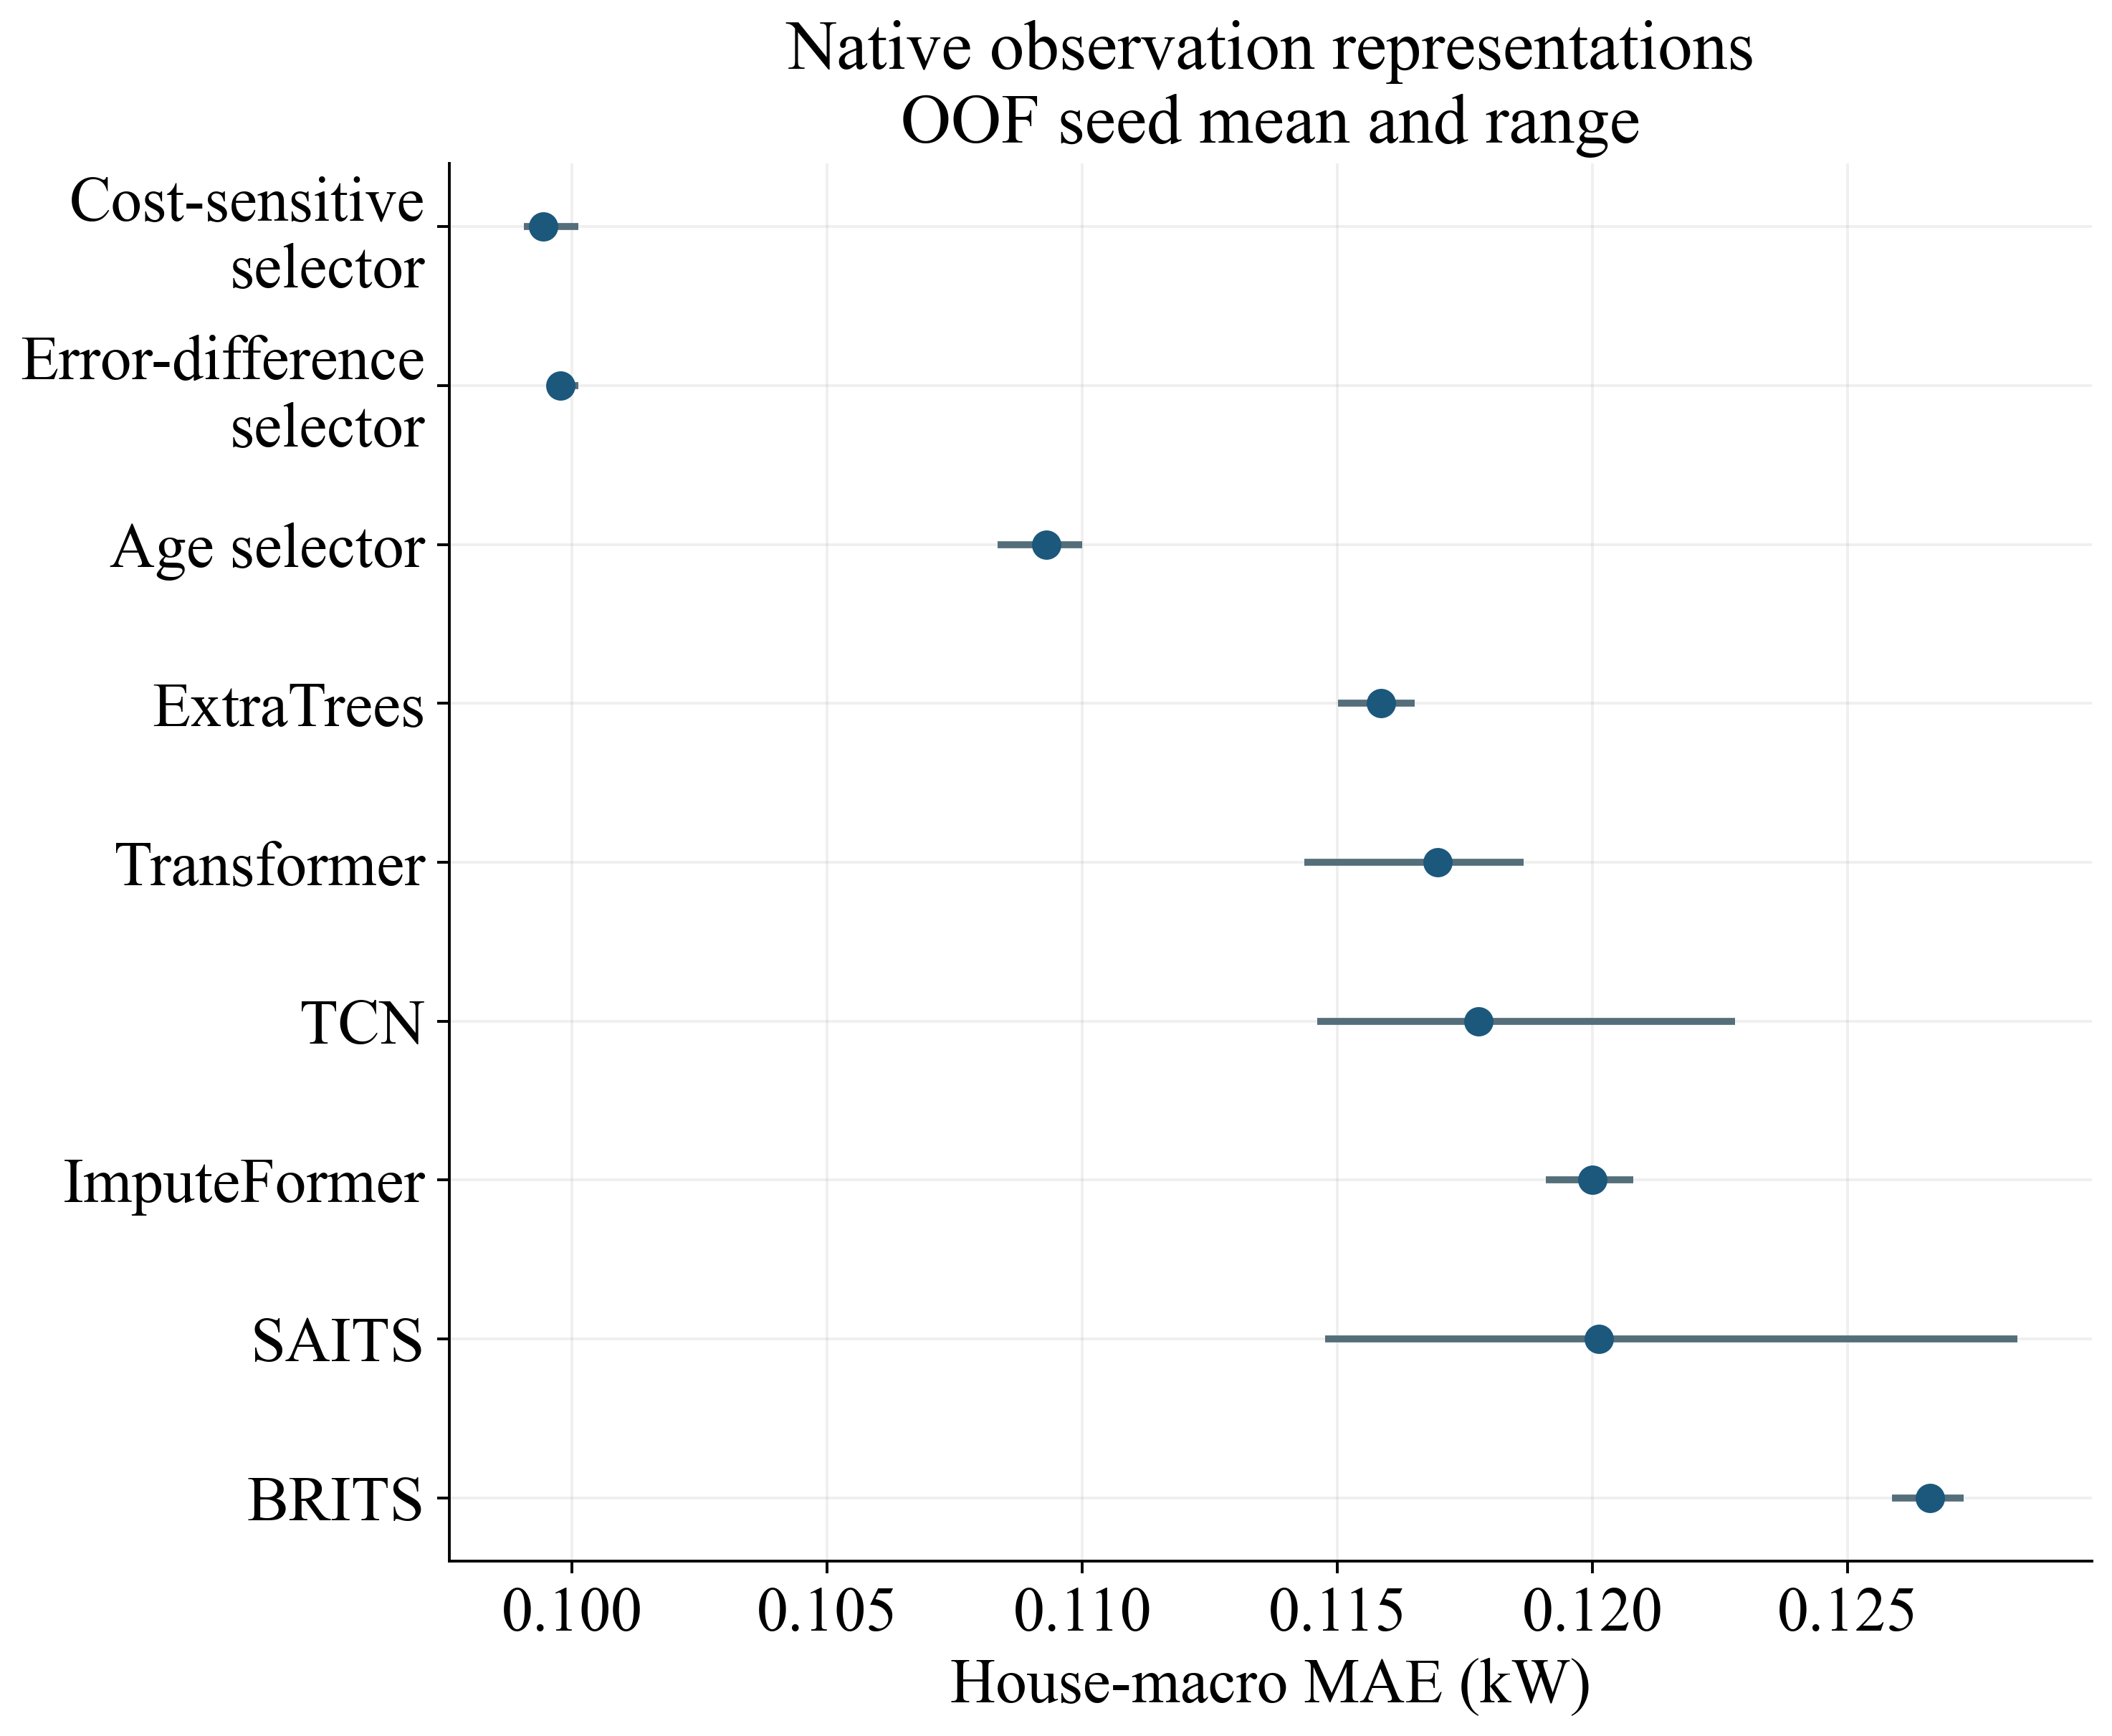

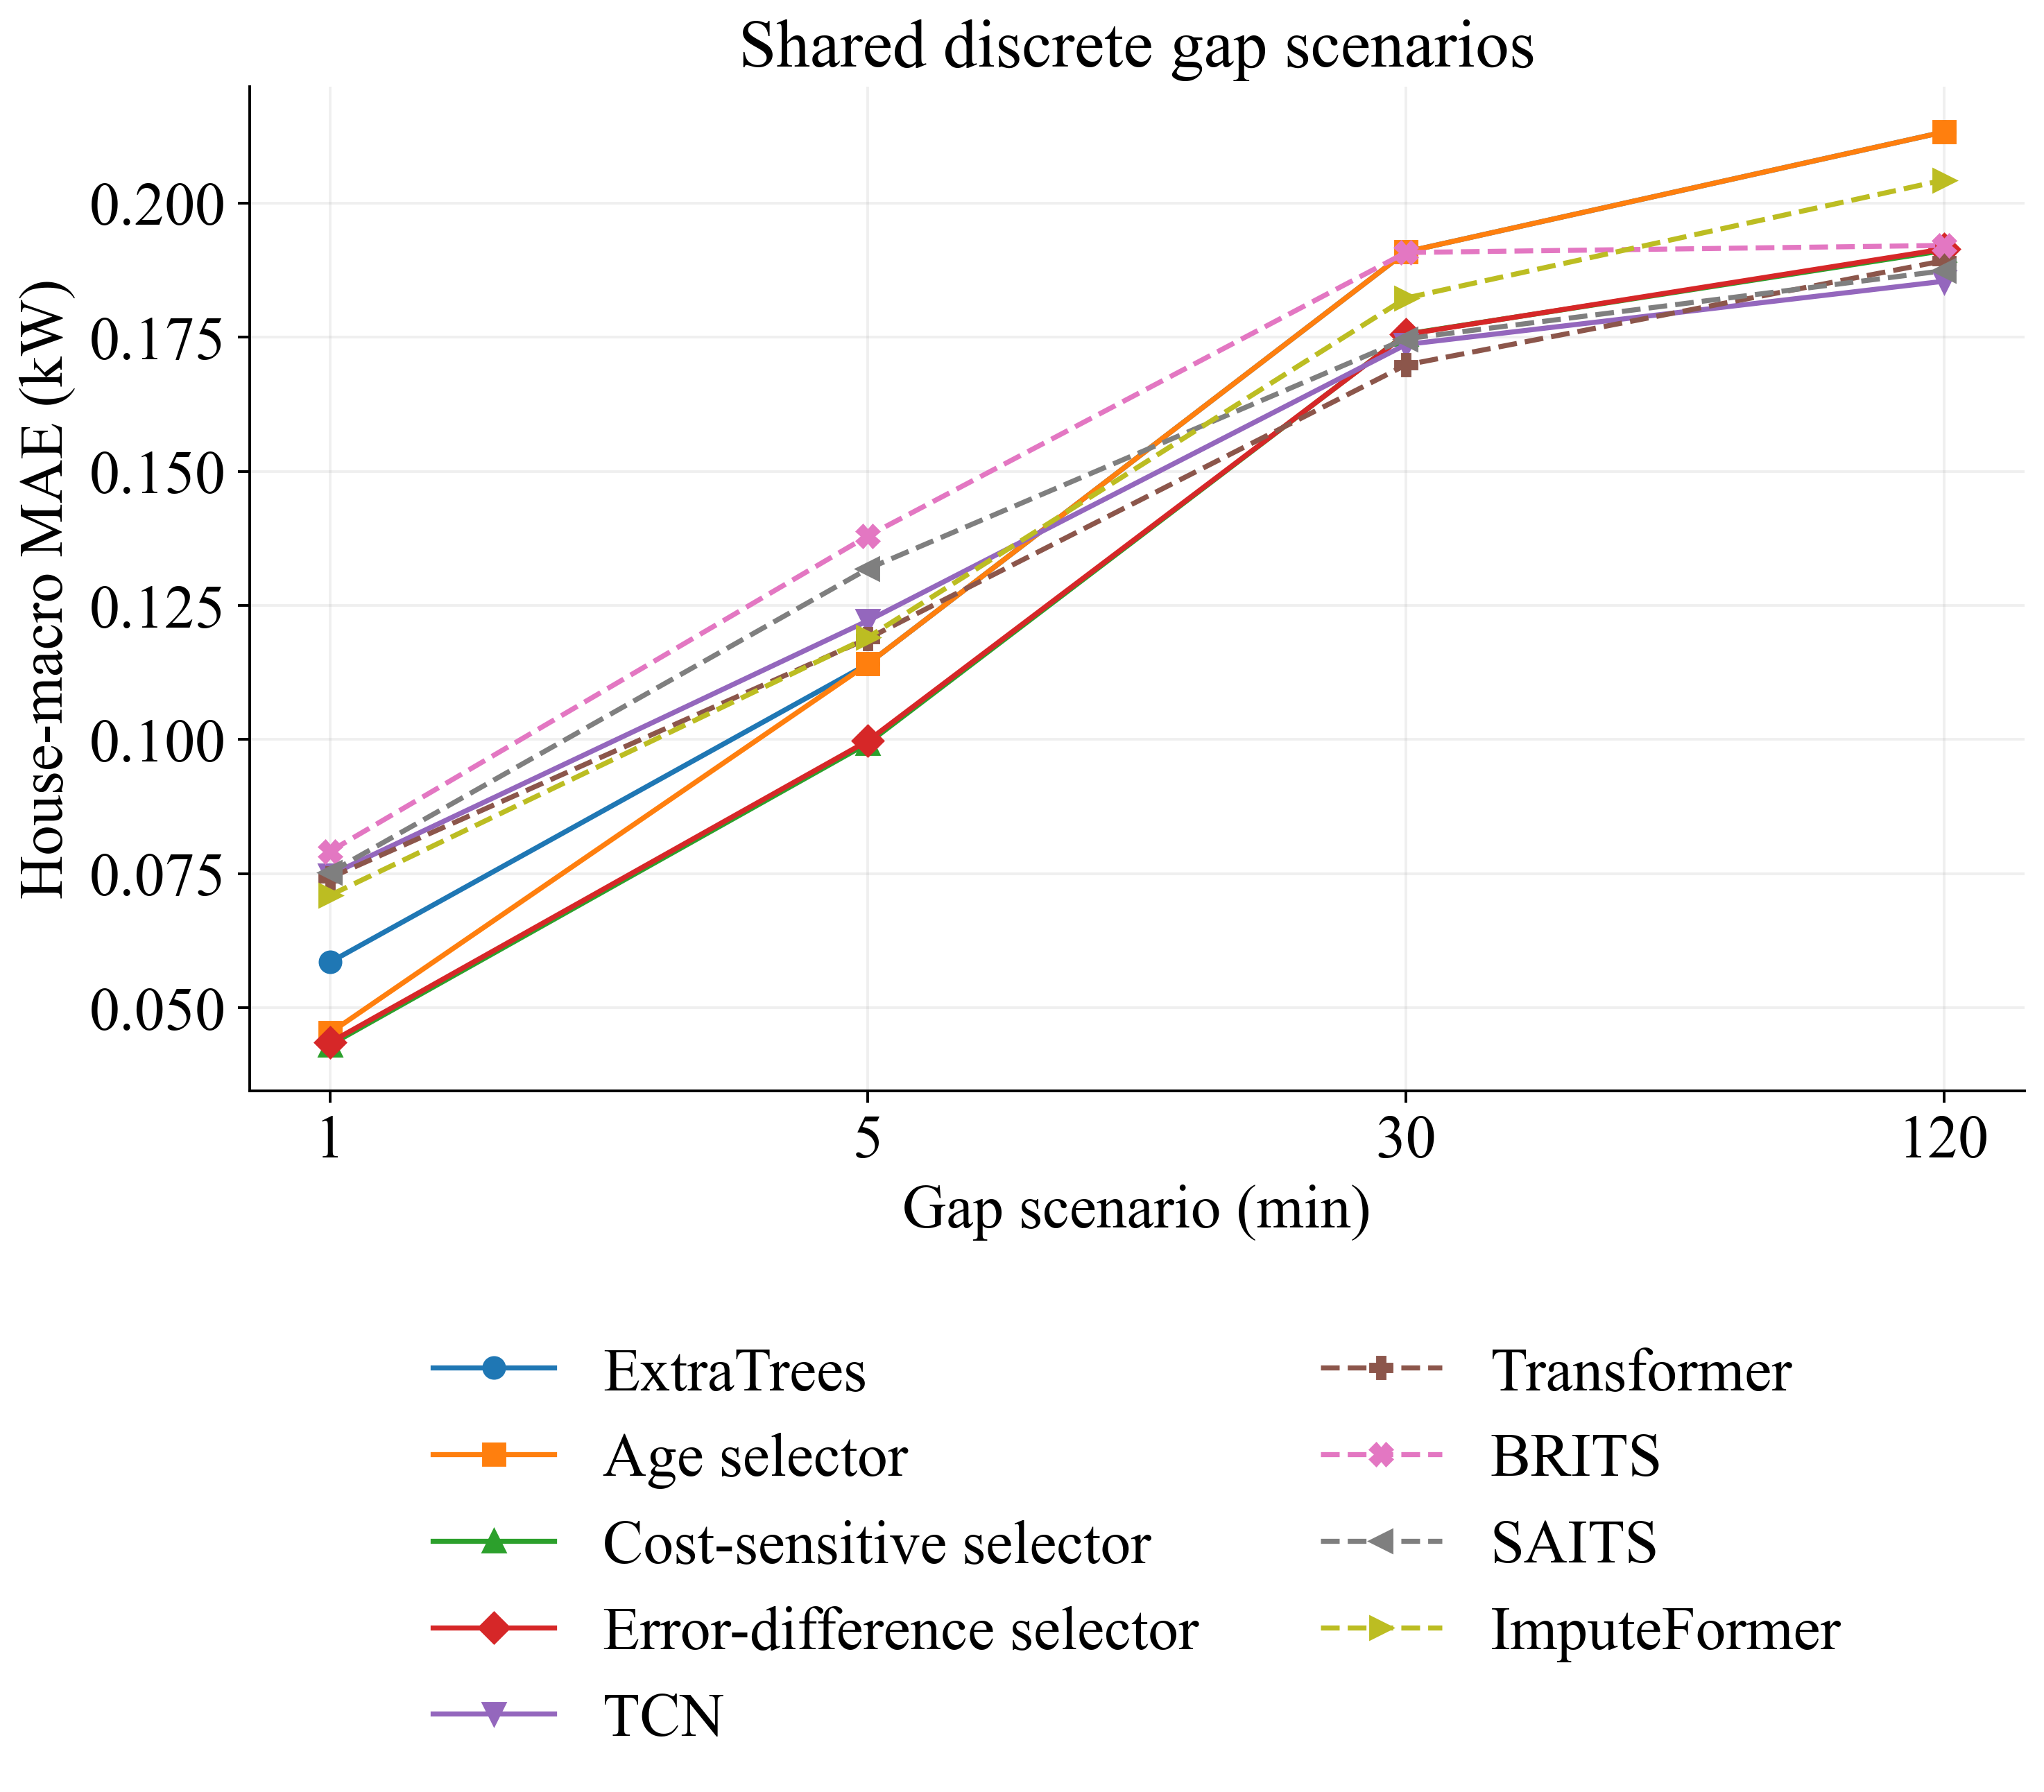

In [4]:
# Isolated presentation renderer; original scientific artifacts remain immutable.
def _presentation_nb04_bcebc7a5():
    # Presentation only: load immutable, previously computed scientific results.
    from pathlib import Path
    import hashlib, json, textwrap
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter, LogLocator
    from IPython.display import display, Image
    from PIL import Image as PILImage
    ROOT = Path.cwd().resolve()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    INPUT_SHA256 = {'Tables/guldana_n3_20261009_v02/04_complete_comparisons/article_modern_comparison.csv': '7a5914ff419f7067464183d9c7aebb292dbb02e67f84d4156471eef37994c920', 'Tables/guldana_n3_20261009_v02/04_complete_comparisons/article_modern_gap_retention_mode.csv': '0dbfd70b5a85ca885bc2180208c74878e134e319513409ec77707b30022d57cd', 'Configs/article_modern_comparison_20261011.json': 'e089a6376a2ae61e2c8be76bbd101488f55467b8143dbd886167e6911a6522ae'}
    for _relative, _expected in INPUT_SHA256.items():
        assert hashlib.sha256((ROOT / _relative).read_bytes()).hexdigest() == _expected, _relative
    assert Path(font_manager.findfont("Times New Roman", fallback_to_default=False)).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
        "ps.fonttype": 42, "axes.formatter.use_mathtext": False})
    _PNG = ROOT / "Figures/PNG/guldana_n3_20261011_presentation/NB04"
    _PDF = ROOT / "Figures/PDF/guldana_n3_20261011_presentation/NB04"
    _PNG.mkdir(parents=True, exist_ok=True)
    _PDF.mkdir(parents=True, exist_ok=True)
    def _label(name, width=22):
        name = str(name).replace("HistGradientBoosting", "Histogram boosting").replace("Mask_only_ExtraTrees", "Mask-only ExtraTrees").replace("Autoregressive_Ridge", "Autoregressive Ridge")
        return "\n".join(textwrap.wrap(name, width=width, break_long_words=False, break_on_hyphens=False))
    def _num(value, decimals=2):
        return f"{value:.{decimals}f}".replace("-", "−")
    def _quiet_axes(ax):
        ax.grid(alpha=.20)
        ax.spines[["top", "right"]].set_visible(False)
    def _export(fig, stem):
        fig.canvas.draw()
        for artist in fig.findobj(Text):
            if artist.get_visible() and artist.get_text():
                assert 18 <= artist.get_fontsize() <= 20, (artist.get_text(), artist.get_fontsize())
                assert artist.get_fontfamily() == ["Times New Roman"], artist.get_fontfamily()
        png = _PNG / (stem + ".png")
        pdf = _PDF / (stem + ".pdf")
        fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.08)
        fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.08)
        with PILImage.open(png) as image:
            assert all(abs(d - 350) < .02 for d in image.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    sota_summary = pd.read_csv(ROOT / "Tables/guldana_n3_20261009_v02/04_complete_comparisons/article_modern_comparison.csv")
    sota_strata = pd.read_csv(ROOT / "Tables/guldana_n3_20261009_v02/04_complete_comparisons/article_modern_gap_retention_mode.csv")
    config = json.loads((ROOT / "Configs/article_modern_comparison_20261011.json").read_text())
    SOTA_MODELS = config["strong_controls"] + config["required_modern_families"]
    assert set(SOTA_MODELS)==set(sota_summary.Model) and len(SOTA_MODELS)==9
    plot_labels={"Causal-TCN":"TCN","Causal-Transformer":"Transformer","BRITS-prefix":"BRITS","SAITS-prefix":"SAITS","ImputeFormer-semantic":"ImputeFormer","CSDI-endpoint":"CSDI","ExtraTrees":"ExtraTrees","Observable age selector":"Age selector","CostSensitiveClassifier":"Cost-sensitive selector","ExpectedErrorDifference":"Error-difference selector"}
    order=sota_summary.sort_values("MAE_kW").Model.tolist()
    plot=sota_summary.set_index("Model").loc[order];y=np.arange(len(order))
    fig,ax=plt.subplots(figsize=(8.8,7.3))
    ax.hlines(y,plot.MAE_seed_min,plot.MAE_seed_max,color="#546E7A",lw=2)
    ax.scatter(plot.MAE_kW,y,color="#1B587C",s=55,zorder=3)
    ax.set_yticks(y,[_label(plot_labels[m]) for m in order]);ax.invert_yaxis()
    ax.set(xlabel="House-macro MAE (kW)",title="Native observation representations\nOOF seed mean and range")
    _quiet_axes(ax);fig.tight_layout()
    _export(fig,"Figure_47_article_modern_comparison_mean")
    fig,ax=plt.subplots(figsize=(8.8,8.2))
    colors=plt.get_cmap("tab10").colors
    markers=["o","s","^","D","v","P","X","<",">"]
    gaps=sorted(sota_strata.loc[sota_strata.Stratum.eq("gap"),"Value"].astype(int).unique())
    for index,model in enumerate(SOTA_MODELS):
        values=sota_strata.loc[sota_strata.Stratum.eq("gap")&sota_strata.Model.eq(model)].assign(Gap=lambda d:d.Value.astype(int)).groupby("Gap")["House-macro MAE (kW)"].mean().reindex(gaps)
        assert values.notna().all()
        ax.plot(range(len(gaps)),values,marker=markers[index],color=colors[index],label=plot_labels[model],ls="-" if index<5 else "--")
    ax.set_xticks(range(len(gaps)),[str(g) for g in gaps]);ax.set(xlabel="Gap scenario (min)",ylabel="House-macro MAE (kW)",title="Shared discrete gap scenarios")
    _quiet_axes(ax)
    ax.legend(loc="upper center",bbox_to_anchor=(.5,-.20),ncol=2,frameon=False)
    fig.tight_layout()
    _export(fig,"Figure_47_article_modern_comparison_gap")

_presentation_nb04_bcebc7a5()


In [17]:
best_row=sota_summary.loc[sota_summary.MAE_kW.idxmin()]
modern_best=sota_summary.loc[sota_summary.Model.isin(SOTA_FAMILIES)].sort_values("MAE_kW").iloc[0]
interpretation=(f"**Development evidence.** Five modern families and four strong controls each have 368,640 seed-specific OOF rows. "
    f"The lowest mean MAE is {best_row.Model}: {best_row.MAE_kW:.6f} kW; among modern methods it is "
    f"{modern_best.Model}: {modern_best.MAE_kW:.6f} kW. Seed ranges are descriptive. "
    "CSDI is incomplete and excluded, with no inferiority claim. Results concern native representations under bounded fitting, "
    "not intrinsic architectural superiority or independent confirmation. All previously inspected tests remain retrospective.")
display(Markdown(interpretation));(V2_TABLES/"article_modern_interpretation.md").write_text(interpretation+"\n")
for path in V2_TABLES.glob("article_modern_*"):
    if path.is_file():sota_record(path)
for fmt in ["PNG","PDF"]:sota_record(ROOT/"Figures"/fmt/V2_RUN/f"Figure_47_article_modern_comparison.{fmt.lower()}")
for relative in ["Configs/article_modern_comparison_20261011.json","Configs/article_scope_20261011.json"]:sota_record(ROOT/relative)
sota_gate={"run_id":V2_RUN,"status":"compact_completed_family_coverage_verified","complete_families":SOTA_FAMILIES,
    "excluded_incomplete":["CSDI-endpoint"],"folds":[1,2,3],"seeds":[17,43,101],"OOF_rows_per_family":368640,
    "fresh_kernel_replay":"required separately","artifacts":sota_artifacts}
(V2_RECORD/"nb04_article_coverage_gate.json").write_text(json.dumps(sota_gate,indent=2)+"\n");


**Development evidence.** Five modern families and four strong controls each have 368,640 seed-specific OOF rows. The lowest mean MAE is CostSensitiveClassifier: 0.099434 kW; among modern methods it is Causal-Transformer: 0.116963 kW. Seed ranges are descriptive. CSDI is incomplete and excluded from the comparison. Results concern native representations under bounded fitting, not intrinsic architectural superiority. All previously inspected tests remain retrospective.

### Reproducibility of retained models

All 45 retained model states are reloaded and each complete deterministic OOF cohort is regenerated without refitting. CSDI is not included.

In [18]:
class RITSCore(nn.Module):
    def __init__(self,width,side_size):
        super().__init__();d=DENSE_CAPACITY
        self.rnn=nn.LSTMCell(2*d+side_size,width)
        self.decay_h=nn.Linear(d,width);self.decay_w=nn.Parameter(torch.empty(d));self.decay_b=nn.Parameter(torch.empty(d))
        self.hist=nn.Linear(width+side_size,d)
        self.feature_weight=nn.Parameter(torch.empty(d,d));self.feature_bias=nn.Parameter(torch.empty(d))
        self.combine=nn.Linear(2*d,d)
        self.register_buffer("off_diagonal",1-torch.eye(d))
        for p in [self.decay_w,self.decay_b,self.feature_weight,self.feature_bias]:
            nn.init.uniform_(p,-1/math.sqrt(d),1/math.sqrt(d))
        self.width=width
    def forward(self,x,m,side,installed):
        b,t,d=x.shape;h=x.new_zeros(b,self.width);c=torch.zeros_like(h)
        delta=x.new_zeros(b,d);last_mask=x.new_zeros(b,d)
        predictions=[];loss=x.sum()*0
        for j in range(t):
            # Recomputed directional elapsed time; unavailable history is never backfilled.
            delta=(1-last_mask)*(delta+1/361)
            h=h*torch.exp(-F.relu(self.decay_h(delta)))
            gamma=torch.exp(-F.relu(delta*self.decay_w+self.decay_b))
            historical=self.hist(torch.cat([h,side[:,j]],-1))
            completed=m[:,j]*x[:,j]+(1-m[:,j])*historical
            cross=F.linear(completed*installed,self.feature_weight*self.off_diagonal,self.feature_bias)
            # Equation 8 of the paper uses sigmoid; the pinned rits.py omits it. This follows the paper.
            alpha=torch.sigmoid(self.combine(torch.cat([gamma,m[:,j]],-1)))
            combined=alpha*cross+(1-alpha)*historical
            loss=loss+sum(masked_mean((p-x[:,j]).abs(),m[:,j]) for p in [historical,cross,combined])/3
            complete=(m[:,j]*x[:,j]+(1-m[:,j])*combined)*installed
            h,c=self.rnn(torch.cat([complete,m[:,j],side[:,j]],-1),(h,c))
            predictions.append(combined);last_mask=m[:,j]
        return torch.stack(predictions,1),loss/t

class BRITSPrefix(nn.Module):
    def __init__(self,width=64,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter()
        self.forward_core=RITSCore(width,self.adapter.side_size)
        self.backward_core=RITSCore(width,self.adapter.side_size)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs)
        forward,lf=self.forward_core(x,m,side,installed)
        backward,lb=self.backward_core(x.flip(1),m.flip(1),side.flip(1),installed);backward=backward.flip(1)
        pred=(forward+backward)/2
        consistency=masked_mean((forward-backward).abs(),installed[:,None].expand_as(pred))
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":(lf+lb)/2,
            "consistency_loss":consistency}

REPLAY_CLASSES={"Causal-TCN":CausalTCN,"Causal-Transformer":CausalTransformer,"BRITS-prefix":BRITSPrefix,
    "SAITS-prefix":SAITSPrefix,"ImputeFormer-semantic":ImputeFormerSemantic}

def replay_complete_modern_states():
    proofs=[];kernel_started=psutil.Process().create_time()
    replay_protocol=ROOT/"Configs/sampler_replay_v2.json";protocol_sha=file_sha256(replay_protocol)
    for fold in [1,2,3]:
        for seed in [17,43,101]:
            build_neural_cache(fold,seed);cache=NeuralInputCache(fold,seed)
            outer=np.flatnonzero(cache.metadata.role.eq("outer_validation").to_numpy());assert len(outer)==40960
            for family in SOTA_FAMILIES:
                historical=family in ["Causal-TCN","Causal-Transformer","BRITS-prefix"] or (family=="SAITS-prefix" and fold<3)
                directory=ROOT/"Models/modern"/(OLD_RUN if historical else V2_RUN)
                predictions=ROOT/"Predictions/development_modern"/(OLD_RUN if historical else V2_RUN)
                stem=f"{family}_fold_{fold}_seed_{seed}";checkpoint=directory/f"{stem}.pt"
                complete=json.loads((directory/f"{stem}_complete.json").read_text())
                assert file_sha256(checkpoint)==complete["checkpoint_sha256"]
                original_path=predictions/f"{stem}.parquet";assert file_sha256(original_path)==complete["prediction_sha256"]
                source_pid=complete.get("execution_kernel_pid",complete.get("kernel_pid"))
                assert source_pid!=os.getpid()
                assert checkpoint.stat().st_mtime<kernel_started,"Independent replay requires a kernel started after the saved fit."
                proof_path=V2_RECORD/f"fresh_modern_replay_{stem}.json"
                if proof_path.exists():
                    proof=json.loads(proof_path.read_text())
                    assert proof["checkpoint_sha256"]==complete["checkpoint_sha256"] and proof["prediction_sha256"]==complete["prediction_sha256"]
                    assert proof["protocol_sha256"]==protocol_sha and proof["maximum_difference"]==0
                    proofs.append(proof);continue
                bundle=torch.load(checkpoint,map_location="cpu",weights_only=True);config=bundle["parameters"]
                original=pd.read_parquet(original_path)
                np.testing.assert_array_equal(original.observation_id,cache.metadata.iloc[outer].observation_id)
                started=time.perf_counter()
                model=REPLAY_CLASSES[family](**config).to(MODERN_DEVICES[family]);model.load_state_dict(bundle["state_dict"]);model.eval()
                point=predict_point_model(model,cache,outer,config,torch.device(MODERN_DEVICES[family]),"Independent full OOF replay")
                np.testing.assert_array_equal(point,original.prediction_kW.to_numpy())
                count=40960;scope="complete deterministic OOF replay";replay_sample_sha=None
                proof={"family":family,"fold":fold,"seed":seed,"checkpoint_sha256":complete["checkpoint_sha256"],
                    "prediction_sha256":complete["prediction_sha256"],"protocol_sha256":protocol_sha,
                    "source_kernel_pid":source_pid,"replay_kernel_pid":os.getpid(),"kernel_started_unix":kernel_started,
                    "checkpoint_modified_unix":checkpoint.stat().st_mtime,"queries":count,"scope":scope,
                    "replay_samples_sha256":replay_sample_sha,"maximum_difference":0.,"seconds":time.perf_counter()-started,
                    "status":"independent_kernel_replay_passed"}
                proof_path.write_text(json.dumps(proof,indent=2)+"\n");proofs.append(proof)
                del model,bundle,original;gc.collect()
                if torch.backends.mps.is_available():torch.mps.empty_cache()
            del cache;gc.collect()
    assert len(proofs)==45
    frame=pd.DataFrame(proofs)
    v2_table(frame.groupby(["family","scope"],as_index=False).agg(Fits=("seed","size"),Replayed_queries=("queries","sum"),
        Maximum_difference=("maximum_difference","max"),Seconds=("seconds","sum")),"article_modern_independent_replay",
        "Fresh-kernel verification of all 45 completed deterministic states and their complete OOF cohorts; no refitting. CSDI is outside this completed-family gate.",precision=6)
    return proofs


In [19]:
modern_independent_replay=replay_complete_modern_states()


In [20]:
assert len(modern_independent_replay)==45
replay_files={str((V2_RECORD/f"fresh_modern_replay_{p['family']}_fold_{p['fold']}_seed_{p['seed']}.json").relative_to(ROOT)):
    file_sha256(V2_RECORD/f"fresh_modern_replay_{p['family']}_fold_{p['fold']}_seed_{p['seed']}.json") for p in modern_independent_replay}
assert len(replay_files)==45
record={"run_id":V2_RUN,"status":"compact_completed_families_independently_verified","fits":45,
    "deterministic_replay_queries":sum(p["queries"] for p in modern_independent_replay),"original_OOF_rows_per_family":368640,
    "excluded_incomplete":["CSDI-endpoint"],"coverage_gate_sha256":file_sha256(V2_RECORD/"nb04_article_coverage_gate.json"),
    "protocol_sha256":file_sha256(ROOT/"Configs/sampler_replay_v2.json"),"replay_proofs":replay_files}
(V2_RECORD/"nb04_article_replay_gate.json").write_text(json.dumps(record,indent=2)+"\n");
display(Markdown("**Completed-family verification passed.** All 45 retained deterministic states reproduced their full OOF predictions. This is checkpoint verification, not new training or a completed CSDI comparison."))
